# Custemer Transaction Prediction


## Problem statement
===========================

The objective of this project is to predict whether a customer will make a transaction in the future, regardless of the transaction amount. The dataset provided contains anonymized features — 200 numerical variables per customer — along with an ID_code and a binary target column.

 1. Target = 1 → Customer will make a transaction.
 2. Target = 0 → Customer will not make a transaction.

Since the features are anonymized, traditional domain‑specific exploratory analysis is not possible. Instead, the focus is on statistical analysis, feature engineering, and machine learning modeling to identify patterns in customer behavior

The final deliverables include:

* A data analysis report highlighting dataset characteristics and preprocessing steps.
* A predictive model comparison report evaluating multiple algorithms (e.g., Logistic Regression, Random Forest, XGBoost) using metrics such as ROC‑AUC, F1‑score, and Precision‑Recall.
* A recommendation of the best model for production deployment.
* A challenges report explaining issues faced (imbalanced data, high dimensionality, anonymized features) and the techniques applied to overcome them.

Data Pipeline Overview:-
------------------------
1. Import Libraries
2. Load Dataset
3. Basic Data Exploration
4. Exploratory Data Analysis (EDA)
5. Data Preprocessing
6. Feature Engineering
7. Model Building
8. Model Evaluation
9. Model Comparison
10. Hyperparameter Tuning(GridSearchCV)
11. Seismologist Suggestions
12. Challenges Faced
13. Conclusion

#### Import Librabies

In [910]:
## Data handling
import numpy as np
import pandas as pd

# Visualization
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

# Ignoring Warnings
import warnings
warnings.filterwarnings('ignore')

# Preprocessing or Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

#models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV

# evaluation
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# metrics
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix



In [911]:
df = pd.read_csv("train(1).csv")

In [912]:
# Basic check

In [913]:
df.head()

,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,train_0,0,8.9255,-6.7863,11.9081,5.0930,11.4607,-9.2834,5.1187,18.6266,...,4.4354,3.9642,3.1364,1.6910,18.5227,-2.3978,7.8784,8.5635,12.7803,-1.0914
1,train_1,0,11.5006,-4.1473,13.8588,5.3890,12.3622,7.0433,5.6208,16.5338,...,7.6421,7.7214,2.5837,10.9516,15.4305,2.0339,8.1267,8.7889,18.3560,1.9518
2,train_2,0,8.6093,-2.7457,12.0805,7.8928,10.5825,-9.0837,6.9427,14.6155,...,2.9057,9.7905,1.6704,1.6858,21.6042,3.1417,-6.5213,8.2675,14.7222,0.3965
3,train_3,0,11.0604,-2.1518,8.9522,7.1957,12.5846,-1.8361,5.8428,14.9250,...,4.4666,4.7433,0.7178,1.4214,23.0347,-1.2706,-2.9275,10.2922,17.9697,-8.9996
4,train_4,0,9.8369,-1.4834,12.8746,6.6375,12.2772,2.4486,5.9405,19.2514,...,-1.4905,9.5214,-0.1508,9.1942,13.2876,-1.5121,3.9267,9.5031,17.9974,-8.8104


In [914]:
df.tail()

,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
199995,train_199995,0,11.4880,-0.4956,8.2622,3.5142,10.3404,11.6081,5.6709,15.1516,...,6.1415,13.2305,3.9901,0.9388,18.0249,-1.7939,2.1661,8.5326,16.6660,-17.8661
199996,train_199996,0,4.9149,-2.4484,16.7052,6.6345,8.3096,-10.5628,5.8802,21.5940,...,4.9611,4.6549,0.6998,1.8341,22.2717,1.7337,-2.1651,6.7419,15.9054,0.3388
199997,train_199997,0,11.2232,-5.0518,10.5127,5.6456,9.3410,-5.4086,4.5555,21.5571,...,4.0651,5.4414,3.1032,4.8793,23.5311,-1.5736,1.2832,8.7155,13.8329,4.1995
199998,train_199998,0,9.7148,-8.6098,13.6104,5.7930,12.5173,0.5339,6.0479,17.0152,...,2.6840,8.6587,2.7337,11.1178,20.4158,-0.0786,6.7980,10.0342,15.5289,-13.9001
199999,train_199999,0,10.8762,-5.7105,12.1183,8.0328,11.5577,0.3488,5.2839,15.2058,...,8.9842,1.6893,0.1276,0.3766,15.2101,-2.4907,-2.2342,8.1857,12.1284,0.1385


In [915]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Columns: 202 entries, ID_code to var_199
dtypes: float64(200), int64(1), object(1)
memory usage: 308.2+ MB


In [916]:
df.dtypes

,0
ID_code,object
target,int64
var_0,float64
var_1,float64
var_2,float64
...,...
var_195,float64
var_196,float64
var_197,float64
var_198,float64


# Observations on Dataset Structure

1. ID_code → object type

* Unique identifier for each customer record (e.g., train_0, train_1).
* Not useful for prediction, but important for tracking rows.

2. target → int64
* Binary classification label.
* 0 → Customer will not make a transaction.
* 1 → Customer will make a transaction.
* This is the dependent variable for modeling.

3. var_0 to var_199 → float64
* 200 anonymized numerical features.
* Each represents hidden customer attributes (behavior, demographics, etc.).
* Since they’re anonymized, treat them as abstract numerical predictors.
* Continuous values (positive and negative), suitable for scaling and statistical analysis.

4. Total Columns → 202
* 1 ID column (ID_code)
* 1 target column (target)
* 200 feature columns (var_0 … var_199)

In [917]:
df.describe()

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
count,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,...,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000
mean,0.100490,10.679914,-1.627622,10.715192,6.796529,11.078333,-5.065317,5.408949,16.545850,0.284162,...,3.234440,7.438408,1.927839,3.331774,17.993784,-0.142088,2.303335,8.908158,15.870720,-3.326537
std,0.300653,3.040051,4.050044,2.640894,2.043319,1.623150,7.863267,0.866607,3.418076,3.332634,...,4.559922,3.023272,1.478423,3.992030,3.135162,1.429372,5.454369,0.921625,3.010945,10.438015
min,0.000000,0.408400,-15.043400,2.117100,-0.040200,5.074800,-32.562600,2.347300,5.349700,-10.505500,...,-14.093300,-2.691700,-3.814500,-11.783400,8.694400,-5.261000,-14.209600,5.960600,6.299300,-38.852800
25%,0.000000,8.453850,-4.740025,8.722475,5.254075,9.883175,-11.200350,4.767700,13.943800,-2.317800,...,-0.058825,5.157400,0.889775,0.584600,15.629800,-1.170700,-1.946925,8.252800,13.829700,-11.208475
50%,0.000000,10.524750,-1.608050,10.580000,6.825000,11.108250,-4.833150,5.385100,16.456800,0.393700,...,3.203600,7.347750,1.901300,3.396350,17.957950,-0.172700,2.408900,8.888200,15.934050,-2.819550
75%,0.000000,12.758200,1.358625,12.516700,8.324100,12.261125,0.924800,6.003000,19.102900,2.937900,...,6.406200,9.512525,2.949500,6.205800,20.396525,0.829600,6.556725,9.593300,18.064725,4.836800
max,1.000000,20.315000,10.376800,19.353000,13.188300,16.671400,17.251600,8.447700,27.691800,10.151300,...,18.440900,16.716500,8.402400,18.281800,27.928800,4.272900,18.321500,12.000400,26.079100,28.500700


In [918]:
df.isnull().sum().sum()

np.int64(0)

## Observation:
The dataset contains missing values.This indicates that the dataset is not cleaned, so need additional data cleaning is required for handling missing values.

In [919]:
df.columns

Index(['ID_code', 'target', 'var_0', 'var_1', 'var_2', 'var_3', 'var_4',
       'var_5', 'var_6', 'var_7',
       ...
       'var_190', 'var_191', 'var_192', 'var_193', 'var_194', 'var_195',
       'var_196', 'var_197', 'var_198', 'var_199'],
      dtype='object', length=202)

# Exploratory Data Analysis

In [920]:
df.head(50)

,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,train_0,0,8.9255,-6.7863,11.9081,5.0930,11.4607,-9.2834,5.1187,18.6266,...,4.4354,3.9642,3.1364,1.6910,18.5227,-2.3978,7.8784,8.5635,12.7803,-1.0914
1,train_1,0,11.5006,-4.1473,13.8588,5.3890,12.3622,7.0433,5.6208,16.5338,...,7.6421,7.7214,2.5837,10.9516,15.4305,2.0339,8.1267,8.7889,18.3560,1.9518
2,train_2,0,8.6093,-2.7457,12.0805,7.8928,10.5825,-9.0837,6.9427,14.6155,...,2.9057,9.7905,1.6704,1.6858,21.6042,3.1417,-6.5213,8.2675,14.7222,0.3965
3,train_3,0,11.0604,-2.1518,8.9522,7.1957,12.5846,-1.8361,5.8428,14.9250,...,4.4666,4.7433,0.7178,1.4214,23.0347,-1.2706,-2.9275,10.2922,17.9697,-8.9996
4,train_4,0,9.8369,-1.4834,12.8746,6.6375,12.2772,2.4486,5.9405,19.2514,...,-1.4905,9.5214,-0.1508,9.1942,13.2876,-1.5121,3.9267,9.5031,17.9974,-8.8104
5,train_5,0,11.4763,-2.3182,12.6080,8.6264,10.9621,3.5609,4.5322,15.2255,...,-6.3068,6.6025,5.2912,0.4403,14.9452,1.0314,-3.6241,9.7670,12.5809,-4.7602
6,train_6,0,11.8091,-0.0832,9.3494,4.2916,11.1355,-8.0198,6.1961,12.0771,...,8.7830,6.4521,3.5325,0.1777,18.3314,0.5845,9.1104,9.1143,10.8869,-3.2097
7,train_7,0,13.5580,-7.9881,13.8776,7.5985,8.6543,0.8310,5.6890,22.3262,...,13.1700,6.5491,3.9906,5.8061,23.1407,-0.3776,4.2178,9.4237,8.6624,3.4806
8,train_8,0,16.1071,2.4426,13.9307,5.6327,8.8014,6.1630,4.4514,10.1854,...,1.4298,14.7510,1.6395,1.4181,14.8370,-1.9940,-1.0733,8.1975,19.5114,4.8453
9,train_9,0,12.5088,1.9743,8.8960,5.4508,13.6043,-16.2859,6.0637,16.8410,...,0.5543,6.3160,1.0371,3.6885,14.8344,0.4467,14.1287,7.9133,16.2375,14.2514


In [921]:
df.duplicated().sum()

np.int64(0)

# Observation
The dataset contains no duplicate values. This indicates that the dataset is not cleaned, so need additional data cleaning is required for handling duplicate values.

In [922]:
df['target'].value_counts()

,count
target,
0,179902
1,20098


In [923]:
df['target'].value_counts(normalize=True) * 100

,proportion
target,
0,89.951
1,10.049


In [924]:
df.loc[df['target'] == 1].head(10)

,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
13,train_13,1,16.3699,1.5934,16.7395,7.3330,12.1450,5.9004,4.8222,20.9729,...,7.4002,7.4031,4.3989,4.0978,17.3638,-1.3022,9.6846,9.0419,15.6064,-10.8529
29,train_29,1,5.3301,-2.6064,13.1913,3.1193,6.6483,-6.5659,5.9064,15.2341,...,5.9215,7.9676,2.3405,1.1482,23.2168,-2.0105,3.7600,9.4513,17.4105,-14.6897
63,train_63,1,7.7072,0.0183,9.9974,8.3524,9.2886,-13.3627,6.0425,10.1108,...,1.5832,5.0039,3.8814,7.4241,21.4844,-0.8297,-3.0468,7.5790,15.7685,5.4769
65,train_65,1,10.5358,-2.5439,8.7394,6.7548,14.4099,-3.8724,5.1584,15.8381,...,4.6648,6.4227,3.4025,-4.0882,14.1174,-0.2472,5.3847,8.6949,15.1340,3.8449
71,train_71,1,6.7547,2.5973,14.2141,8.3514,7.4942,-1.3055,4.2336,15.0243,...,1.4677,3.5935,2.0013,1.5777,18.2820,-4.3408,6.8869,9.3567,18.9013,13.3447
72,train_72,1,8.6470,0.4462,10.9808,10.1859,13.9121,-16.4645,5.2837,13.8396,...,6.6004,13.0969,2.2437,0.6260,23.4572,0.3117,8.1634,7.9248,10.5462,-17.8708
84,train_84,1,14.6825,6.7583,9.7766,9.9461,7.9207,-2.7174,5.4594,20.1579,...,4.3388,10.4738,2.3715,1.5612,18.8488,-1.2723,8.7246,7.7010,15.2861,9.8048
99,train_99,1,9.4554,-3.5377,8.1026,7.4557,12.8716,4.4526,4.1798,19.0480,...,11.4642,9.4043,2.4608,5.1603,21.9483,-0.9451,-5.9209,9.7453,16.3138,-14.8816
119,train_119,1,12.6769,-0.4517,6.7371,9.4245,12.7274,3.0585,5.7957,15.5797,...,1.6877,9.6047,0.7896,10.2968,20.0513,-0.9380,10.2037,7.7482,13.2917,-11.2830
120,train_120,1,7.6382,-6.3480,8.3145,7.6210,10.6435,-8.8025,7.1044,20.6761,...,-1.6585,13.7319,0.8665,10.6605,24.4835,0.1339,-4.0743,7.8159,19.4458,-19.9356


In [925]:
df["target"].sum()/df.shape[0]*100

np.float64(10.049)

<Axes: xlabel='var_186', ylabel='Count'>

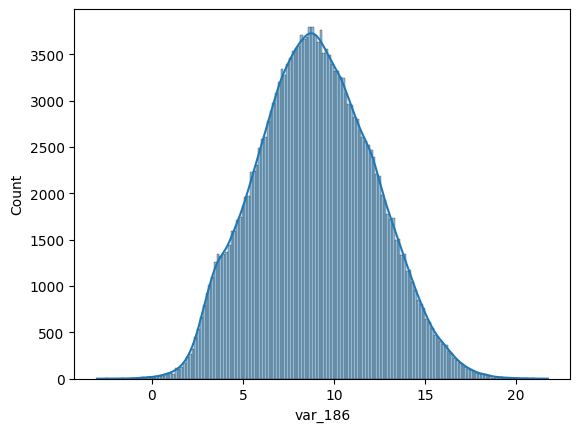

In [926]:
sns.histplot(df['var_186'], kde=True)


In [927]:
df['var_186'].skew()

np.float64(0.10470179525909705)

In [928]:
df['var_186'] = df['var_186'].fillna(df['var_186'].median())

<Axes: xlabel='var_187', ylabel='Count'>

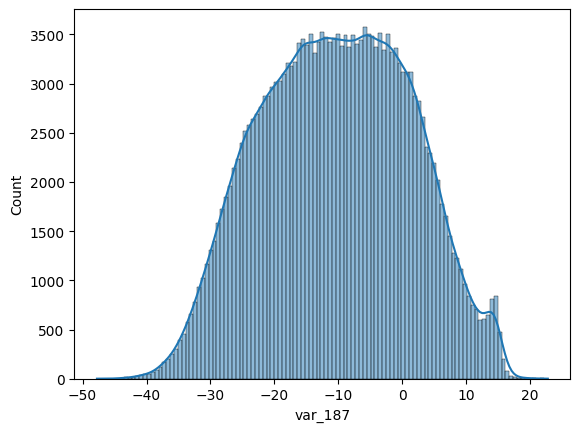

In [929]:
sns.histplot(df['var_187'], kde=True)

In [930]:
df['var_187'].skew()

np.float64(-0.02118021879630902)

In [931]:
df['var_187'] = df['var_187'].fillna(df['var_187'].mean())

<Axes: xlabel='var_188', ylabel='Count'>

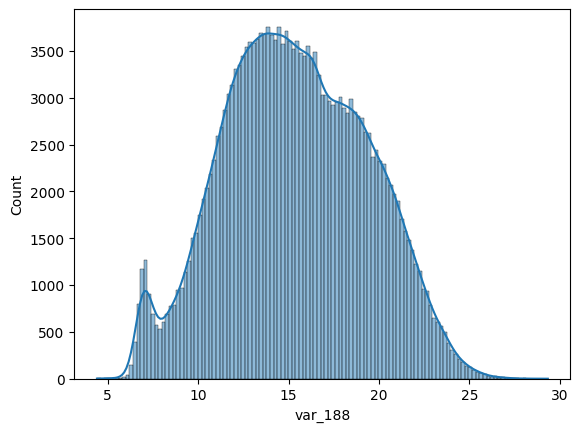

In [932]:
sns.histplot(df['var_188'], kde=True)

In [933]:
df.var_188.skew()

np.float64(0.03603628574776229)

In [934]:
df['var_188'] = df['var_188'].fillna(df['var_188'].mean())

<Axes: xlabel='var_189', ylabel='Count'>

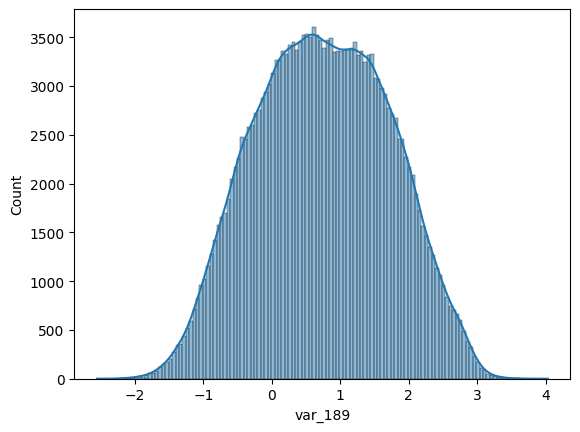

In [935]:
sns.histplot(df['var_189'], kde=True)

In [936]:
df.var_189.skew()

np.float64(-0.0071922224980769155)

In [937]:
df['var_189'] = df['var_189'].fillna(df['var_189'].mean())

<Axes: xlabel='var_190', ylabel='Count'>

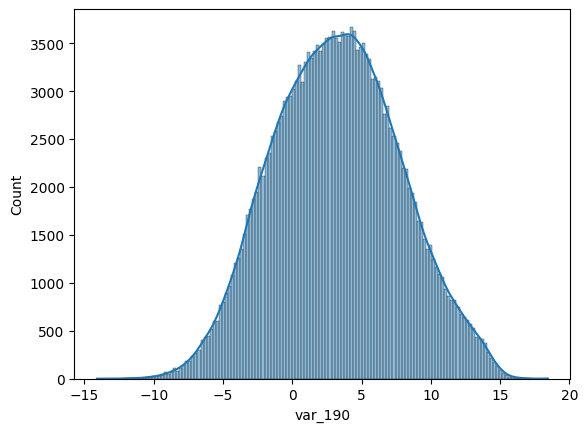

In [938]:
sns.histplot(df['var_190'], kde=True)

In [939]:
df['var_190'].skew()

np.float64(0.0516759551010008)

In [940]:
df['var_190'] = df['var_190'].fillna(df['var_190'].mean())

<Axes: xlabel='var_191', ylabel='Count'>

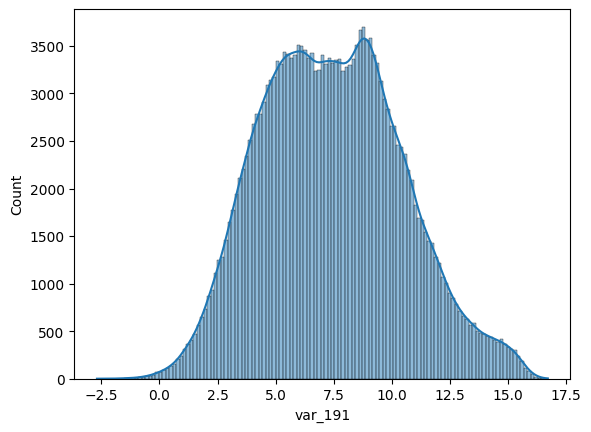

In [941]:
sns.histplot(df['var_191'], kde=True)

In [942]:
df.var_191.skew()

np.float64(0.20927811535887536)

In [943]:
df['var_191'] = df['var_191'].fillna(df['var_191'].median())

<Axes: xlabel='var_192', ylabel='Count'>

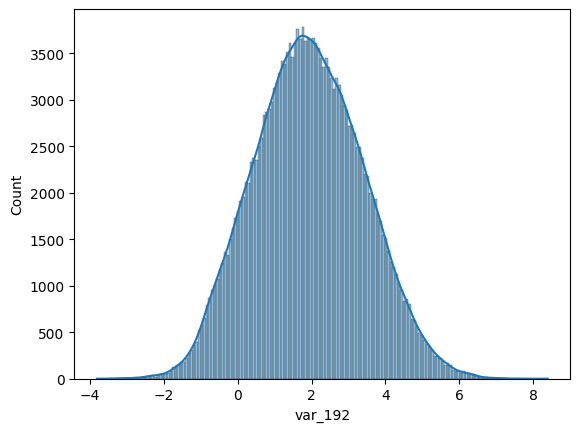

In [944]:
sns.histplot(df['var_192'], kde=True)

In [945]:
df.var_192.skew()

np.float64(0.08396709930009383)

In [946]:
df['var_192'] = df['var_192'].fillna(df['var_192'].mean())

<Axes: xlabel='var_193', ylabel='Count'>

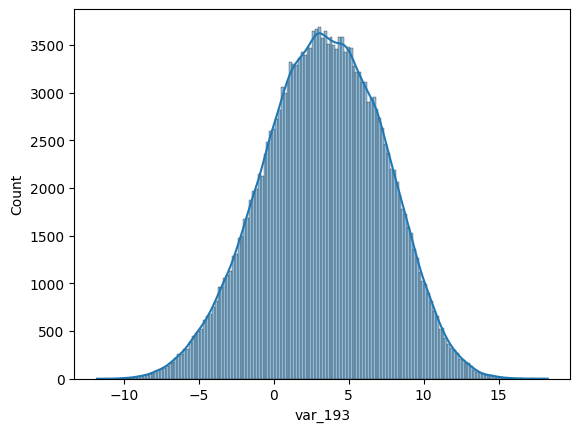

In [947]:
sns.histplot(df['var_193'], kde=True)

In [948]:
df['var_193'].skew()

np.float64(-0.10888900998522269)

In [949]:
df['var_193'] = df['var_193'].fillna(df['var_193'].median())

<Axes: xlabel='var_194', ylabel='Count'>

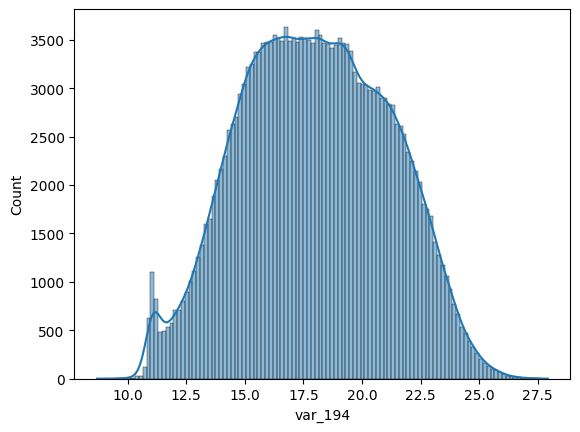

In [950]:
sns.histplot(df['var_194'], kde=True)

In [951]:
df.var_194.skew()

np.float64(-9.65561988322053e-05)

In [952]:
df['var_194'] = df['var_194'].fillna(df['var_194'].mean())

<Axes: xlabel='var_195', ylabel='Count'>

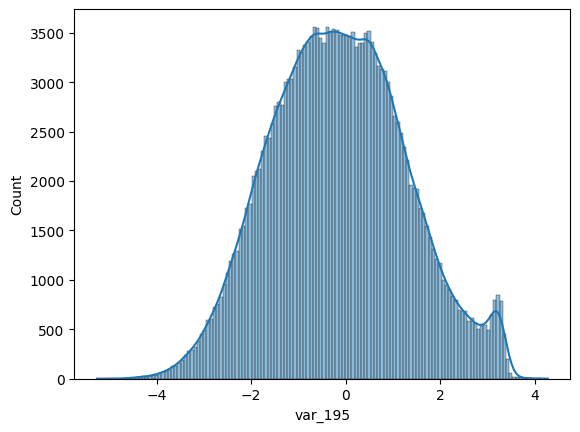

In [953]:
sns.histplot(df['var_195'], kde=True)

In [954]:
df['var_195'].skew()

np.float64(0.12404775925287594)

In [955]:
df['var_195'] = df['var_195'].fillna(df['var_195'].median())

<Axes: xlabel='var_196', ylabel='Count'>

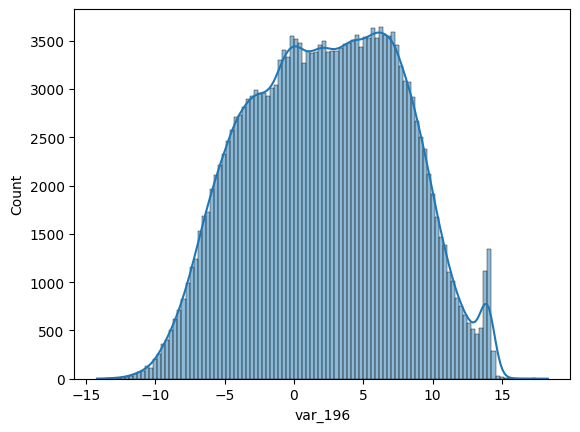

In [956]:
sns.histplot(df['var_196'], kde=True)

In [957]:
df.var_196.skew()

np.float64(-0.032527158247326785)

In [958]:
df['var_196'] = df['var_196'].fillna(df['var_196'].mean())

<Axes: xlabel='var_197', ylabel='Count'>

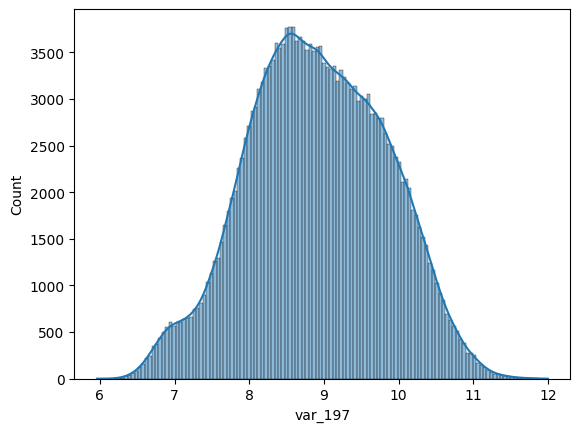

In [959]:
sns.histplot(df['var_197'], kde=True)

In [960]:
df.var_197.skew()

np.float64(-0.03109353103291505)

In [961]:
df["var_197"] = df["var_197"].fillna(df["var_197"].mean())

<Axes: xlabel='var_198', ylabel='Count'>

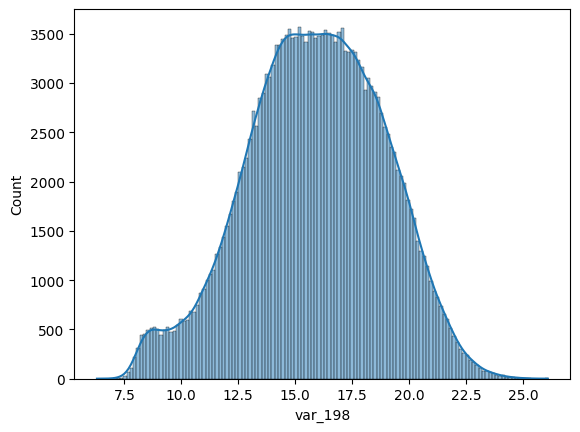

In [962]:
sns.histplot(df['var_198'], kde=True)

In [963]:
df.var_198.skew()

np.float64(-0.17015580933204194)

In [964]:
df['var_198'] = df['var_198'].fillna(df['var_198'].median())

<Axes: xlabel='var_199', ylabel='Count'>

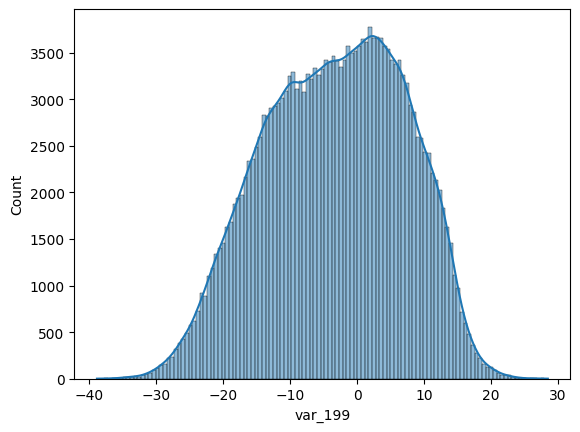

In [965]:
sns.histplot(df['var_199'], kde=True)

In [966]:
df.var_199.skew()

np.float64(-0.16434895418553952)

In [967]:
df["var_199"] = df["var_199"].fillna(df["var_199"].median())

<Axes: xlabel='var_70', ylabel='Count'>

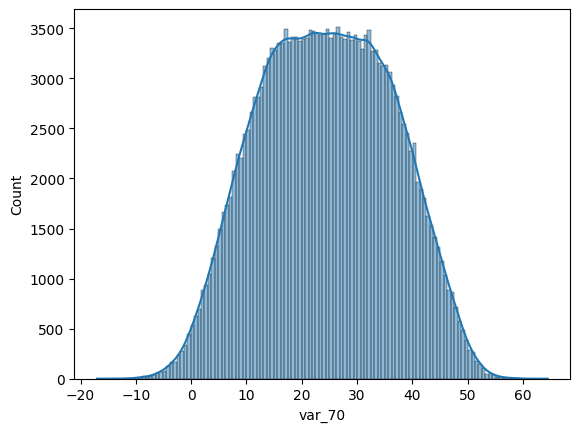

In [968]:
sns.histplot(x = df["var_70"], kde=True)

In [969]:
df.var_70.skew()

np.float64(-0.004895859628794497)

In [970]:
df["var_70"] = df["var_70"].fillna(df["var_70"].mean())

<Axes: xlabel='var_71', ylabel='Count'>

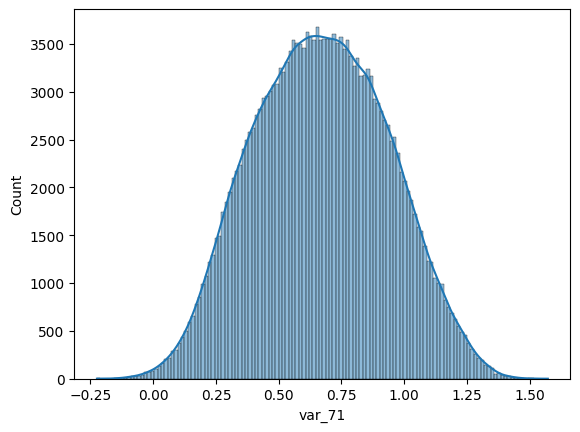

In [971]:
sns.histplot(x = df["var_71"], kde=True)

In [972]:
df.var_71.skew()

np.float64(0.028484770336642654)

In [973]:
df["var_71"] = df["var_71"].fillna(df["var_71"].mean())

<Axes: xlabel='var_72', ylabel='Count'>

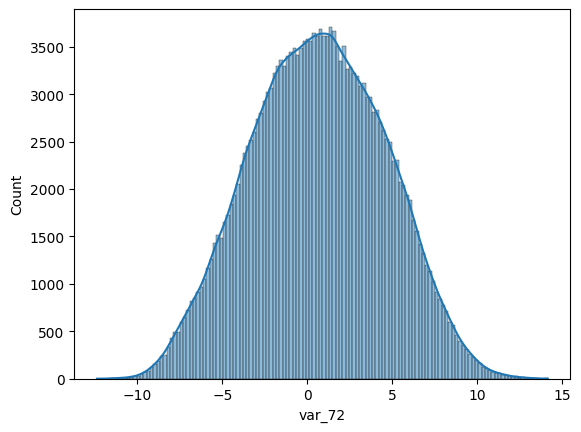

In [974]:
sns.histplot(x = df["var_72"], kde=True)

In [975]:
df["var_72"] = df["var_72"].fillna(df["var_72"].mean())

<Axes: xlabel='var_73', ylabel='Count'>

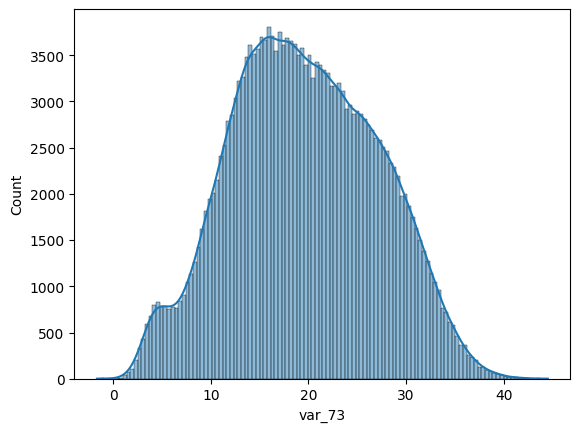

In [976]:
sns.histplot(x = df["var_73"], kde=True)

In [977]:
df.var_73.skew()

np.float64(0.06053498127491387)

In [978]:
df["var_73"] = df["var_73"].fillna(df["var_73"].mean())

<Axes: xlabel='var_74', ylabel='Count'>

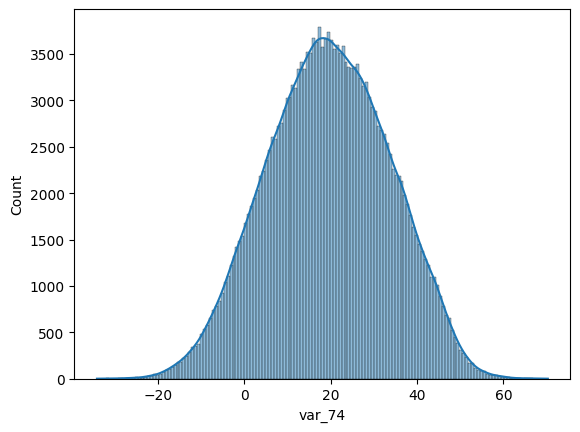

In [979]:
sns.histplot(x = df["var_74"], kde=True)

In [980]:
df.var_74.skew()

np.float64(-0.047618635155856265)

In [981]:
df["var_74"] = df["var_74"].fillna(df["var_74"].mean())

<Axes: xlabel='var_75', ylabel='Count'>

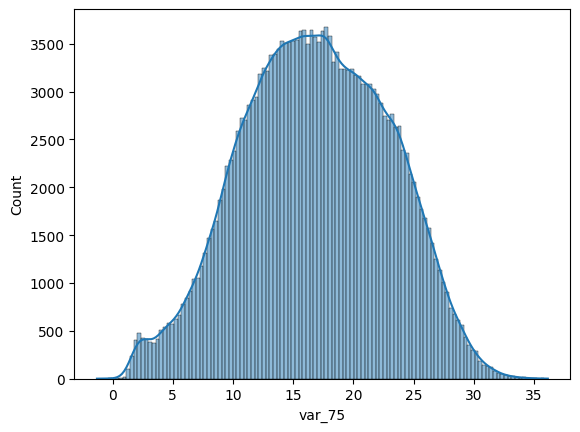

In [982]:
sns.histplot(x = df["var_75"], kde=True)

In [983]:
df.var_75.skew()

np.float64(-0.0699829134211245)

In [984]:
df["var_75"] = df["var_75"].fillna(df["var_75"].mean())

<Axes: xlabel='var_76', ylabel='Count'>

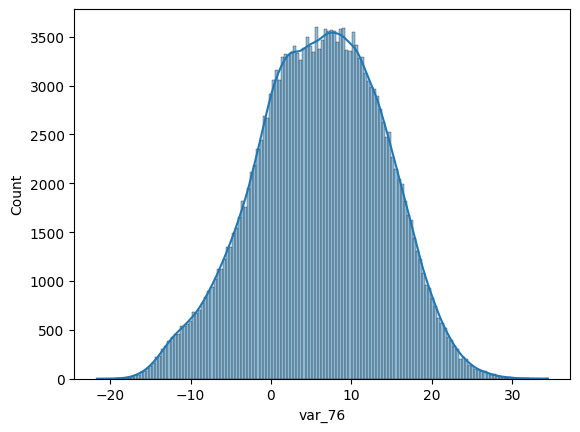

In [985]:
sns.histplot(x = df["var_76"], kde=True)

In [986]:
df.var_76.skew()

np.float64(-0.14800260709246157)

In [987]:
df["var_76"] = df["var_76"].fillna(df["var_76"].median())

<Axes: xlabel='var_77', ylabel='Count'>

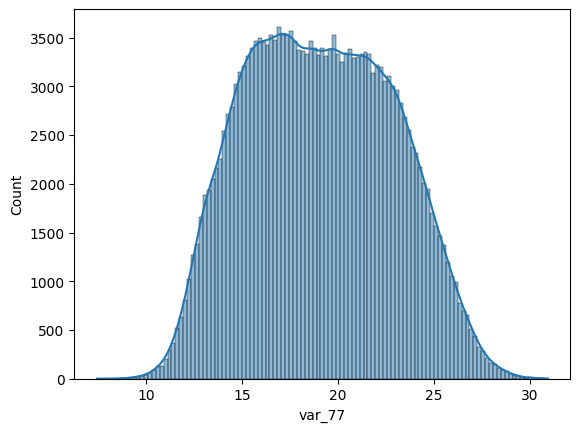

In [988]:
sns.histplot(x = df["var_77"], kde=True)

In [989]:
df.var_77.skew()

np.float64(0.09504143658473356)

In [990]:
df["var_77"] = df["var_77"].fillna(df["var_77"].mean())

<Axes: xlabel='var_78', ylabel='Count'>

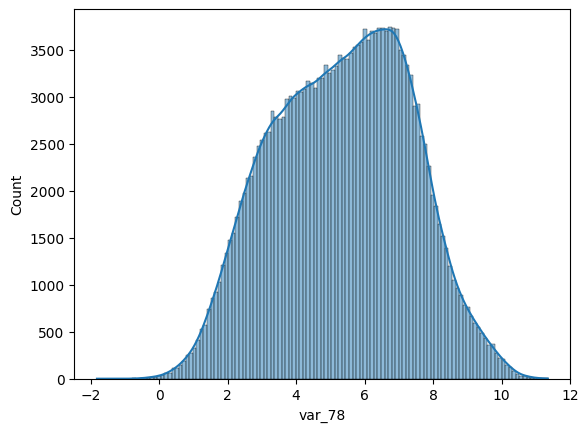

In [991]:
sns.histplot(x = df["var_78"], kde=True)

In [992]:
df.var_78.skew()

np.float64(-0.0643533685336033)

In [993]:
df["var_78"] = df["var_78"].fillna(df["var_78"].mean())

<Axes: xlabel='var_79', ylabel='Count'>

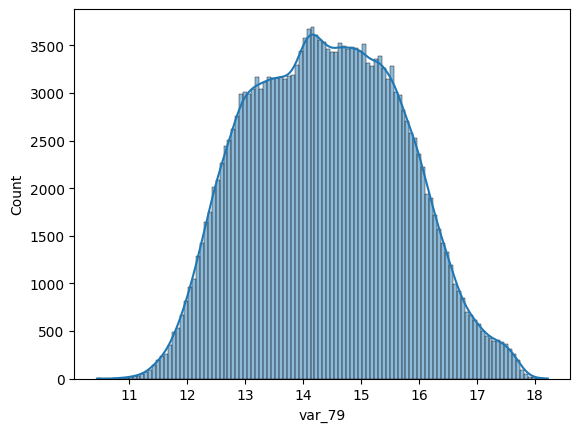

In [994]:
sns.histplot(x = df["var_79"], kde=True)

In [995]:
df.var_79.skew()

np.float64(0.09026623107854016)

In [996]:
df["var_79"] = df["var_79"].fillna(df["var_79"].mean())

<Axes: xlabel='var_80', ylabel='Count'>

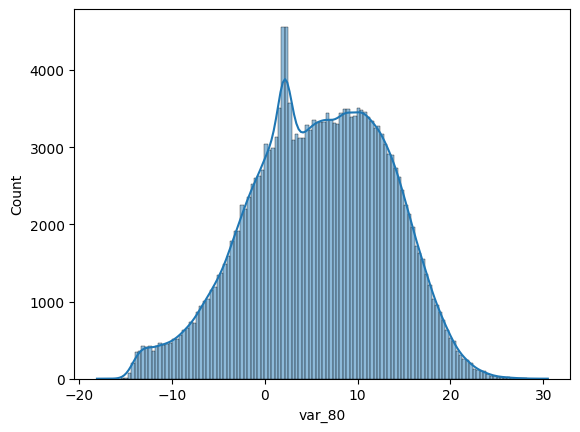

In [997]:
sns.histplot(x = df["var_80"], kde=True)

In [998]:
df['var_80'].skew()

np.float64(-0.2202357228952602)

In [999]:
df["var_80"] = df["var_80"].fillna(df["var_80"].median())

<Axes: xlabel='var_81', ylabel='Count'>

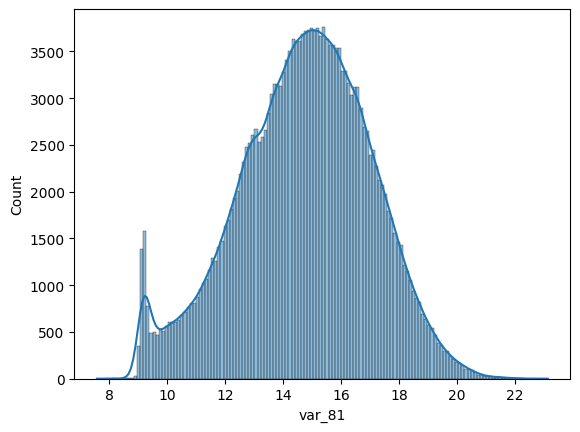

In [1000]:
sns.histplot(x = df["var_81"], kde=True)

In [1001]:
df.var_81.skew()

np.float64(-0.23252584722521014)

In [1002]:
df["var_81"] = df["var_81"].fillna(df["var_81"].median())

<Axes: xlabel='var_82', ylabel='Count'>

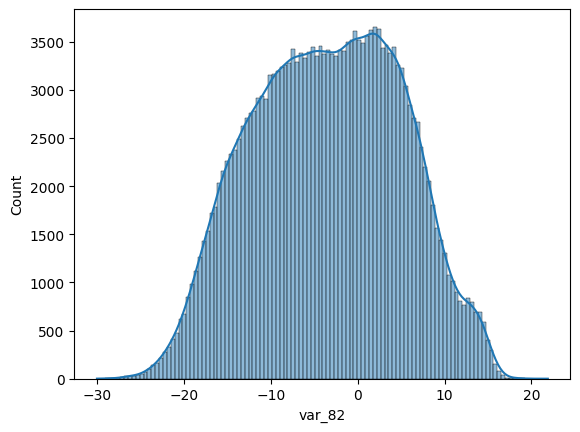

In [1003]:
sns.histplot(x = df["var_82"], kde=True)

In [1004]:
df.var_82.skew()

np.float64(-0.04825299745878791)

In [1005]:
df["var_82"] = df["var_82"].fillna(df["var_82"].mean())

<Axes: xlabel='var_83', ylabel='Count'>

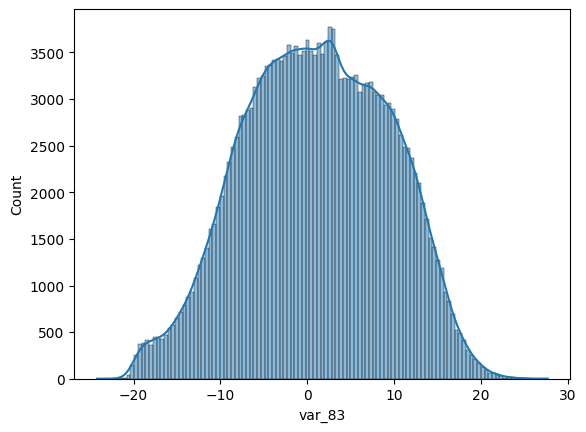

In [1006]:
sns.histplot(x = df["var_83"], kde=True)

In [1007]:
df.var_83.skew()

np.float64(-0.08123110747364484)

In [1008]:
df["var_83"] = df["var_83"].fillna(df["var_83"].mean())

<Axes: xlabel='var_84', ylabel='Count'>

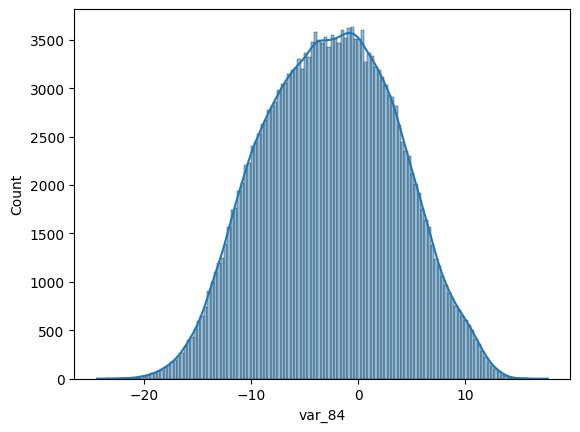

In [1009]:
sns.histplot(x = df["var_84"], kde=True)

In [1010]:
df.var_84.skew()

np.float64(-0.014144739735923869)

In [1011]:
df["var_84"] = df["var_84"].fillna(df["var_84"].mean())

<Axes: xlabel='var_85', ylabel='Count'>

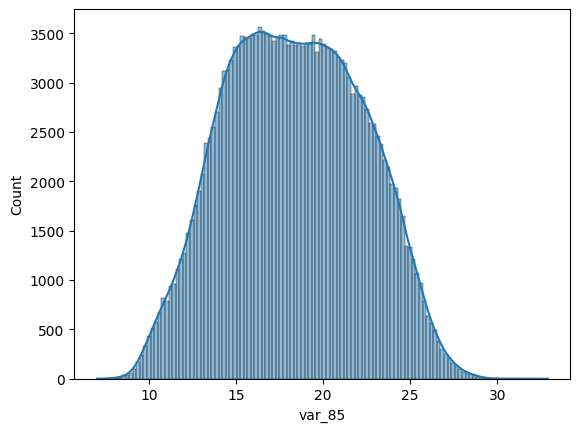

In [1012]:
sns.histplot(x = df["var_85"], kde=True)

In [1013]:
df.var_85.skew()

np.float64(0.03869384441173822)

In [1014]:
df["var_85"] = df["var_85"].fillna(df["var_85"].mean())

<Axes: xlabel='var_86', ylabel='Count'>

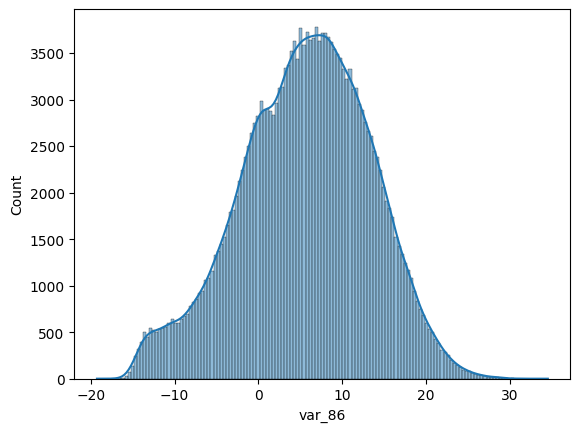

In [1015]:
sns.histplot(x = df["var_86"], kde=True)

In [1016]:
df.var_86.skew()

np.float64(-0.2168591110106961)

In [1017]:
df["var_86"] = df["var_86"].fillna(df["var_86"].median())

<Axes: xlabel='var_87', ylabel='Count'>

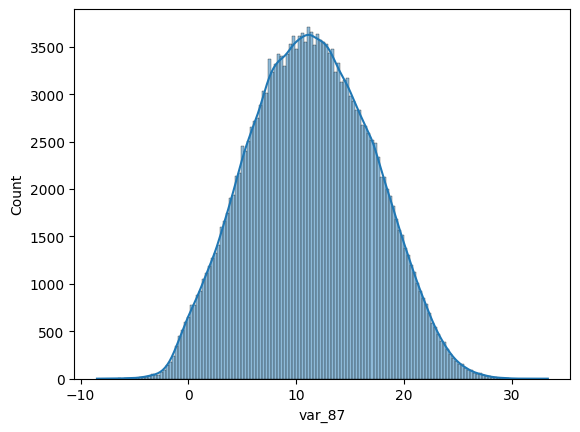

In [1018]:
sns.histplot(x = df["var_87"], kde=True)

In [1019]:
df.var_87.skew()

np.float64(0.05209895533846918)

In [1020]:
df["var_87"] = df["var_87"].fillna(df["var_87"].mean())

<Axes: xlabel='var_88', ylabel='Count'>

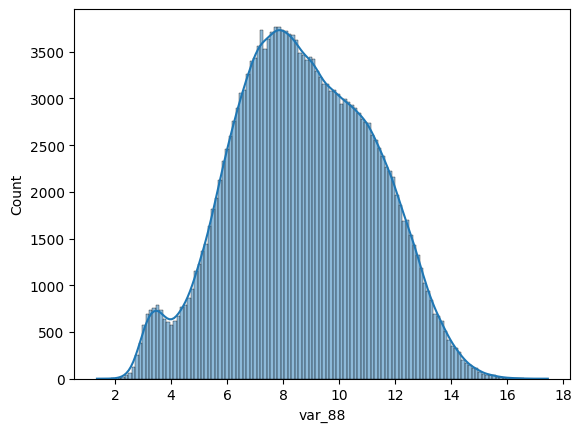

In [1021]:
sns.histplot(x = df["var_88"], kde=True)

In [1022]:
df.var_88.skew()

np.float64(0.004620021332344166)

In [1023]:
df["var_88"] = df["var_88"].fillna(df["var_88"].mean())

<Axes: xlabel='var_89', ylabel='Count'>

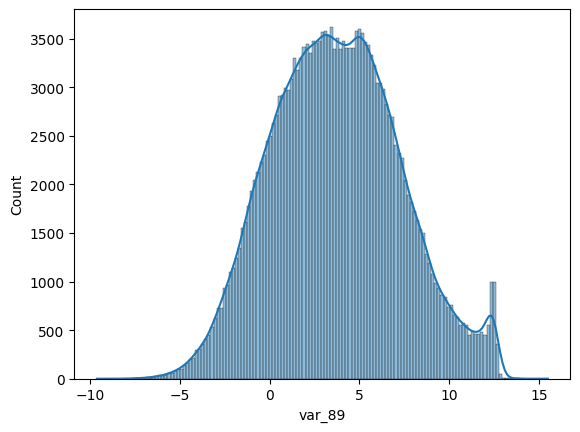

In [1024]:
sns.histplot(x = df["var_89"], kde=True)

In [1025]:
df.var_89.skew()

np.float64(0.15092180905506153)

In [1026]:
df["var_89"] = df["var_89"].fillna(df["var_89"].median())

<Axes: xlabel='var_90', ylabel='Count'>

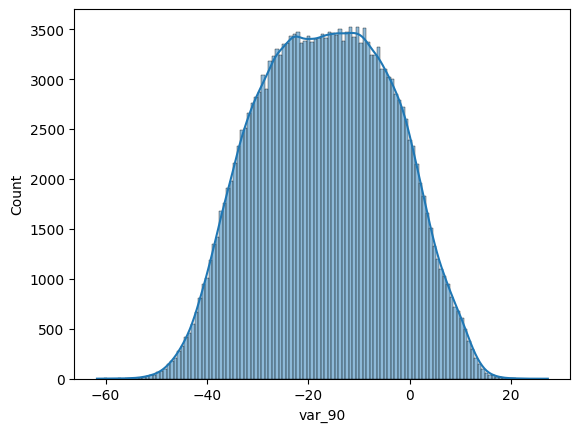

In [1027]:
sns.histplot(x = df["var_90"], kde=True)

In [1028]:
df.var_90.skew()

np.float64(-0.01042614012832741)

In [1029]:
df["var_90"] = df["var_90"].fillna(df["var_90"].mean())

<Axes: xlabel='var_91', ylabel='Count'>

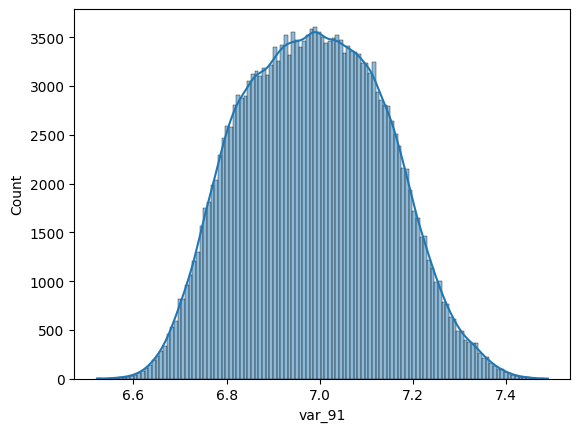

In [1030]:
sns.histplot(x = df["var_91"], kde=True)

In [1031]:
df.var_91.skew()

np.float64(0.07781061665640593)

In [1032]:
df["var_91"] = df["var_91"].fillna(df["var_91"].mean())

<Axes: xlabel='var_92', ylabel='Count'>

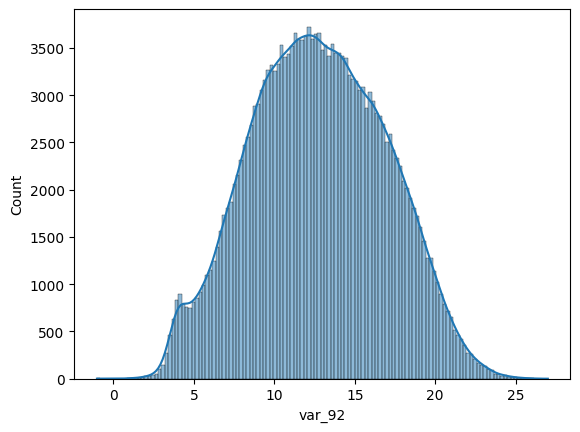

In [1033]:
sns.histplot(x = df["var_92"], kde=True)

In [1034]:
df.var_92.skew()

np.float64(0.02644114849472089)

In [1035]:
df["var_92"] = df["var_92"].fillna(df["var_92"].mean())

<Axes: xlabel='var_93', ylabel='Count'>

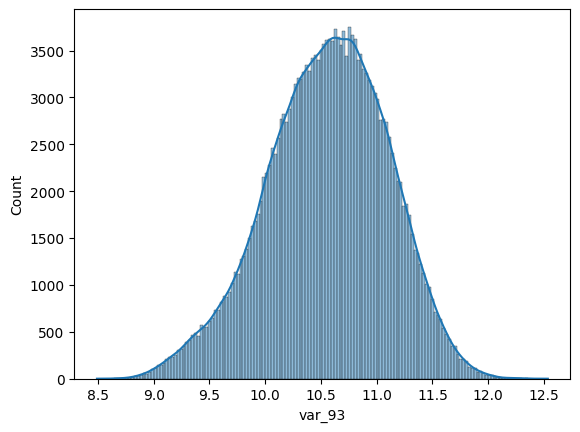

In [1036]:
sns.histplot(x = df["var_93"], kde=True)

In [1037]:
df.var_93.skew()

np.float64(-0.2380906435475246)

In [1038]:
df["var_93"] = df["var_93"].fillna(df["var_93"].median())

<Axes: xlabel='var_94', ylabel='Count'>

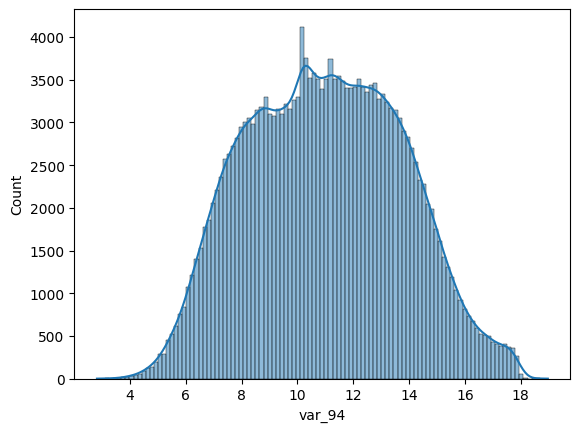

In [1039]:
sns.histplot(x = df["var_94"], kde=True)

In [1040]:
df.var_94.skew()

np.float64(0.07390804334794293)

In [1041]:
df["var_94"] = df["var_94"].fillna(df["var_94"].mean())

<Axes: xlabel='var_95', ylabel='Count'>

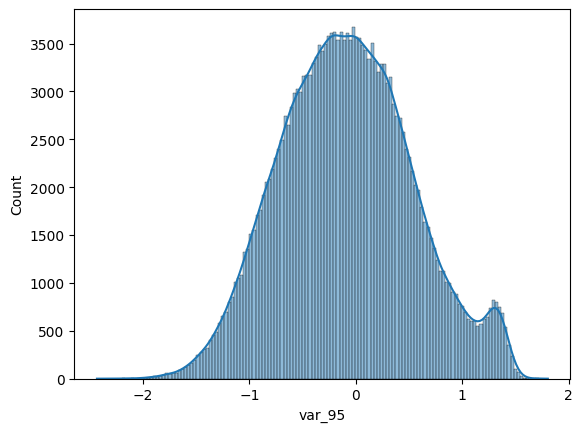

In [1042]:
sns.histplot(x = df["var_95"], kde=True)

In [1043]:
df.var_95.skew()

np.float64(0.13996655974623623)

In [1044]:
df["var_95"] = df["var_95"].fillna(df["var_95"].median())

<Axes: xlabel='var_96', ylabel='Count'>

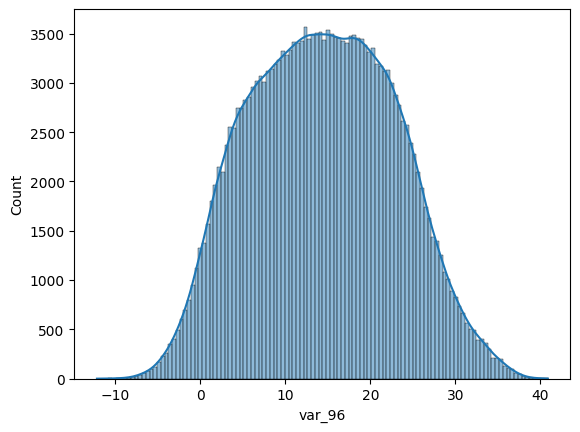

In [1045]:
sns.histplot(x = df["var_96"], kde=True)

In [1046]:
df.var_96.skew()

np.float64(0.0607341830718022)

In [1047]:
df["var_96"] = df["var_96"].fillna(df["var_96"].mean())

<Axes: xlabel='var_97', ylabel='Count'>

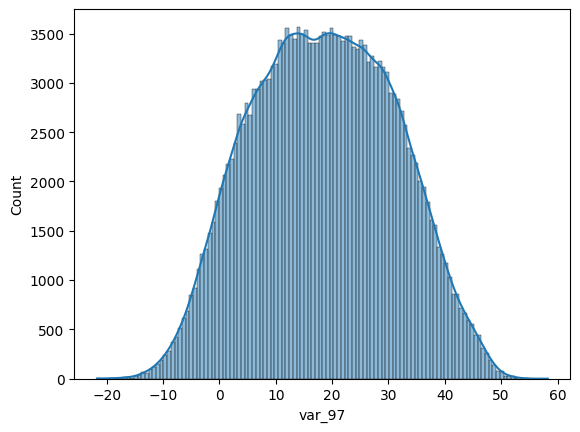

In [1048]:
sns.histplot(x = df["var_97"], kde=True)

In [1049]:
df.var_97.skew()

np.float64(0.01577921711255666)

In [1050]:
df["var_97"] = df["var_97"].fillna(df["var_97"].mean())

<Axes: xlabel='var_98', ylabel='Count'>

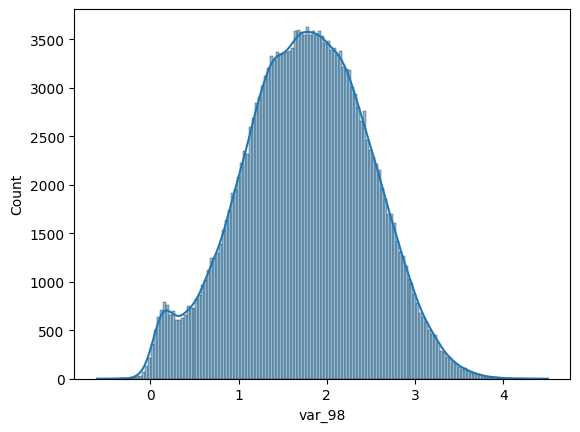

In [1051]:
sns.histplot(x = df["var_98"], kde=True)

In [1052]:
df.var_98.skew()

np.float64(-0.10597330590990231)

In [1053]:
df["var_98"] = df["var_98"].fillna(df["var_98"].median())

<Axes: xlabel='var_99', ylabel='Count'>

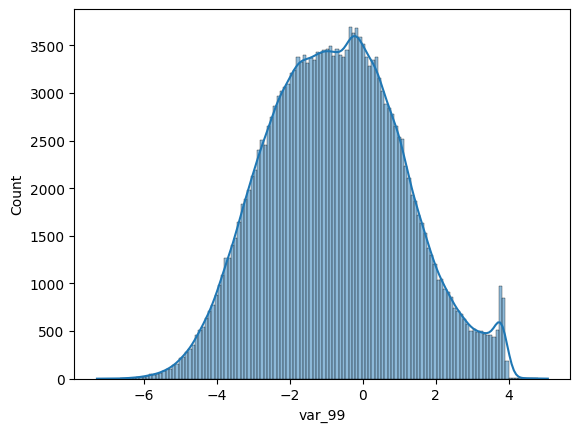

In [1054]:
sns.histplot(x = df["var_99"], kde=True)

In [1055]:
df.var_99.skew()

np.float64(0.12898686993950664)

In [1056]:
df["var_99"] = df["var_99"].fillna(df["var_99"].median())

<Axes: xlabel='var_100', ylabel='Count'>

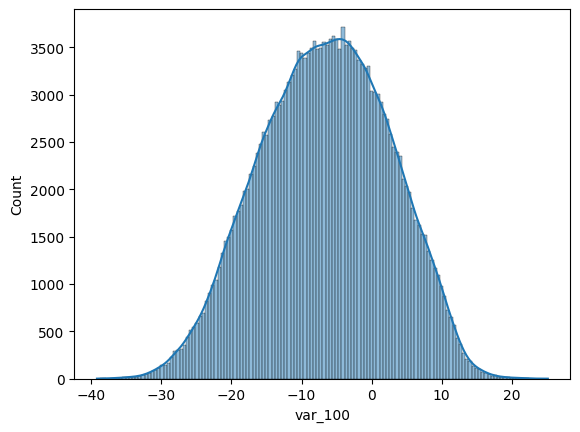

In [1057]:
sns.histplot(x = df["var_100"], kde=True)

In [1058]:
df.var_100.skew()

np.float64(-0.09408635320371714)

In [1059]:
df["var_100"] = df["var_100"].fillna(df["var_100"].mean())

<Axes: xlabel='var_101', ylabel='Count'>

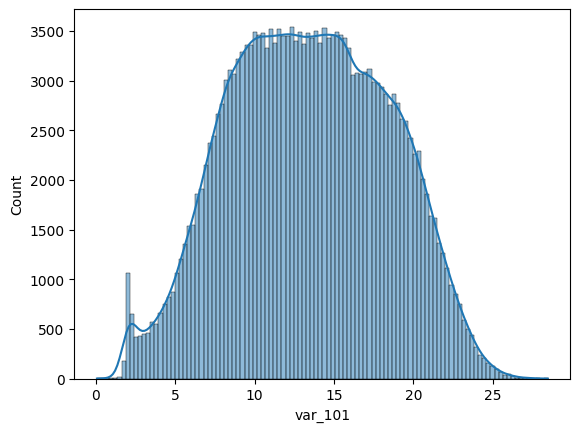

In [1060]:
sns.histplot(x = df["var_101"], kde=True)

In [1061]:
df.var_101.skew()

np.float64(-0.01980813909183498)

In [1062]:
df["var_101"] = df["var_101"].fillna(df["var_101"].mean())

<Axes: xlabel='var_102', ylabel='Count'>

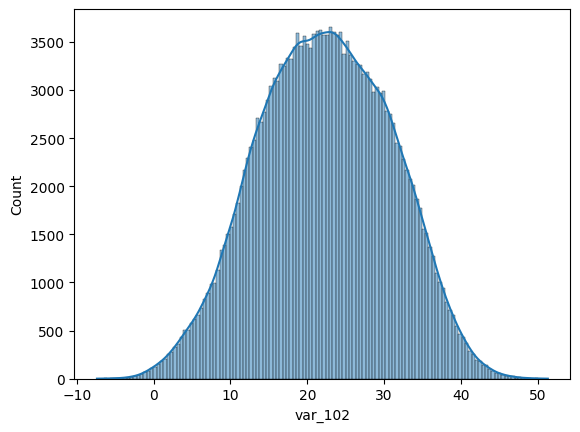

In [1063]:
sns.histplot(x = df["var_102"], kde=True)

In [1064]:
df.var_102.skew()

np.float64(-0.04215067045986655)

In [1065]:
df["var_102"] = df["var_102"].fillna(df["var_102"].mean())

<Axes: xlabel='var_103', ylabel='Count'>

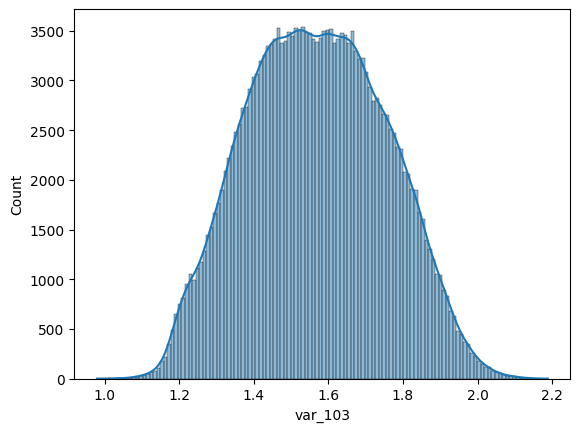

In [1066]:
sns.histplot(x = df["var_103"], kde=True)

In [1067]:
df.var_103.skew()

np.float64(0.05677822947953839)

In [1068]:
df["var_103"] = df["var_103"].fillna(df["var_103"].mean())

<Axes: xlabel='var_104', ylabel='Count'>

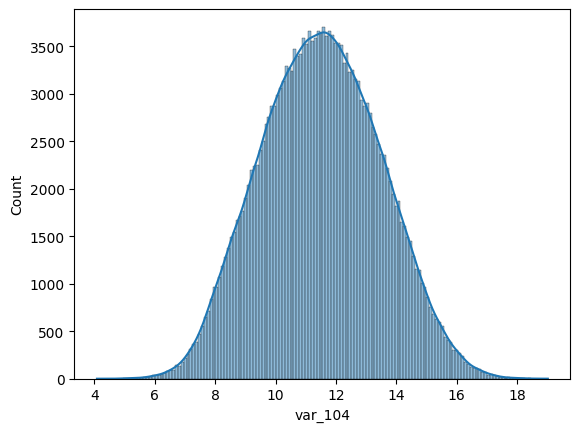

In [1069]:
sns.histplot(x = df["var_104"], kde=True)

In [1070]:
df.var_104.skew()

np.float64(0.04980844265637869)

In [1071]:
df["var_104"] = df["var_104"].fillna(df["var_104"].mean())

<Axes: xlabel='var_105', ylabel='Count'>

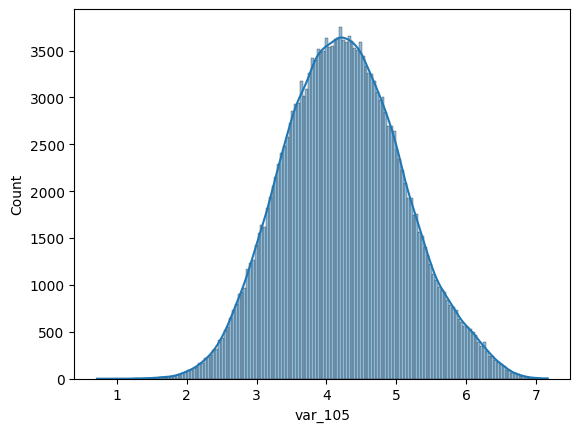

In [1072]:
sns.histplot(x = df["var_105"], kde=True)

In [1073]:
df.var_105.skew()

np.float64(0.12460606903340955)

In [1074]:
df["var_105"] = df["var_105"].fillna(df["var_105"].median())

<Axes: xlabel='var_106', ylabel='Count'>

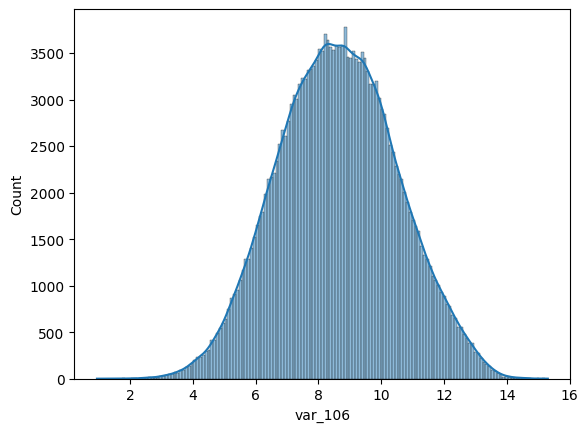

In [1075]:
sns.histplot(x = df["var_106"], kde=True)

In [1076]:
df.var_106.skew()

np.float64(0.022762416036131067)

In [1077]:
df["var_106"] = df["var_106"].fillna(df["var_106"].mean())

<Axes: xlabel='var_107', ylabel='Count'>

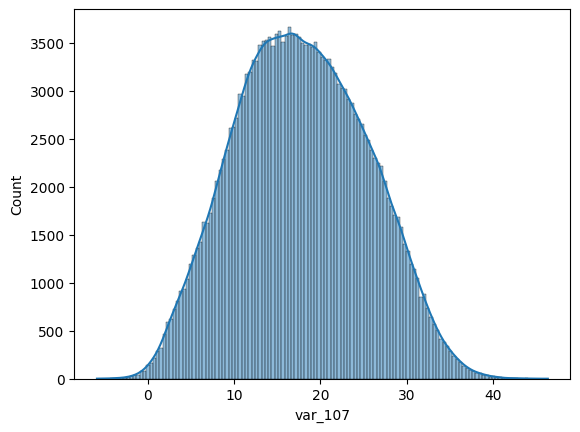

In [1078]:
sns.histplot(x = df["var_107"], kde=True)

In [1079]:
df.var_107.skew()

np.float64(0.09323115769375999)

In [1080]:
df["var_107"] = df["var_107"].fillna(df["var_107"].mean())

<Axes: xlabel='var_108', ylabel='Count'>

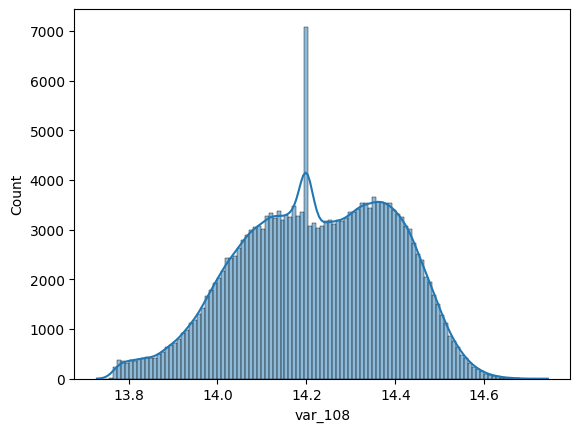

In [1081]:
sns.histplot(x = df["var_108"], kde=True)

In [1082]:
df.var_108.skew()

np.float64(-0.21438654692246803)

In [1083]:
df["var_108"] = df["var_108"].fillna(df["var_108"].median())

<Axes: xlabel='var_109', ylabel='Count'>

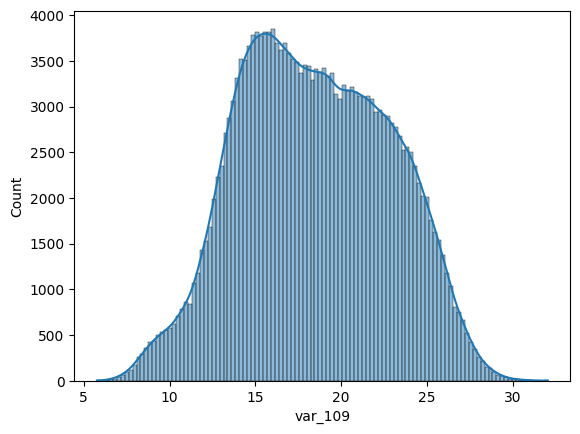

In [1084]:
sns.histplot(x = df["var_109"], kde=True)

In [1085]:
df.var_109.skew()

np.float64(0.038051187838411084)

In [1086]:
df["var_109"] = df["var_109"].fillna(df["var_109"].mean())

<Axes: xlabel='var_110', ylabel='Count'>

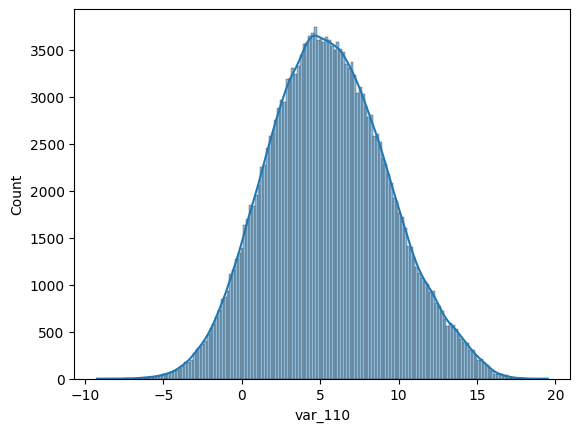

In [1087]:
sns.histplot(x = df["var_110"], kde=True)

In [1088]:
df.var_110.skew()

np.float64(0.12945154843937548)

In [1089]:
df["var_110"] = df["var_110"].fillna(df["var_110"].median())

<Axes: xlabel='var_111', ylabel='Count'>

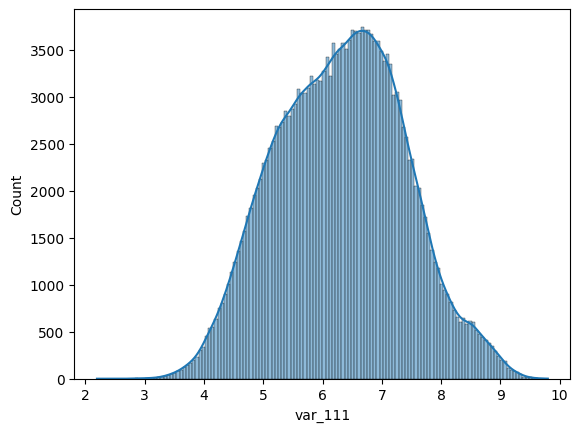

In [1090]:
sns.histplot(x = df["var_111"], kde=True)

In [1091]:
df.var_111.skew()

np.float64(0.03396403045327104)

In [1092]:
df["var_111"] = df["var_111"].fillna(df["var_111"].mean())

<Axes: xlabel='var_112', ylabel='Count'>

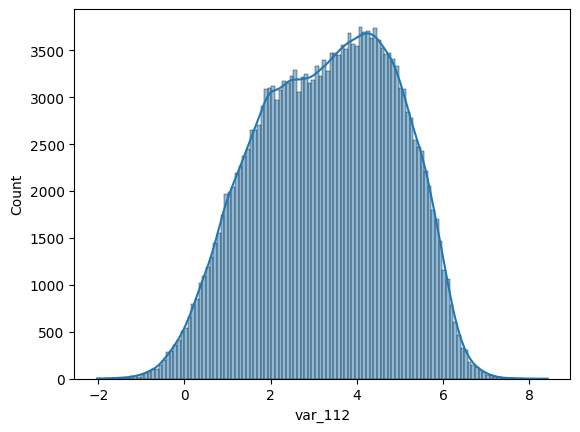

In [1093]:
sns.histplot(x = df["var_112"], kde=True)

In [1094]:
df.var_112.skew()

np.float64(-0.16863845104504413)

In [1095]:
df["var_112"] = df["var_112"].fillna(df["var_112"].median())

<Axes: xlabel='var_113', ylabel='Count'>

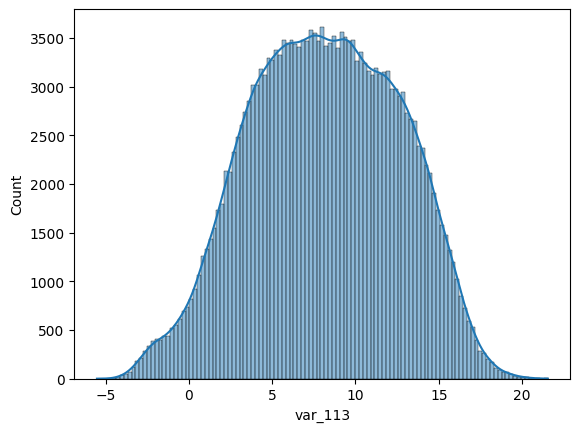

In [1096]:
sns.histplot(x = df["var_113"], kde=True)

In [1097]:
df.var_113.skew()

np.float64(-0.0732074171969649)

In [1098]:
df["var_113"] = df["var_113"].fillna(df["var_113"].mean())

<Axes: xlabel='var_114', ylabel='Count'>

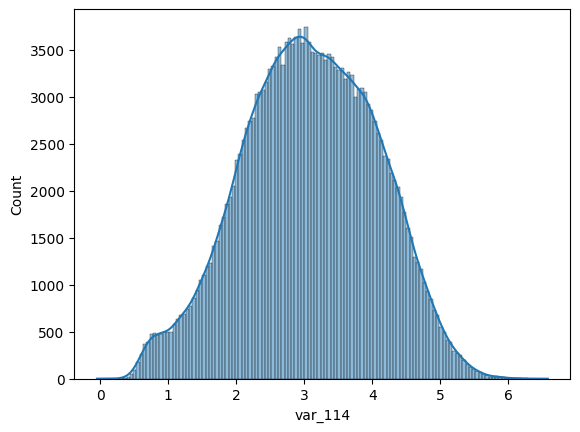

In [1099]:
sns.histplot(x = df["var_114"], kde=True)

In [1100]:
df.var_114.skew()

np.float64(-0.09601479616458128)

In [1101]:
df["var_114"] = df["var_114"].fillna(df["var_114"].median())

<Axes: xlabel='var_115', ylabel='Count'>

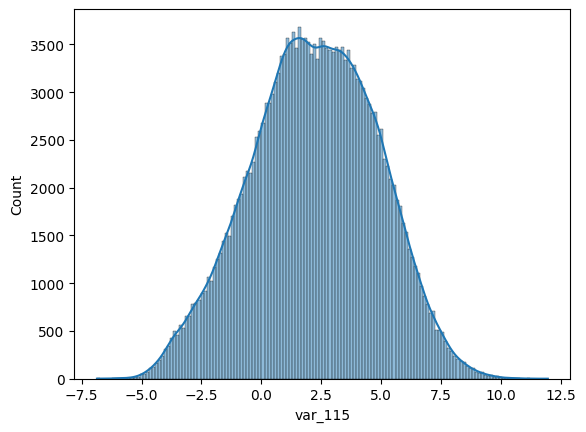

In [1102]:
sns.histplot(x = df["var_115"], kde=True)

In [1103]:
df.var_115.skew()

np.float64(-0.08576262139854005)

In [1104]:
df["var_115"] = df["var_115"].fillna(df["var_115"].mean())

<Axes: xlabel='var_116', ylabel='Count'>

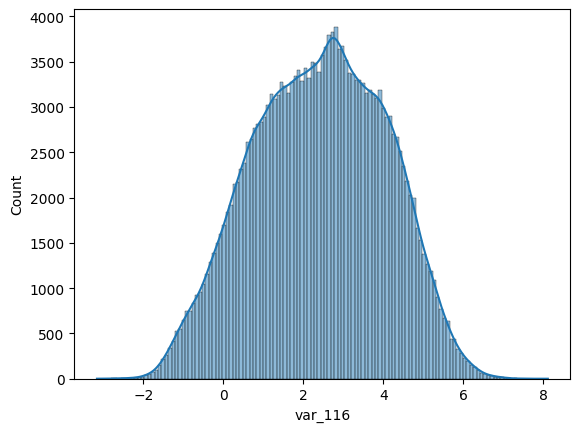

In [1105]:
sns.histplot(x = df["var_116"], kde=True)

In [1106]:
df.var_116.skew()

np.float64(-0.08374031025730401)

In [1107]:
df["var_116"] = df["var_116"].fillna(df["var_116"].mean())

<Axes: xlabel='var_117', ylabel='Count'>

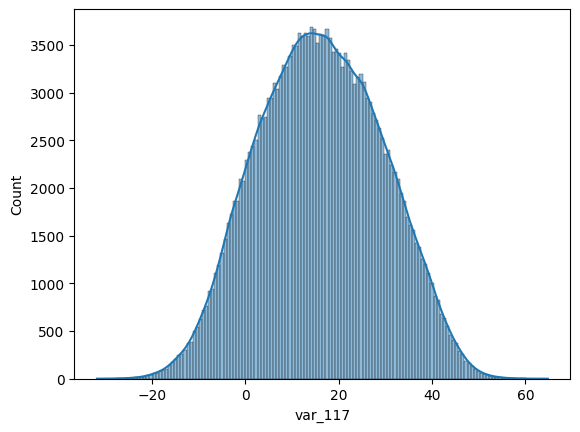

In [1108]:
sns.histplot(x = df["var_117"], kde=True)

In [1109]:
df.var_117.skew()

np.float64(0.0209230324492712)

In [1110]:
df["var_117"] = df["var_117"].fillna(df["var_117"].mean())

<Axes: xlabel='var_118', ylabel='Count'>

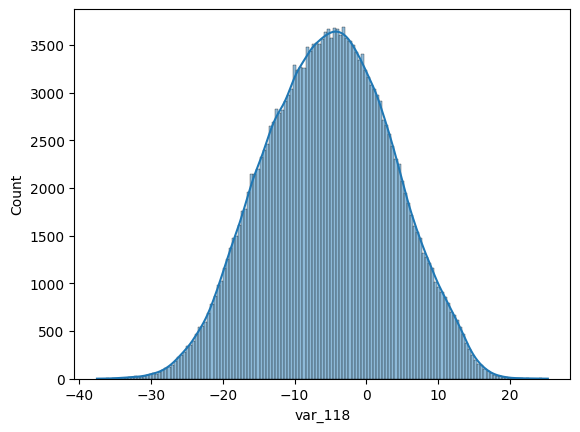

In [1111]:
sns.histplot(x = df["var_118"], kde=True)

In [1112]:
df.var_118.skew()

np.float64(-0.04356601537258399)

In [1113]:
df["var_118"] = df["var_118"].fillna(df["var_118"].mean())

<Axes: xlabel='var_119', ylabel='Count'>

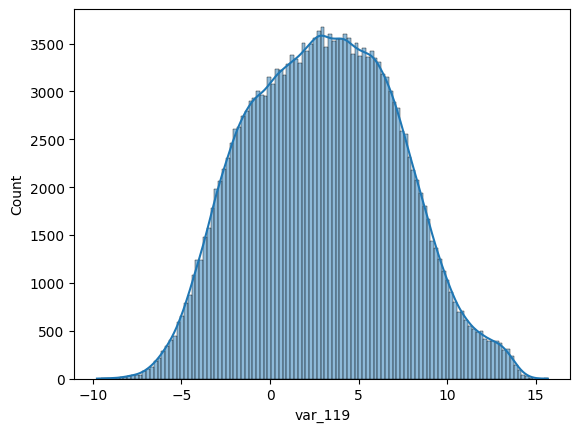

In [1114]:
sns.histplot(x = df["var_119"], kde=True)

In [1115]:
df.var_119.skew()

np.float64(0.08391657654139081)

In [1116]:
df["var_119"] = df["var_119"].fillna(df["var_119"].mean())

<Axes: xlabel='var_120', ylabel='Count'>

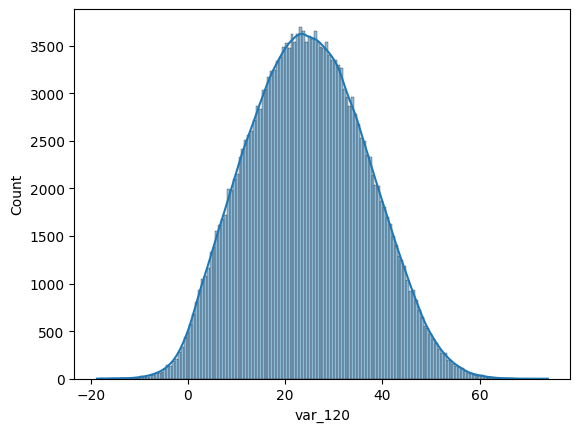

In [1117]:
sns.histplot(x = df["var_120"], kde=True)

In [1118]:
df.var_120.skew()

np.float64(0.0837639578436772)

In [1119]:
df["var_120"] = df["var_120"].fillna(df["var_120"].mean())

<Axes: xlabel='var_121', ylabel='Count'>

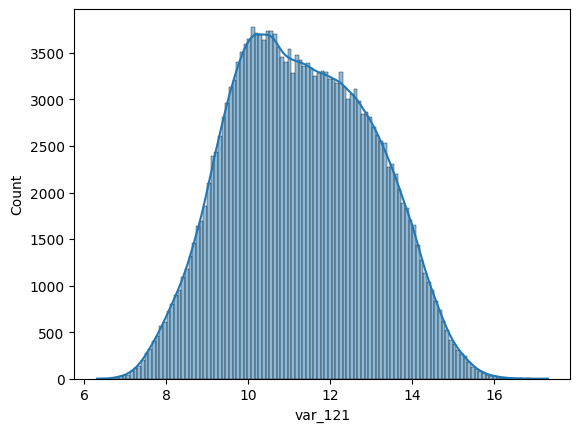

In [1120]:
sns.histplot(x = df["var_121"], kde=True)

In [1121]:
df.var_121.skew()

np.float64(0.0941541187933007)

In [1122]:
df["var_121"] = df["var_121"].fillna(df["var_121"].mean())

<Axes: xlabel='var_122', ylabel='Count'>

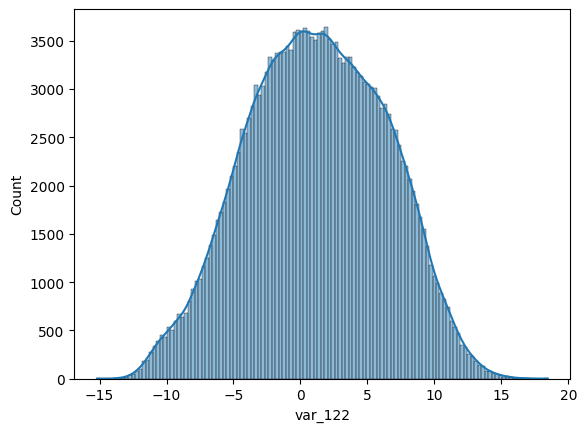

In [1123]:
sns.histplot(x = df["var_122"], kde=True)

In [1124]:
df.var_122.skew()

np.float64(-0.049977947194614056)

In [1125]:
df['var_122'] = df['var_122'].fillna(df['var_122'].mean())

<Axes: xlabel='var_123', ylabel='Count'>

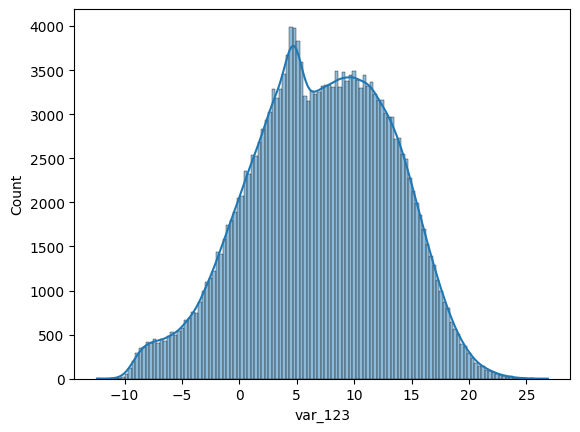

In [1126]:
sns.histplot(x = df["var_123"], kde=True)

In [1127]:
df.var_123.skew()

np.float64(-0.18500556722925968)

In [1128]:
df["var_123"] = df["var_123"].fillna(df["var_123"].median())

<Axes: xlabel='var_124', ylabel='Count'>

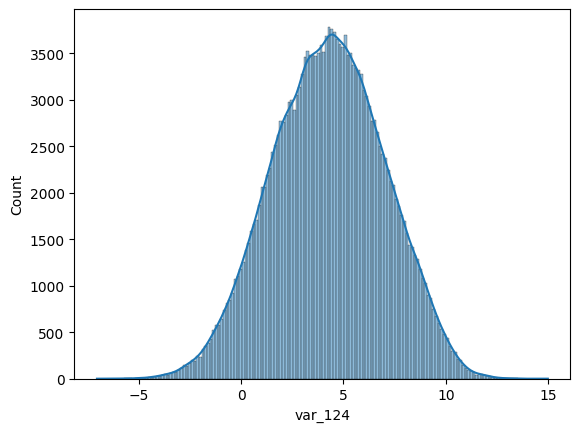

In [1129]:
sns.histplot(x = df["var_124"], kde=True)

In [1130]:
df.var_124.skew()

np.float64(-0.054576964673290845)

In [1131]:
df["var_124"] = df["var_124"].fillna(df["var_124"].mean())

<Axes: xlabel='var_125', ylabel='Count'>

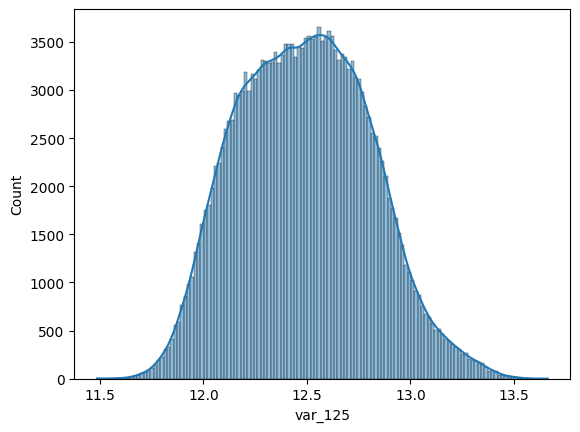

In [1132]:
sns.histplot(x = df["var_125"], kde=True)

In [1133]:
df.var_125.skew()

np.float64(0.15857365577923466)

In [1134]:
df["var_125"] = df["var_125"].fillna(df["var_125"].median())

<Axes: xlabel='var_126', ylabel='Count'>

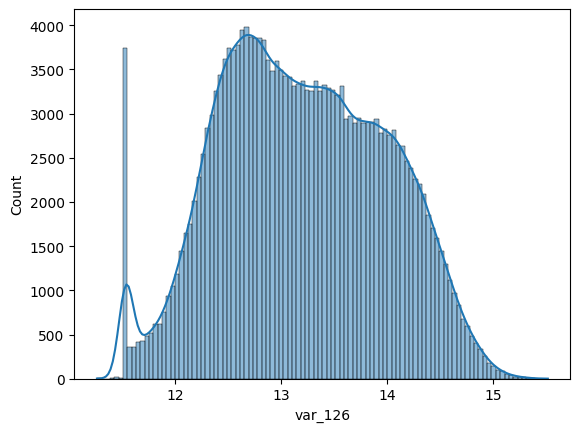

In [1135]:
sns.histplot(x = df["var_126"], kde=True)

In [1136]:
df.var_126.skew()

np.float64(0.048030641177894295)

In [1137]:
df["var_126"] = df["var_126"].fillna(df["var_126"].mean())

<Axes: xlabel='var_127', ylabel='Count'>

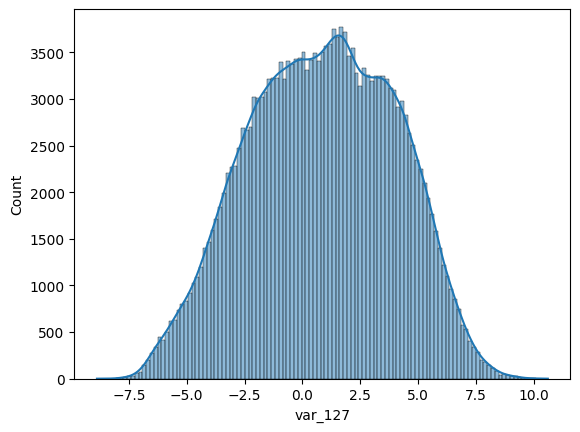

In [1138]:
sns.histplot(x = df["var_127"], kde=True)

In [1139]:
df.var_127.skew()

np.float64(-0.08041934611669148)

In [1140]:
df['var_127'] = df['var_127'].fillna(df['var_127'].mean())

<Axes: xlabel='var_128', ylabel='Count'>

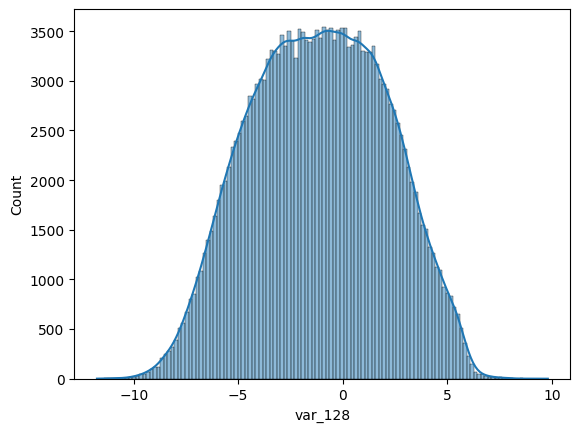

In [1141]:
sns.histplot(x = df["var_128"], kde=True)

In [1142]:
df.var_128.skew()

np.float64(-0.02960002730826372)

In [1143]:
df["var_128"] = df["var_128"].fillna(df["var_128"].mean())

<Axes: xlabel='var_129', ylabel='Count'>

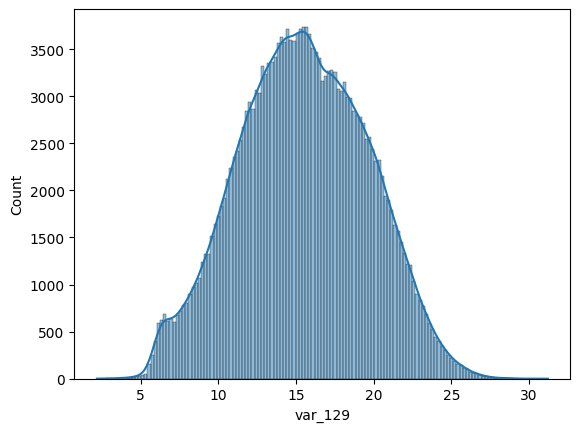

In [1144]:
sns.histplot(x = df["var_129"], kde=True)

In [1145]:
df.var_129.skew()

np.float64(-0.005026882643915953)

In [1146]:
df["var_129"] = df["var_129"].fillna(df["var_129"].mean())

<Axes: xlabel='var_130', ylabel='Count'>

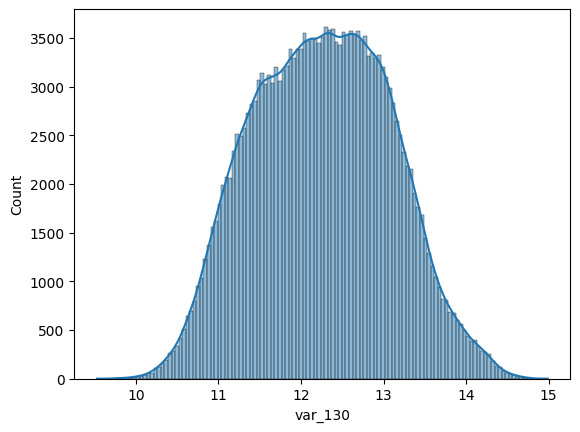

In [1147]:
sns.histplot(x = df["var_130"], kde=True)

In [1148]:
df.var_130.skew()

np.float64(0.04148630895691335)

In [1149]:
df["var_130"] = df["var_130"].fillna(df["var_130"].mean())

<Axes: xlabel='var_131', ylabel='Count'>

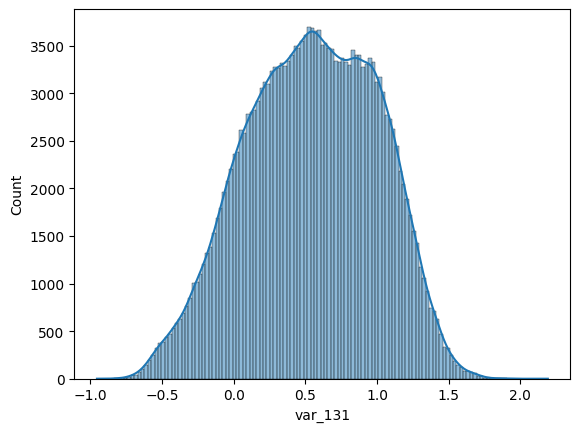

In [1150]:
sns.histplot(x = df["var_131"], kde=True)

In [1151]:
df.var_131.skew()

np.float64(-0.14014347650478196)

In [1152]:
df["var_131"] = df["var_131"].fillna(df["var_131"].median())

<Axes: xlabel='var_132', ylabel='Count'>

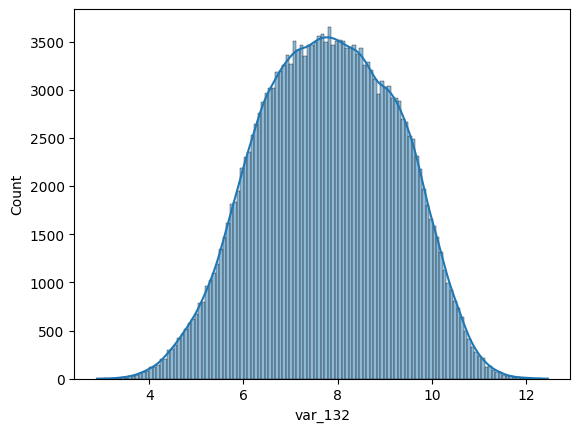

In [1153]:
sns.histplot(x = df["var_132"], kde=True)

In [1154]:
df.var_132.skew()

np.float64(-0.06906289884948534)

In [1155]:
df["var_132"] = df["var_132"].fillna(df["var_132"].mean())

<Axes: xlabel='var_133', ylabel='Count'>

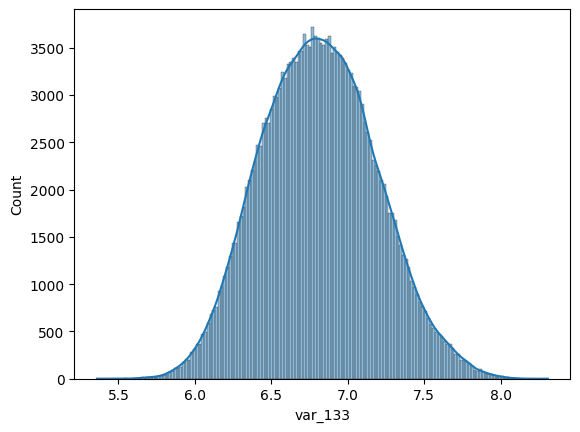

In [1156]:
sns.histplot(x = df["var_133"], kde=True)

In [1157]:
df.var_133.skew()

np.float64(0.12498625425394033)

In [1158]:
df["var_133"] = df["var_133"].fillna(df["var_133"].median())

<Axes: xlabel='var_134', ylabel='Count'>

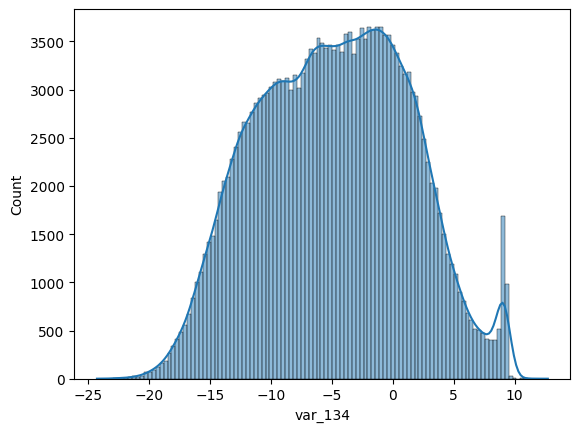

In [1159]:
sns.histplot(x = df["var_134"], kde=True)

In [1160]:
df.var_134.skew()

np.float64(0.013951019199816134)

In [1161]:
df["var_134"] = df["var_134"].fillna(df["var_134"].mean())

<Axes: xlabel='var_135', ylabel='Count'>

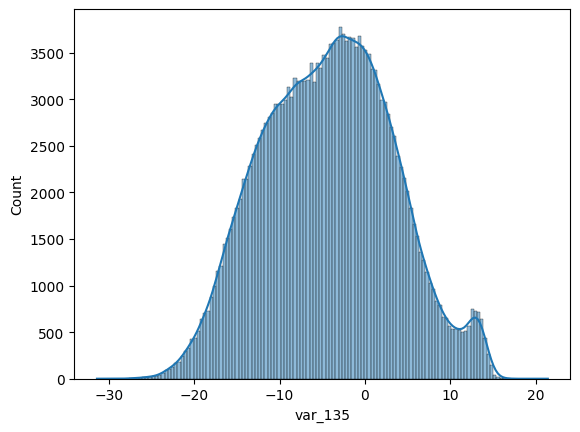

In [1162]:
sns.histplot(x = df["var_135"], kde=True)

In [1163]:
df.var_135.skew()

np.float64(0.05890221186862111)

In [1164]:
df["var_135"] = df["var_135"].fillna(df["var_135"].mean())

<Axes: xlabel='var_136', ylabel='Count'>

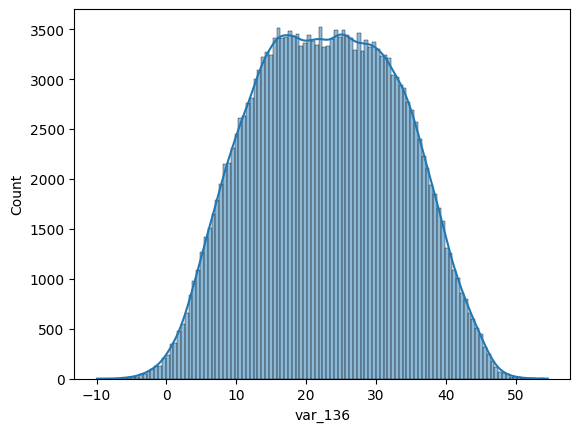

In [1165]:
sns.histplot(x = df["var_136"], kde=True)

In [1166]:
df.var_136.skew()

np.float64(0.003516844346457966)

In [1167]:
df["var_136"] = df["var_136"].fillna(df["var_136"].mean())

<Axes: xlabel='var_137', ylabel='Count'>

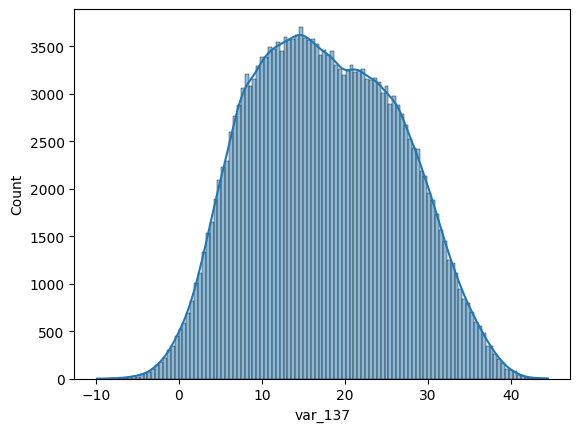

In [1168]:
sns.histplot(x = df["var_137"], kde=True)

In [1169]:
df.var_137.skew()

np.float64(0.10774414962380478)

In [1170]:
df["var_137"] = df["var_137"].fillna(df["var_137"].median())

<Axes: xlabel='var_138', ylabel='Count'>

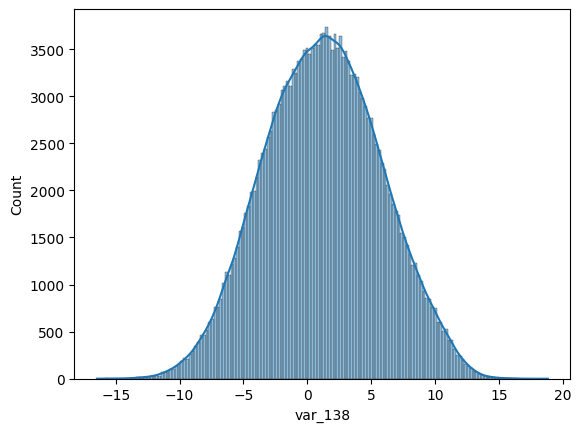

In [1171]:
sns.histplot(x = df["var_138"], kde=True)

In [1172]:
df.var_138.skew()

np.float64(0.00606308907147184)

In [1173]:
df["var_138"] = df["var_138"].fillna(df["var_138"].mean())

<Axes: xlabel='var_139', ylabel='Count'>

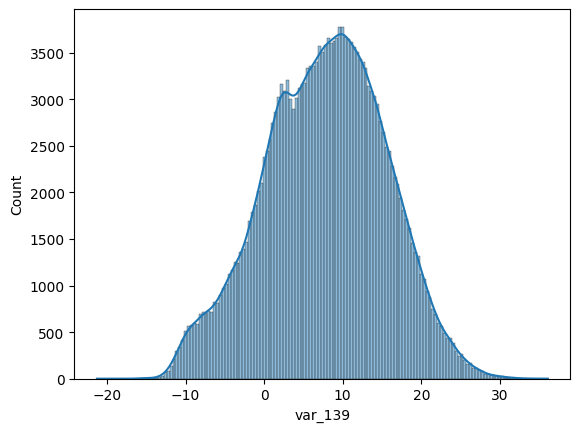

In [1174]:
sns.histplot(x = df["var_139"], kde=True)

In [1175]:
df.var_139.skew()

np.float64(-0.11712621371498765)

In [1176]:
df["var_139"] = df["var_139"].fillna(df["var_139"].median())

<Axes: xlabel='var_140', ylabel='Count'>

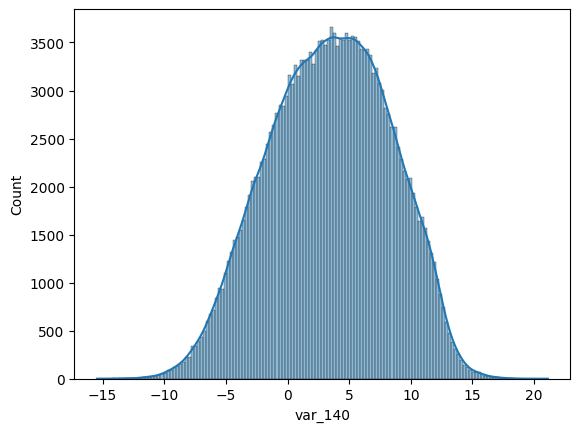

In [1177]:
sns.histplot(x = df["var_140"], kde=True)

In [1178]:
df.var_140.skew()

np.float64(-0.1189174531825011)

In [1179]:
df["var_140"] = df["var_140"].fillna(df["var_140"].median())

<Axes: xlabel='var_141', ylabel='Count'>

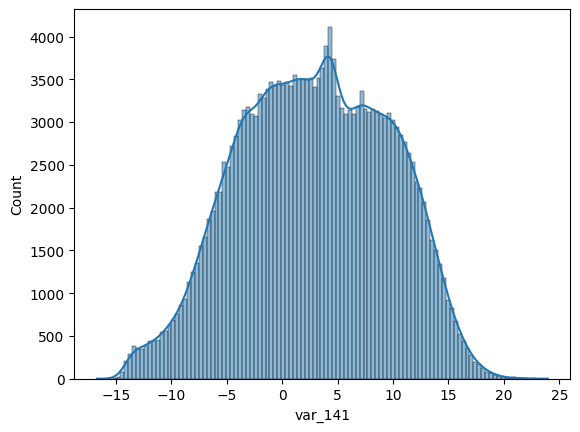

In [1180]:
sns.histplot(x = df["var_141"], kde=True)

In [1181]:
df.var_141.skew()

np.float64(-0.08779760431326988)

In [1182]:
df["var_141"] = df["var_141"].fillna(df["var_141"].median())

<Axes: xlabel='var_142', ylabel='Count'>

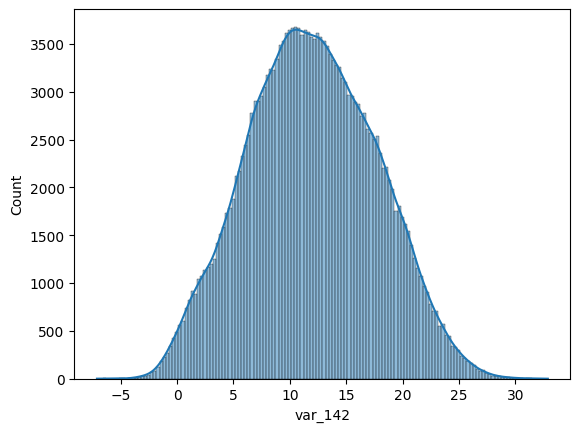

In [1183]:
sns.histplot(x = df["var_142"], kde=True)

In [1184]:
df.var_142.skew()

np.float64(0.06412365391891989)

In [1185]:
df["var_142"] = df["var_142"].fillna(df["var_142"].mean())

<Axes: xlabel='var_143', ylabel='Count'>

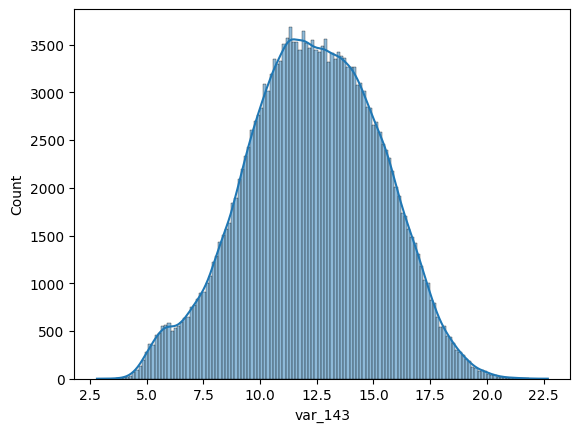

In [1186]:
sns.histplot(x = df["var_143"], kde=True)

In [1187]:
df.var_143.skew()

np.float64(-0.10312565508129429)

In [1188]:
df["var_143"] = df["var_143"].fillna(df["var_143"].median())

<Axes: xlabel='var_144', ylabel='Count'>

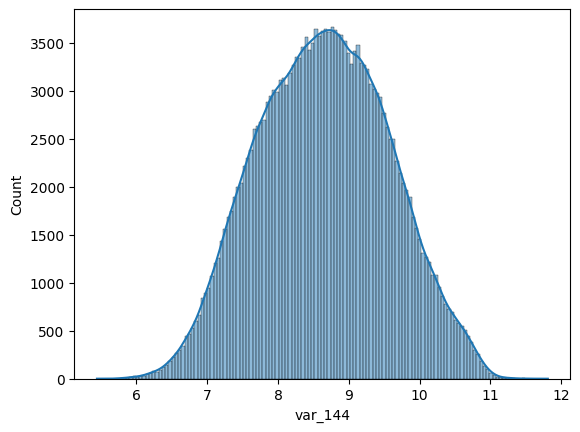

In [1189]:
sns.histplot(x = df["var_144"], kde=True)

In [1190]:
df.var_144.skew()

np.float64(0.00934132346073377)

In [1191]:
df["var_144"] = df["var_144"].fillna(df["var_144"].mean())

<Axes: xlabel='var_145', ylabel='Count'>

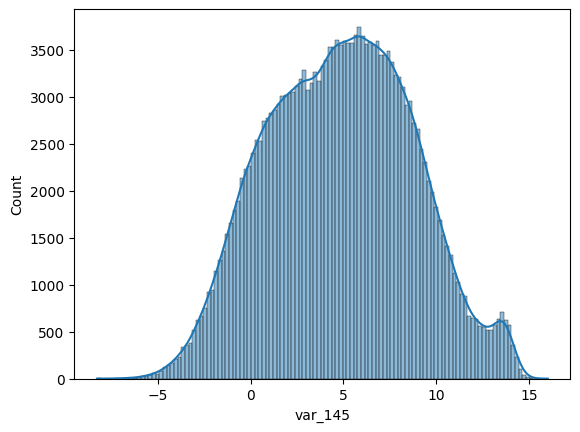

In [1192]:
sns.histplot(x = df["var_145"], kde=True)

In [1193]:
df.var_145.skew()

np.float64(0.03311990736875453)

In [1194]:
df["var_145"] = df["var_145"].fillna(df["var_145"].mean())

<Axes: xlabel='var_146', ylabel='Count'>

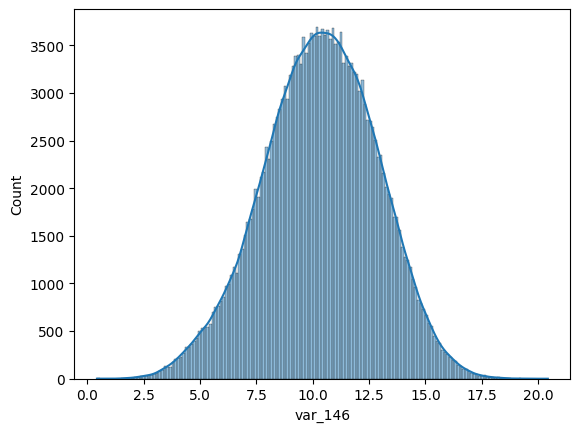

In [1195]:
sns.histplot(x = df["var_146"], kde=True)

In [1196]:
df.var_146.skew()

np.float64(-0.12508604879890511)

In [1197]:
df["var_146"] = df["var_146"].fillna(df["var_146"].median())

<Axes: xlabel='var_147', ylabel='Count'>

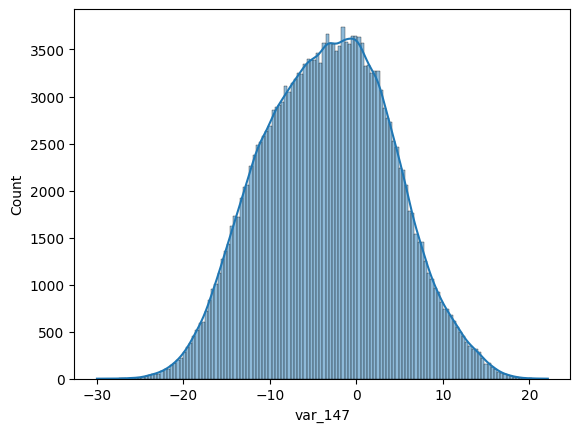

In [1198]:
sns.histplot(x = df["var_147"], kde=True)

In [1199]:
df.var_147.skew()

np.float64(0.008363596682023586)

In [1200]:
df["var_147"] = df["var_147"].fillna(df["var_147"].mean())

<Axes: xlabel='var_148', ylabel='Count'>

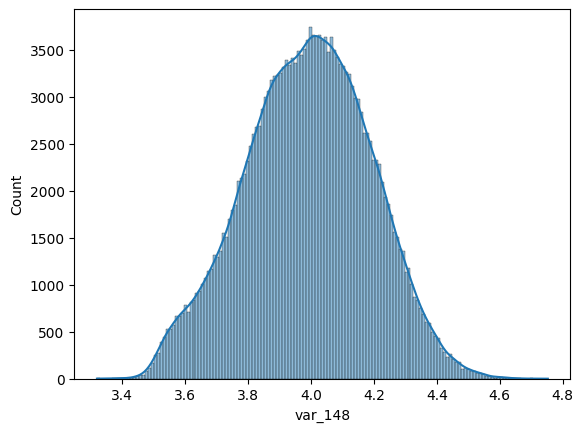

In [1201]:
sns.histplot(x = df["var_148"], kde=True)

In [1202]:
df.var_148.skew()

np.float64(-0.07007824456946701)

In [1203]:
df["var_148"] = df["var_148"].fillna(df["var_148"].mean())

<Axes: xlabel='var_149', ylabel='Count'>

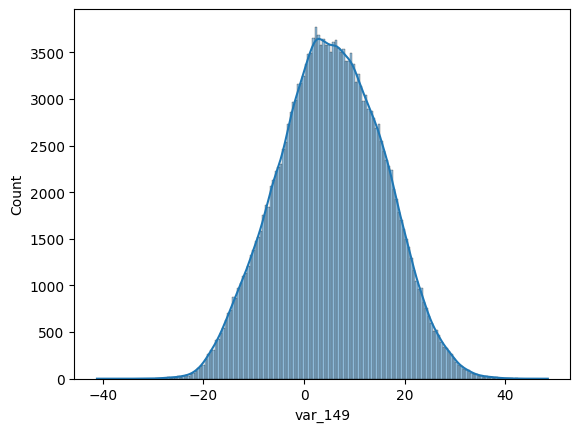

In [1204]:
sns.histplot(x = df["var_149"], kde=True)

In [1205]:
df.var_149.skew()

np.float64(-0.015573456762599936)

In [1206]:
df["var_149"] = df["var_149"].fillna(df["var_149"].mean())

<Axes: xlabel='var_150', ylabel='Count'>

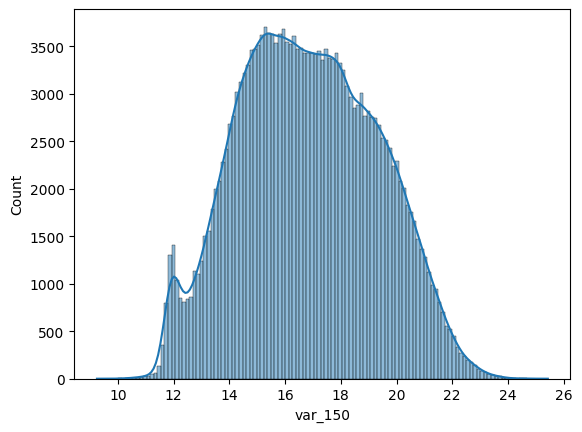

In [1207]:
sns.histplot(x = df["var_150"], kde=True)

In [1208]:
df.var_150.skew()

np.float64(0.0820630993545913)

In [1209]:
df["var_150"] = df["var_150"].fillna(df["var_150"].mean())

<Axes: xlabel='var_151', ylabel='Count'>

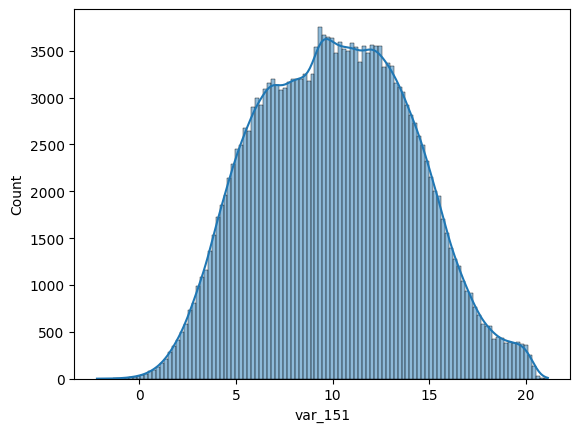

In [1210]:
sns.histplot(x = df["var_151"], kde=True)

In [1211]:
df.var_151.skew()

np.float64(0.08452625641855754)

In [1212]:
df["var_151"] = df["var_151"].fillna(df["var_151"].mean())

<Axes: xlabel='var_152', ylabel='Count'>

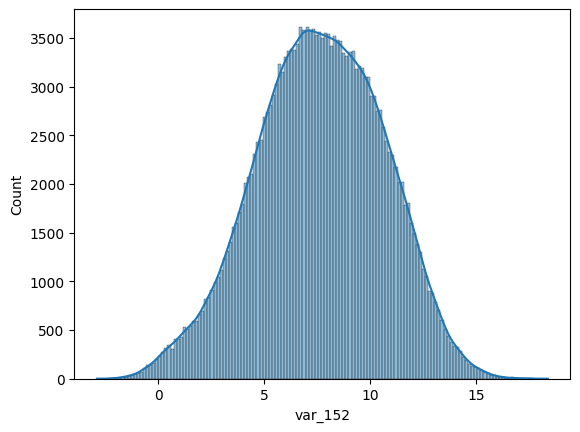

In [1213]:
sns.histplot(x = df["var_152"], kde=True)

In [1214]:
df.var_152.skew()

np.float64(-0.12667620598173376)

In [1215]:
df["var_152"] = df["var_152"].fillna(df["var_152"].median())

<Axes: xlabel='var_153', ylabel='Count'>

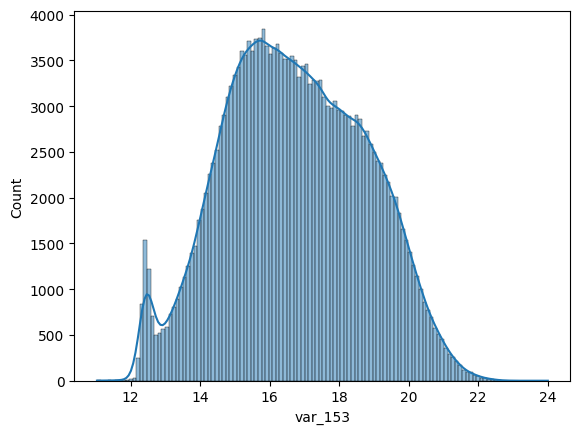

In [1216]:
sns.histplot(x = df["var_153"], kde=True)

In [1217]:
df.var_153.skew()

np.float64(0.04507669166857964)

In [1218]:
df['var_153'] = df['var_153'].fillna(df['var_153'].mean())

<Axes: xlabel='var_154', ylabel='Count'>

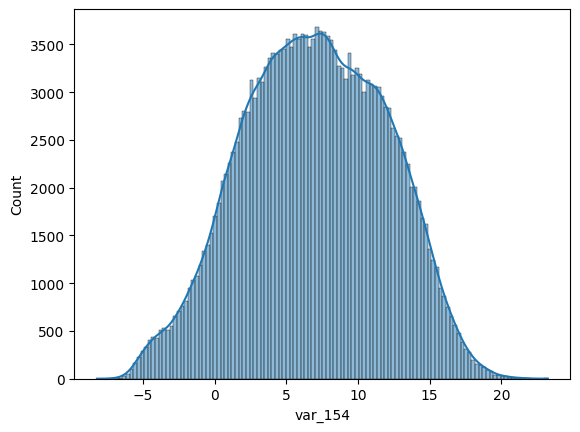

In [1219]:
sns.histplot(x = df["var_154"], kde=True)

In [1220]:
df.var_154.skew()

np.float64(-0.0655961892119998)

In [1221]:
df["var_154"] = df["var_154"].fillna(df["var_154"].mean())

<Axes: xlabel='var_155', ylabel='Count'>

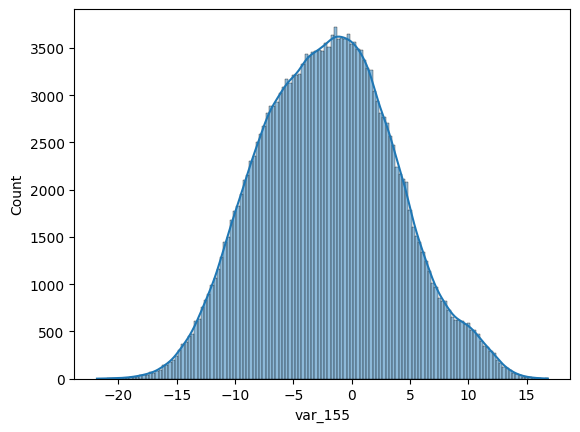

In [1222]:
sns.histplot(x = df["var_155"], kde=True)

In [1223]:
df.var_155.skew()

np.float64(0.08652899701392042)

In [1224]:
df["var_155"] = df["var_155"].fillna(df["var_155"].mean())

<Axes: xlabel='var_156', ylabel='Count'>

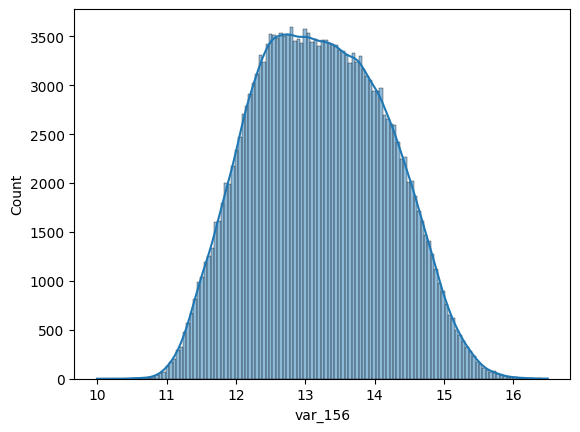

In [1225]:
sns.histplot(x = df["var_156"], kde=True)

In [1226]:
df.var_156.skew()

np.float64(0.09362620368492675)

In [1227]:
df["var_156"] = df["var_156"].fillna(df["var_156"].mean())

<Axes: xlabel='var_157', ylabel='Count'>

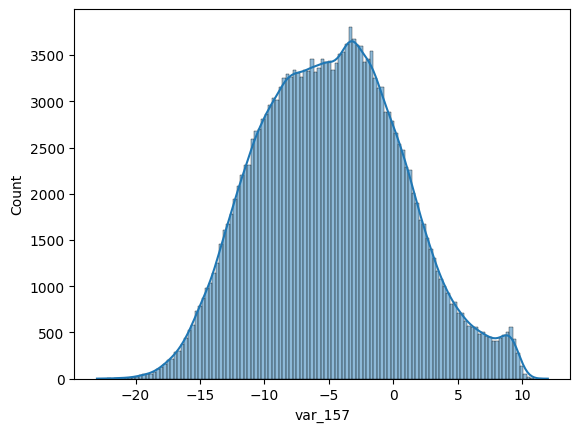

In [1228]:
sns.histplot(x = df["var_157"], kde=True)

In [1229]:
df.var_157.skew()

np.float64(0.15365335251313544)

In [1230]:
df["var_157"] = df["var_157"].fillna(df["var_157"].median())

<Axes: xlabel='var_158', ylabel='Count'>

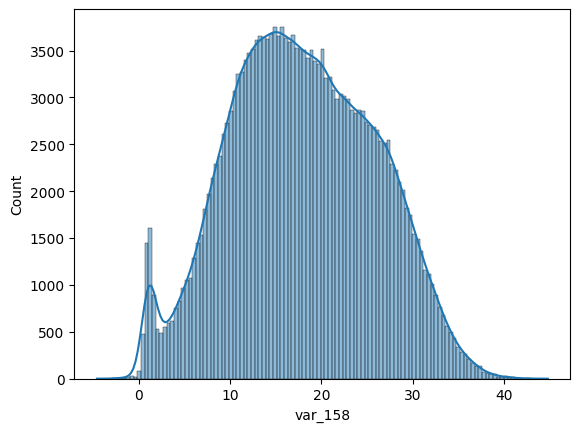

In [1231]:
sns.histplot(x = df["var_158"], kde=True)

In [1232]:
df.var_158.skew()

np.float64(0.0398279640176303)

In [1233]:
df["var_158"] = df["var_158"].fillna(df["var_158"].mean())

<Axes: xlabel='var_159', ylabel='Count'>

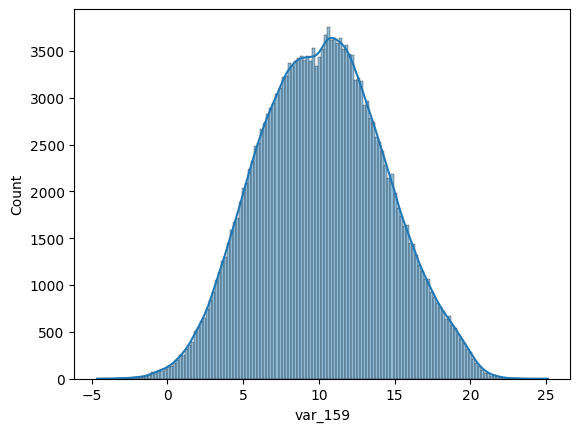

In [1234]:
sns.histplot(x = df["var_159"], kde=True)

In [1235]:
df.var_159.skew()

np.float64(0.051844401986777935)

In [1236]:
df["var_159"] = df["var_159"].fillna(df["var_159"].mean())

<Axes: xlabel='var_160', ylabel='Count'>

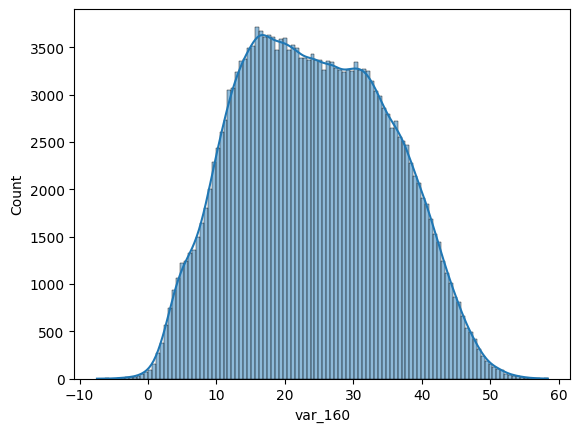

In [1237]:
sns.histplot(x = df["var_160"], kde=True)

In [1238]:
df.var_160.skew()

np.float64(0.10946885240400324)

In [1239]:
df['var_160'] = df['var_160'].fillna(df['var_160'].median())

<Axes: xlabel='var_161', ylabel='Count'>

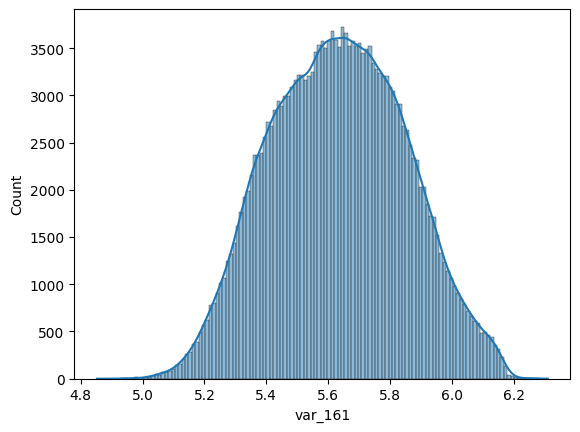

In [1240]:
sns.histplot(x = df["var_161"], kde=True)

In [1241]:
df.var_161.skew()

np.float64(0.02599605489581063)

In [1242]:
df["var_161"] = df["var_161"].fillna(df["var_161"].mean())

<Axes: xlabel='var_162', ylabel='Count'>

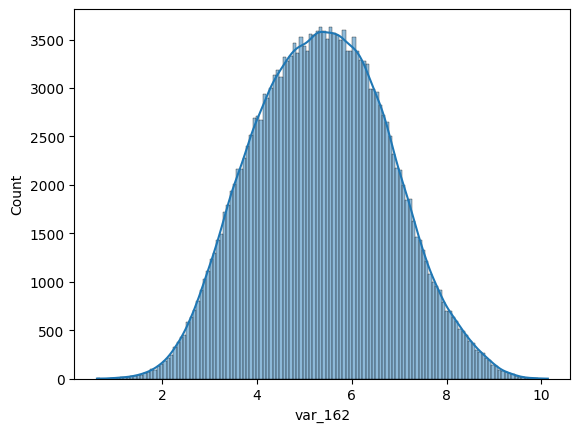

In [1243]:
sns.histplot(x = df["var_162"], kde=True)

In [1244]:
df.var_162.skew()

np.float64(0.05793368793869462)

In [1245]:
df["var_162"] = df["var_162"].fillna(df["var_162"].mean())

<Axes: xlabel='var_163', ylabel='Count'>

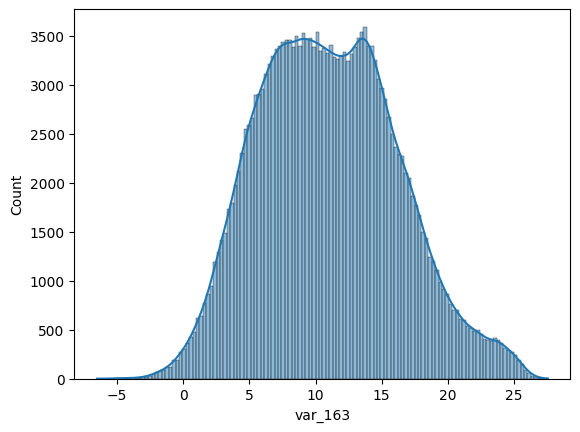

In [1246]:
sns.histplot(x = df["var_163"], kde=True)

In [1247]:
df.var_163.skew()

np.float64(0.23478011925783251)

In [1248]:
df["var_163"] = df["var_163"].fillna(df["var_163"].median())

<Axes: xlabel='var_164', ylabel='Count'>

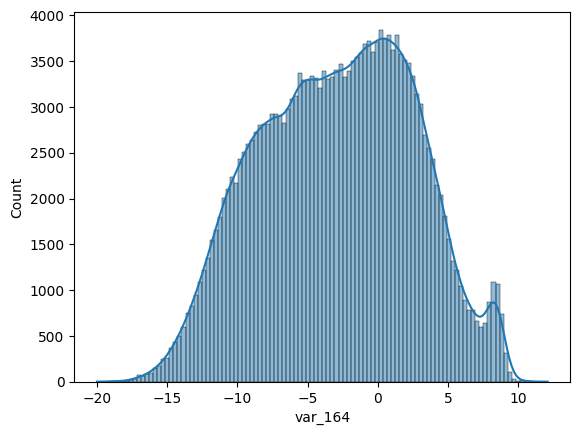

In [1249]:
sns.histplot(x=df['var_164'], kde=True)

In [1250]:
df.var_164.skew()

np.float64(-0.07549637402544461)

In [1251]:
df["var_164"] = df["var_164"].fillna(df["var_164"].mean())

<Axes: xlabel='var_165', ylabel='Count'>

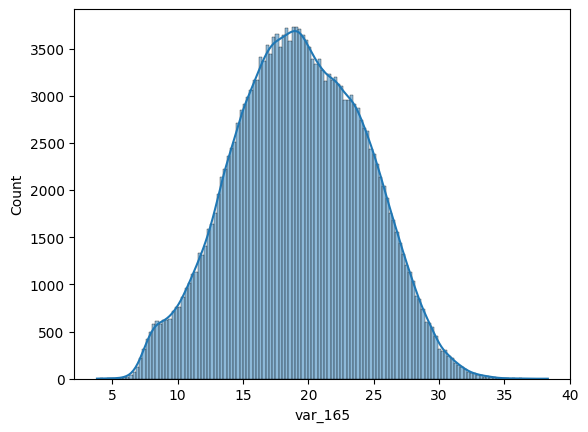

In [1252]:
sns.histplot(x = df["var_165"], kde=True)

In [1253]:
df.var_165.skew()

np.float64(-0.020687746120981263)

In [1254]:
df["var_165"] = df["var_165"].fillna(df["var_165"].mean())

<Axes: xlabel='var_166', ylabel='Count'>

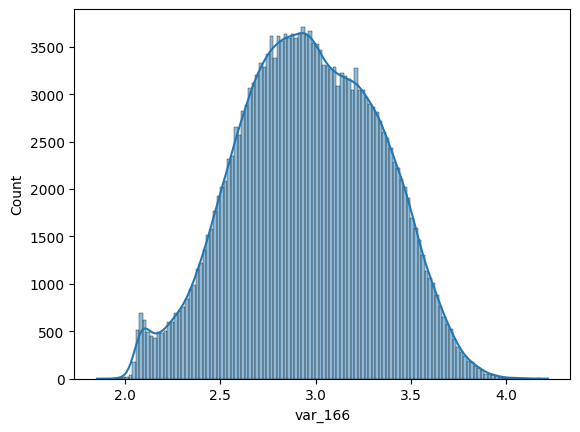

In [1255]:
sns.histplot(x = df["var_166"], kde=True)

In [1256]:
df.var_166.skew()

np.float64(-0.06374364587088995)

In [1257]:
df["var_166"] = df["var_166"].fillna(df["var_166"].mean())

<Axes: xlabel='var_167', ylabel='Count'>

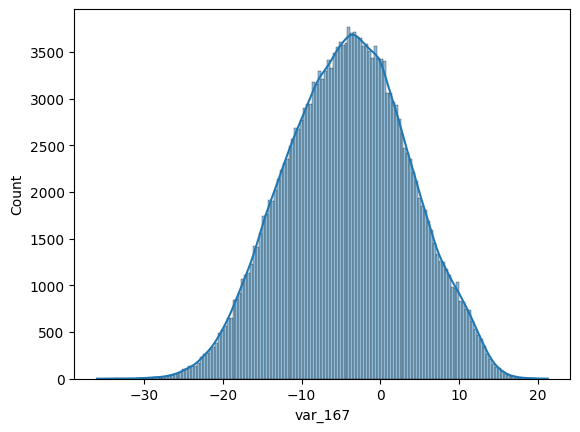

In [1258]:
sns.histplot(x = df["var_167"], kde=True)

In [1259]:
df.var_167.skew()

np.float64(-0.05511062338602924)

In [1260]:
df["var_167"] = df["var_167"].fillna(df["var_167"].mean())

<Axes: xlabel='var_168', ylabel='Count'>

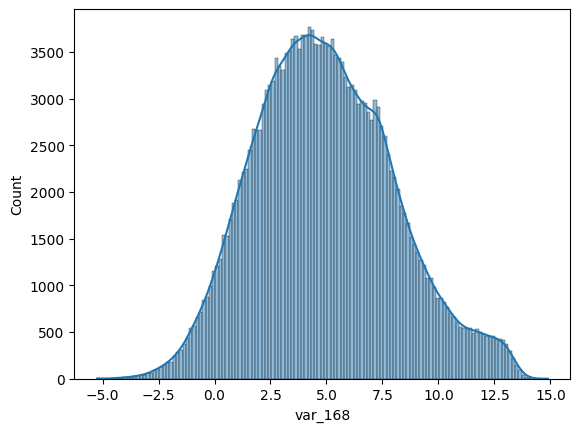

In [1261]:
sns.histplot(x = df["var_168"], kde=True)

In [1262]:
df.var_168.skew()

np.float64(0.2674136233473473)

In [1263]:
df["var_168"] = df["var_168"].fillna(df["var_168"].median())

<Axes: xlabel='var_169', ylabel='Count'>

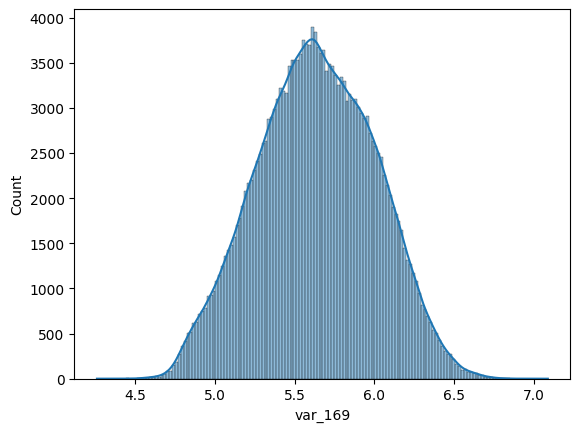

In [1264]:
sns.histplot(x = df["var_169"], kde=True)

In [1265]:
df.var_169.skew()

np.float64(-0.015961006610233912)

In [1266]:
df["var_169"] = df["var_169"].fillna(df["var_169"].mean())

<Axes: xlabel='var_170', ylabel='Count'>

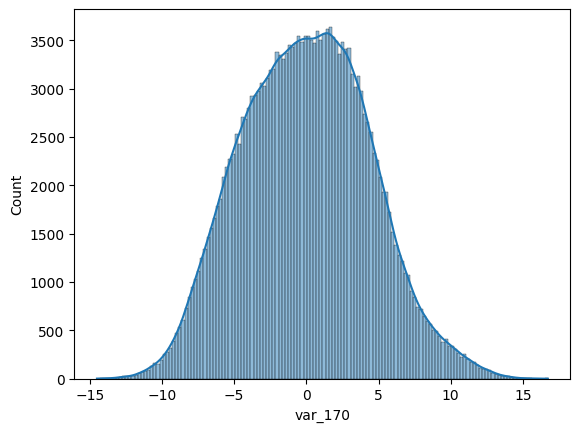

In [1267]:
sns.histplot(x = df["var_170"], kde=True)

In [1268]:
df.var_170.skew()

np.float64(0.10299435317431005)

In [1269]:
df["var_170"] = df["var_170"].fillna(df["var_170"].mean())

<Axes: xlabel='var_171', ylabel='Count'>

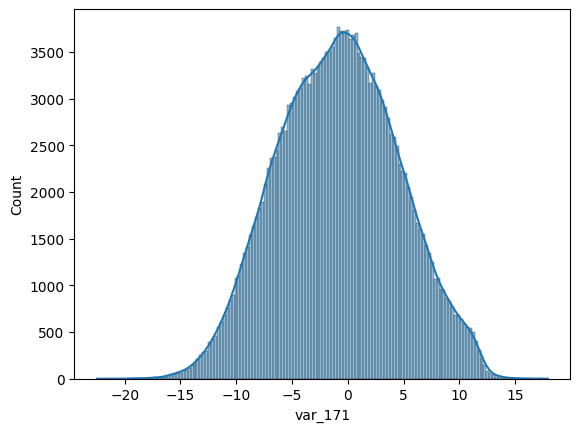

In [1270]:
sns.histplot(x = df["var_171"], kde=True)

In [1271]:
df.var_171.skew()

np.float64(0.014630138062551291)

In [1272]:
df["var_171"] = df["var_171"].fillna(df["var_171"].mean())

<Axes: xlabel='var_172', ylabel='Count'>

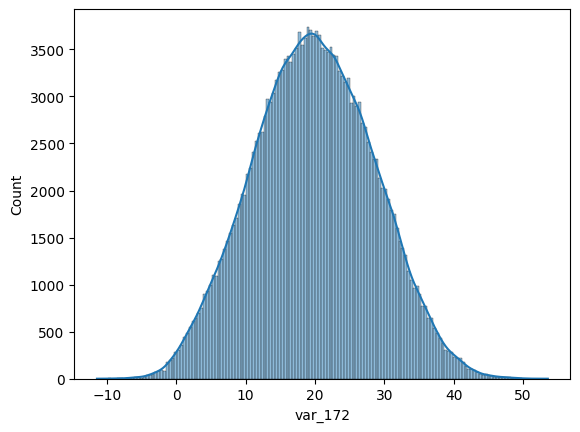

In [1273]:
sns.histplot(x = df["var_172"], kde=True)

In [1274]:
df.var_172.skew()

np.float64(0.03540544280755615)

In [1275]:
df["var_172"] = df["var_172"].fillna(df["var_172"].mean())

<Axes: xlabel='var_173', ylabel='Count'>

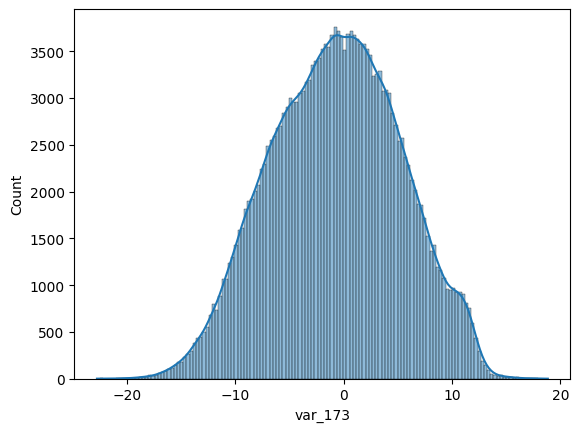

In [1276]:
sns.histplot(x = df["var_173"], kde=True)

In [1277]:
df.var_173.skew()

np.float64(-0.056174140352671306)

In [1278]:
df["var_173"] = df["var_173"].fillna(df["var_173"].mean())

<Axes: xlabel='var_174', ylabel='Count'>

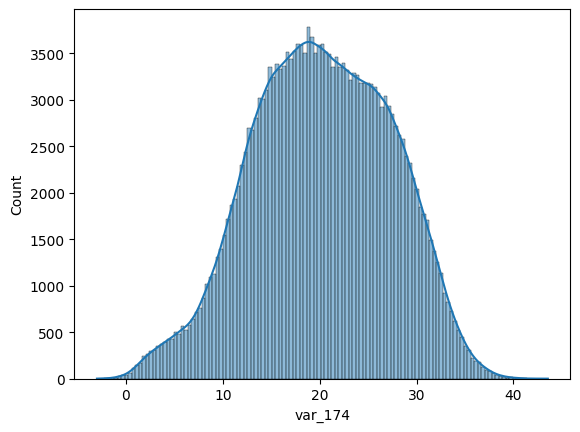

In [1279]:
sns.histplot(x = df["var_174"], kde=True)

In [1280]:
df.var_174.skew()

np.float64(-0.1157562448625246)

In [1281]:
df["var_174"] = df["var_174"].fillna(df["var_174"].median())

<Axes: xlabel='var_175', ylabel='Count'>

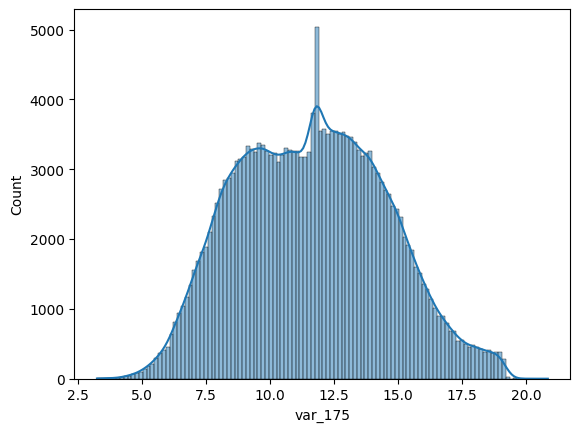

In [1282]:
sns.histplot(x = df["var_175"], kde=True)

In [1283]:
df.var_175.skew()

np.float64(0.13996742396409326)

In [1284]:
df["var_175"] = df["var_175"].fillna(df["var_175"].median())

<Axes: xlabel='var_176', ylabel='Count'>

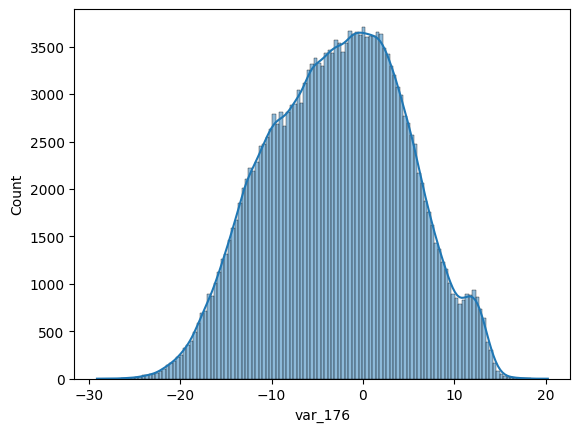

In [1285]:
sns.histplot(x = df["var_176"], kde=True)

In [1286]:
df.var_176.skew()

np.float64(-0.06987614308266393)

In [1287]:
df["var_176"] = df["var_176"].fillna(df["var_176"].mean())

<Axes: xlabel='var_177', ylabel='Count'>

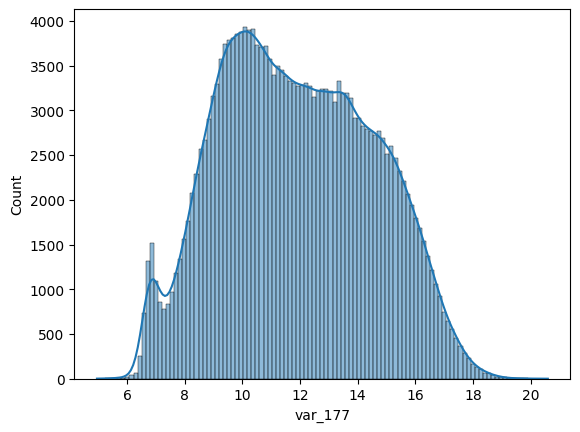

In [1288]:
sns.histplot(x = df["var_177"], kde=True)

In [1289]:
df.var_177.skew()

np.float64(0.12094449892460588)

In [1290]:
df["var_177"] = df["var_177"].fillna(df["var_177"].median())

<Axes: xlabel='var_178', ylabel='Count'>

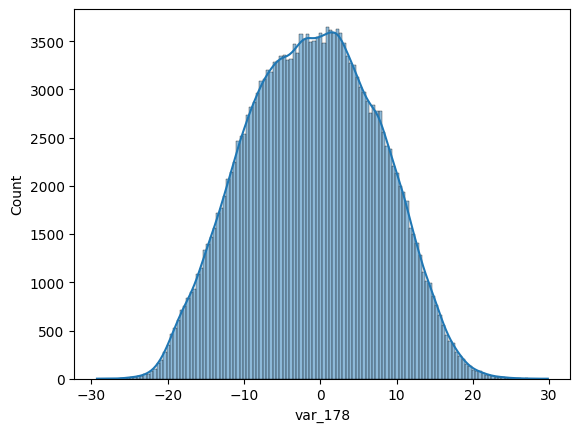

In [1291]:
sns.histplot(x = df["var_178"], kde=True)

In [1292]:
df.var_178.skew()

np.float64(-0.007879235805364312)

In [1293]:
df["var_178"] = df["var_178"].fillna(df["var_178"].mean())

<Axes: xlabel='var_179', ylabel='Count'>

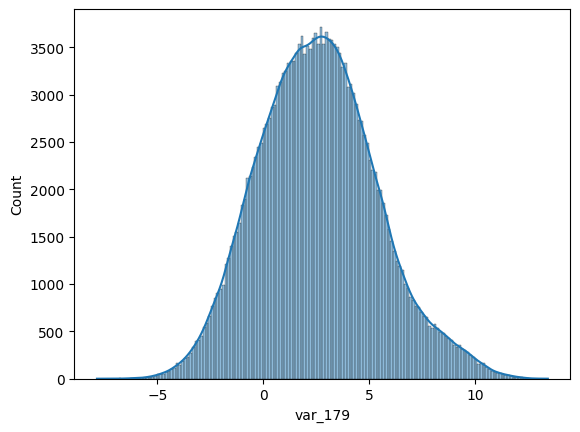

In [1294]:
sns.histplot(x = df["var_179"], kde=True)

In [1295]:
df.var_179.skew()

np.float64(0.24289097358838202)

In [1296]:
df["var_179"] = df["var_179"].fillna(df["var_179"].median())

<Axes: xlabel='var_180', ylabel='Count'>

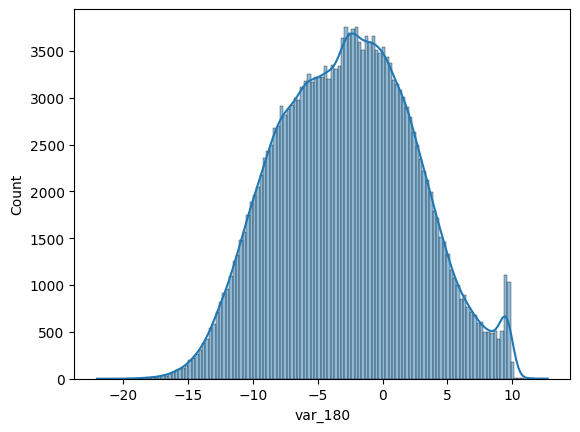

In [1297]:
sns.histplot(x = df["var_180"], kde=True)

In [1298]:
df.var_180.skew()

np.float64(0.061788286761591316)

In [1299]:
df["var_180"] = df["var_180"].fillna(df["var_180"].mean())

<Axes: xlabel='var_181', ylabel='Count'>

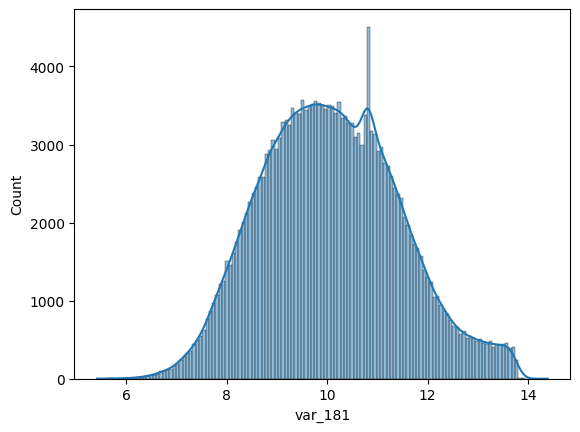

In [1300]:
sns.histplot(x = df["var_181"], kde=True)

In [1301]:
df.var_181.skew()

np.float64(0.2053551406466937)

In [1302]:
df["var_181"] = df["var_181"].fillna(df["var_181"].median())

<Axes: xlabel='var_182', ylabel='Count'>

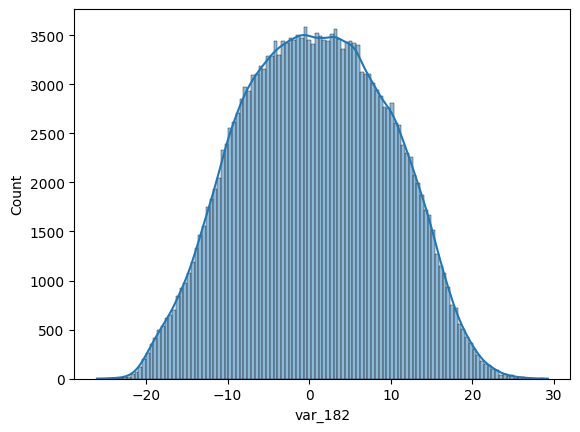

In [1303]:
sns.histplot(x = df["var_182"], kde=True)

In [1304]:
df.var_182.skew()

np.float64(-0.003946838650720988)

In [1305]:
df["var_182"] = df["var_182"].fillna(df["var_182"].mean())

<Axes: xlabel='var_183', ylabel='Count'>

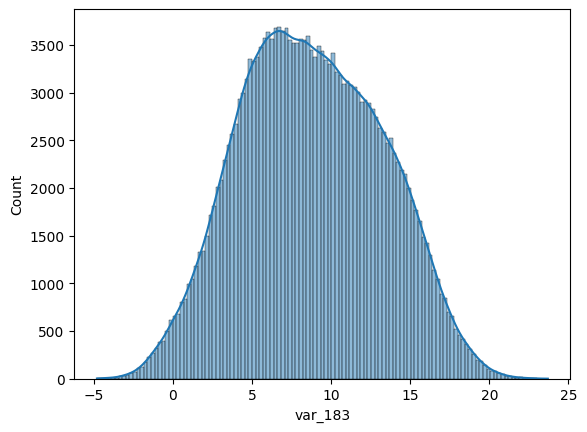

In [1306]:
sns.histplot(x = df["var_183"], kde=True)

In [1307]:
df.var_183.skew()

np.float64(0.07552114117782843)

In [1308]:
df["var_183"] = df["var_183"].fillna(df["var_183"].mean())

<Axes: xlabel='var_184', ylabel='Count'>

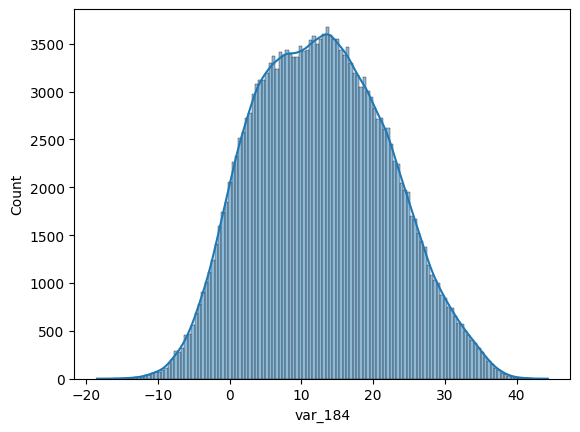

In [1309]:
sns.histplot(x = df["var_184"], kde=True)

In [1310]:
df.var_184.skew()

np.float64(0.14464027295872067)

In [1311]:
df["var_184"] = df["var_184"].fillna(df["var_184"].median())

<Axes: xlabel='var_185', ylabel='Count'>

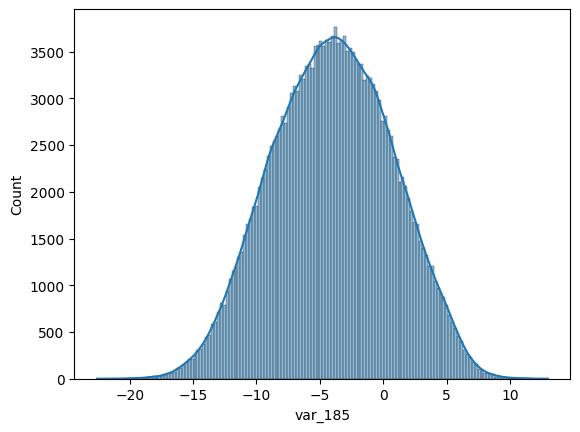

In [1312]:
sns.histplot(x = df["var_185"], kde=True)

In [1313]:
df.var_185.skew()

np.float64(-0.03573656300652506)

In [1314]:
df["var_185"] = df["var_185"].fillna(df["var_185"].mean())

<Axes: xlabel='var_186', ylabel='Count'>

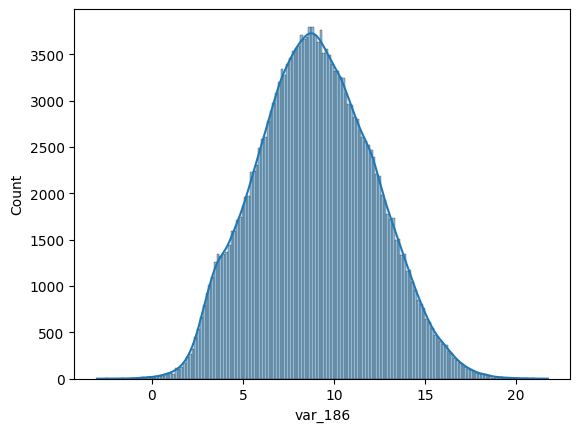

In [1315]:
sns.histplot(x = df["var_186"], kde=True)

In [1316]:
df.var_186.skew()

np.float64(0.10470179525909705)

In [1317]:
df["var_186"] = df["var_186"].fillna(df["var_186"].median())

In [1318]:
df.isnull().sum().sum()

np.int64(0)

### Boxplots for all numerical columns (in batches of 9)

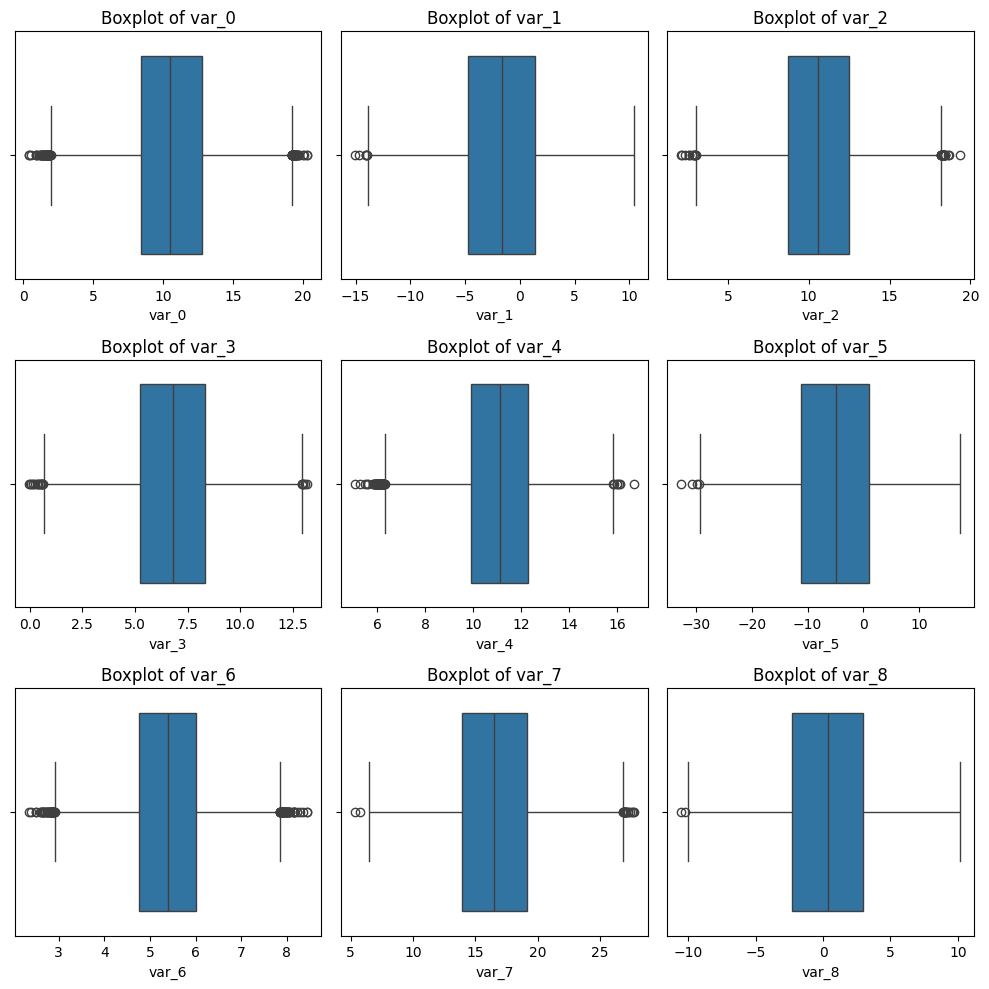

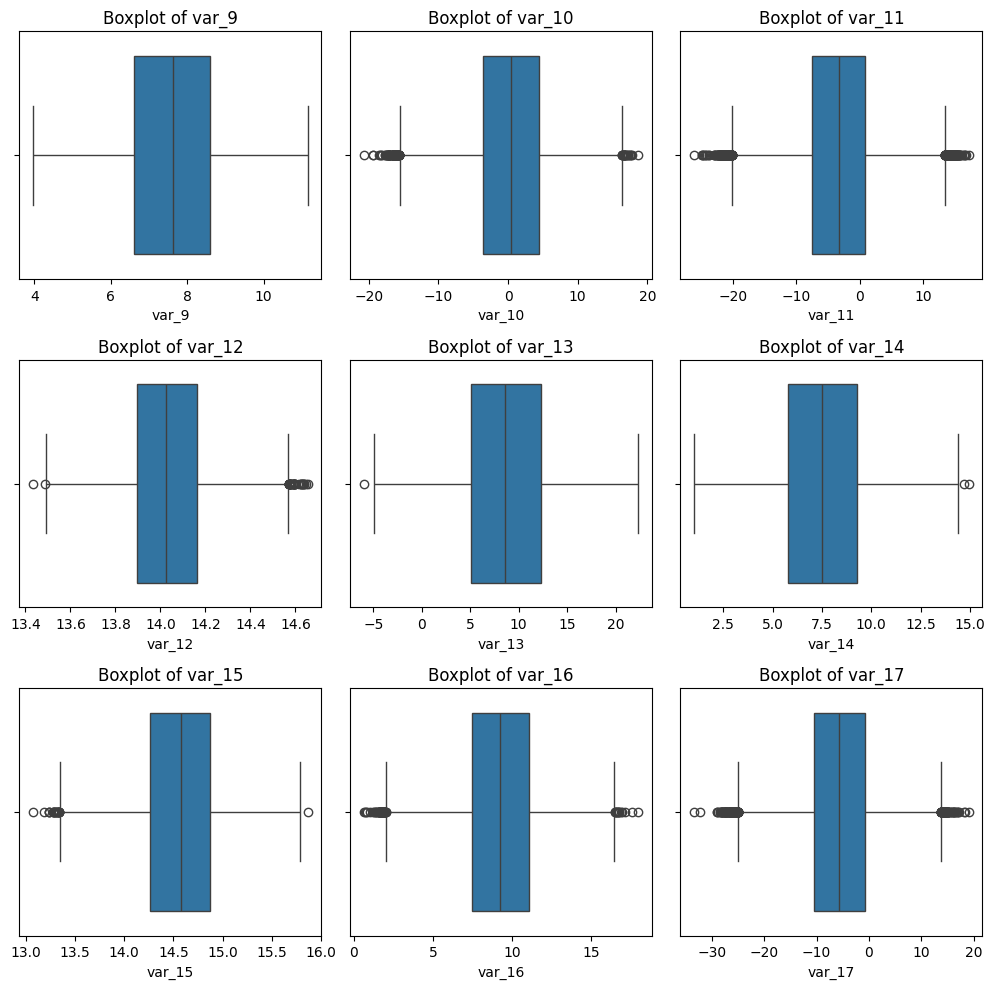

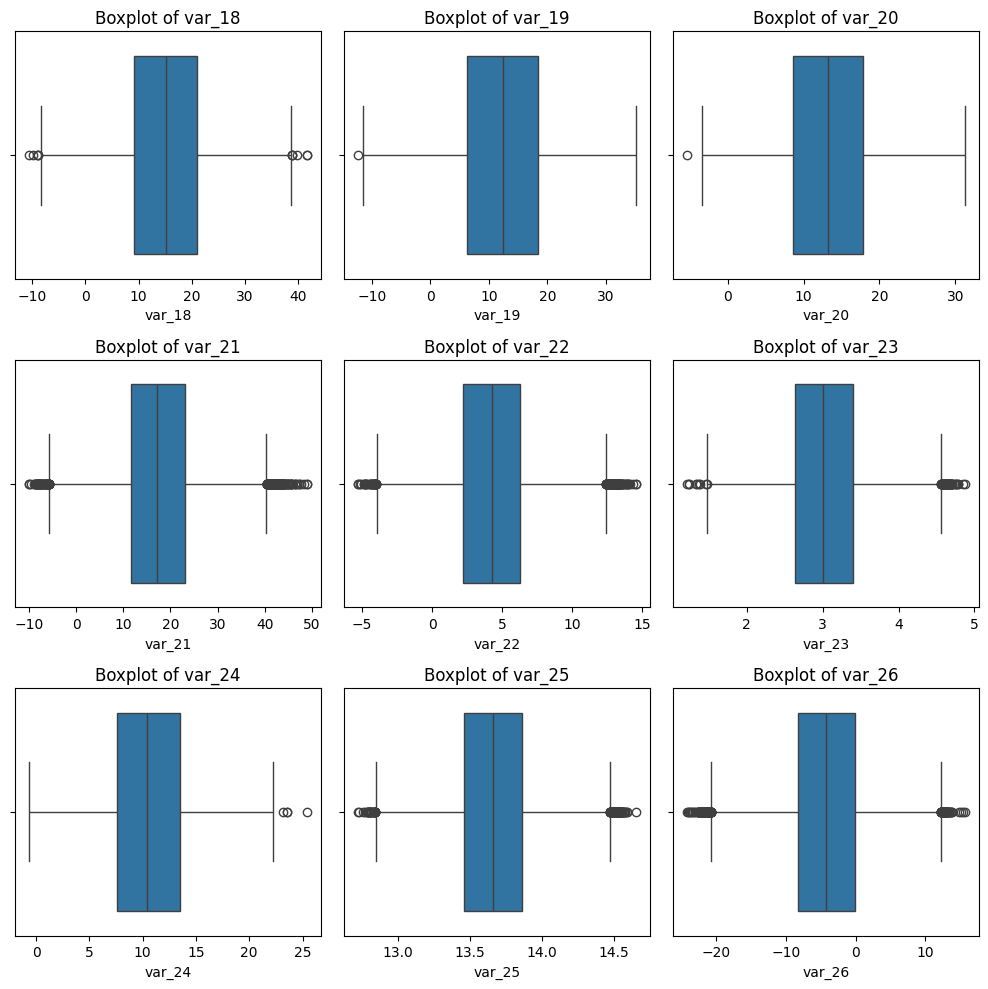

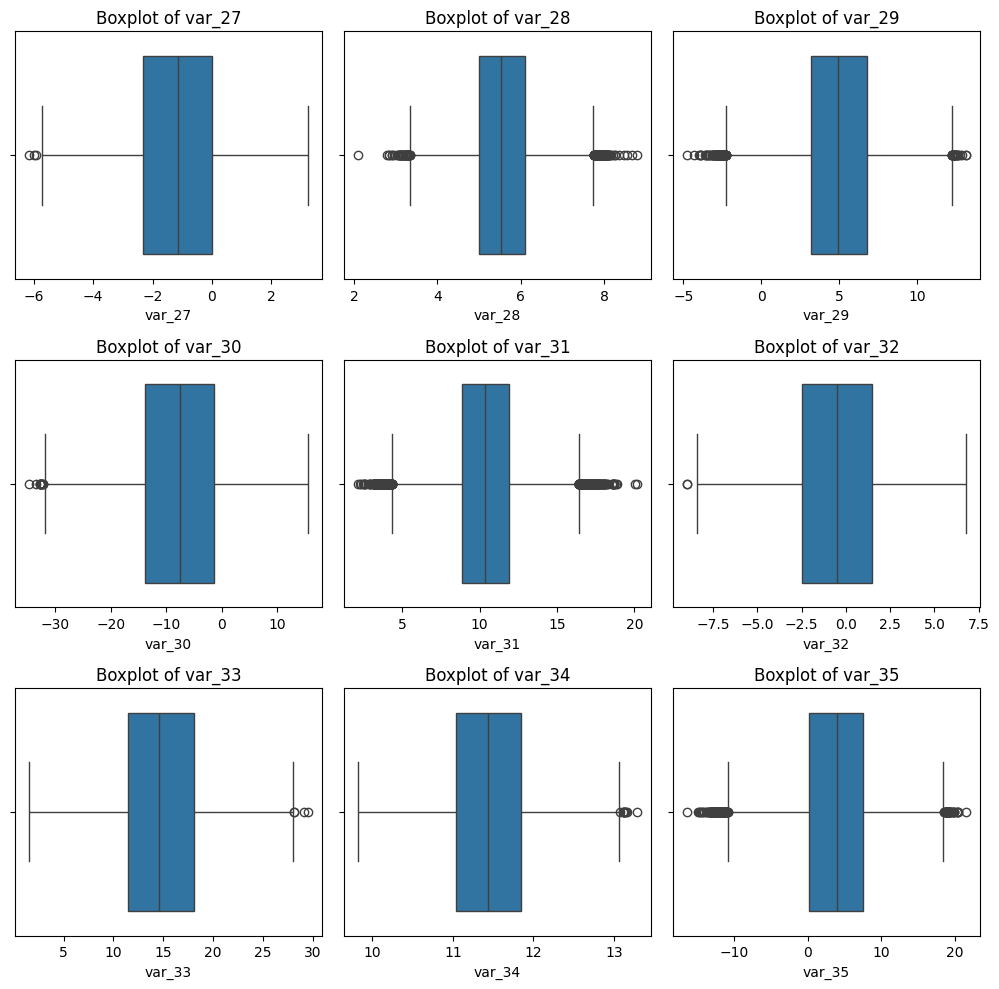

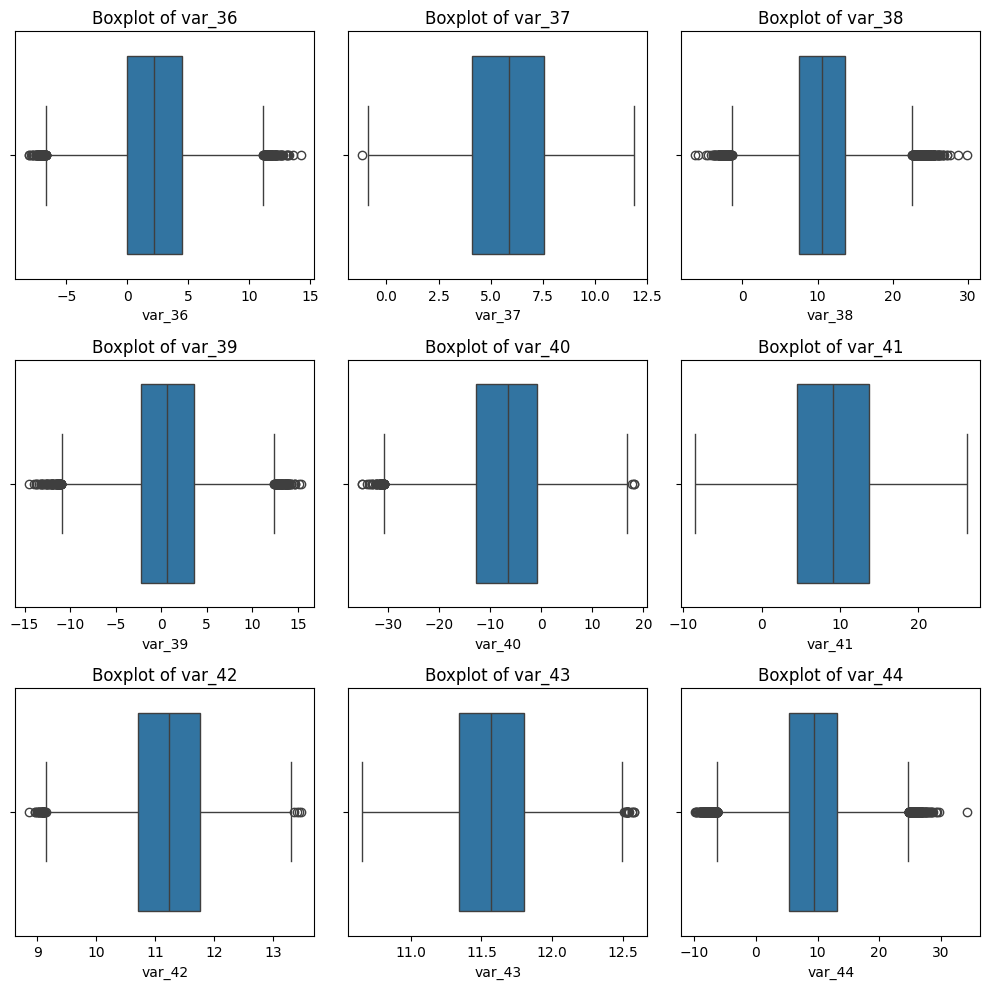

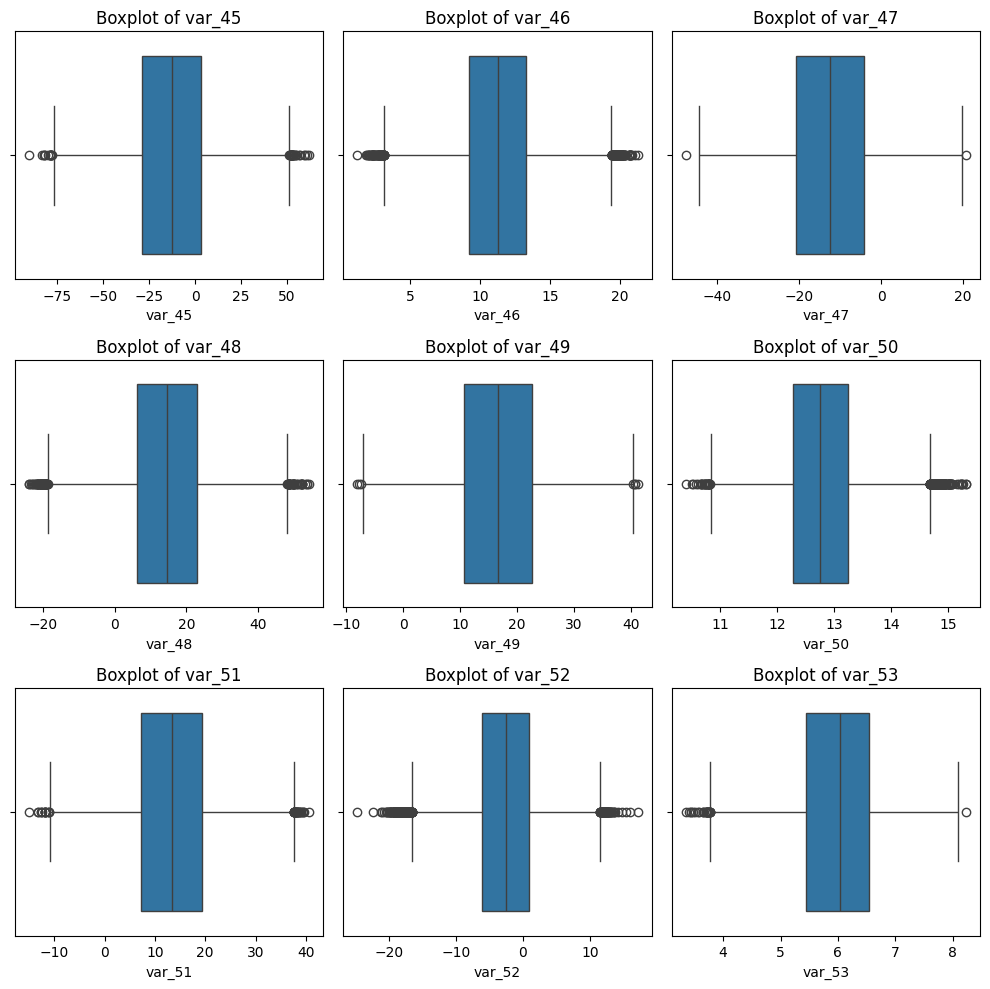

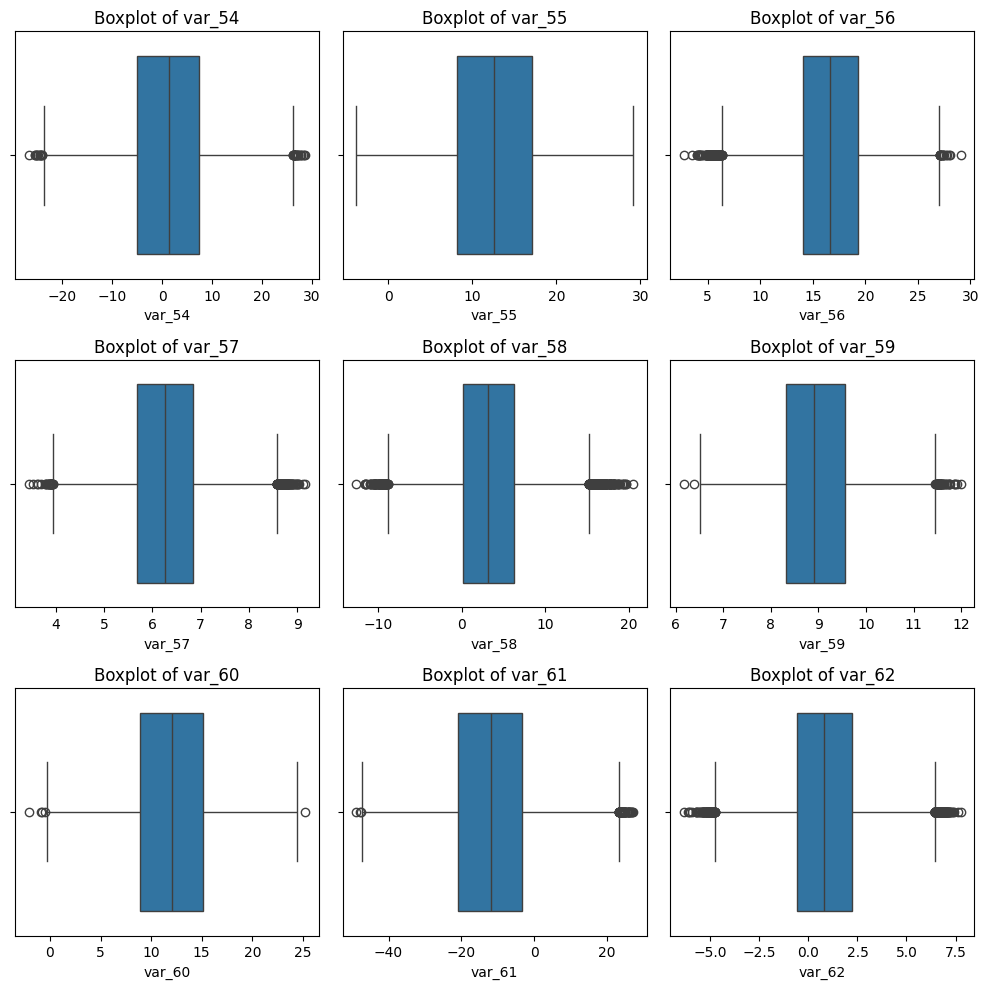

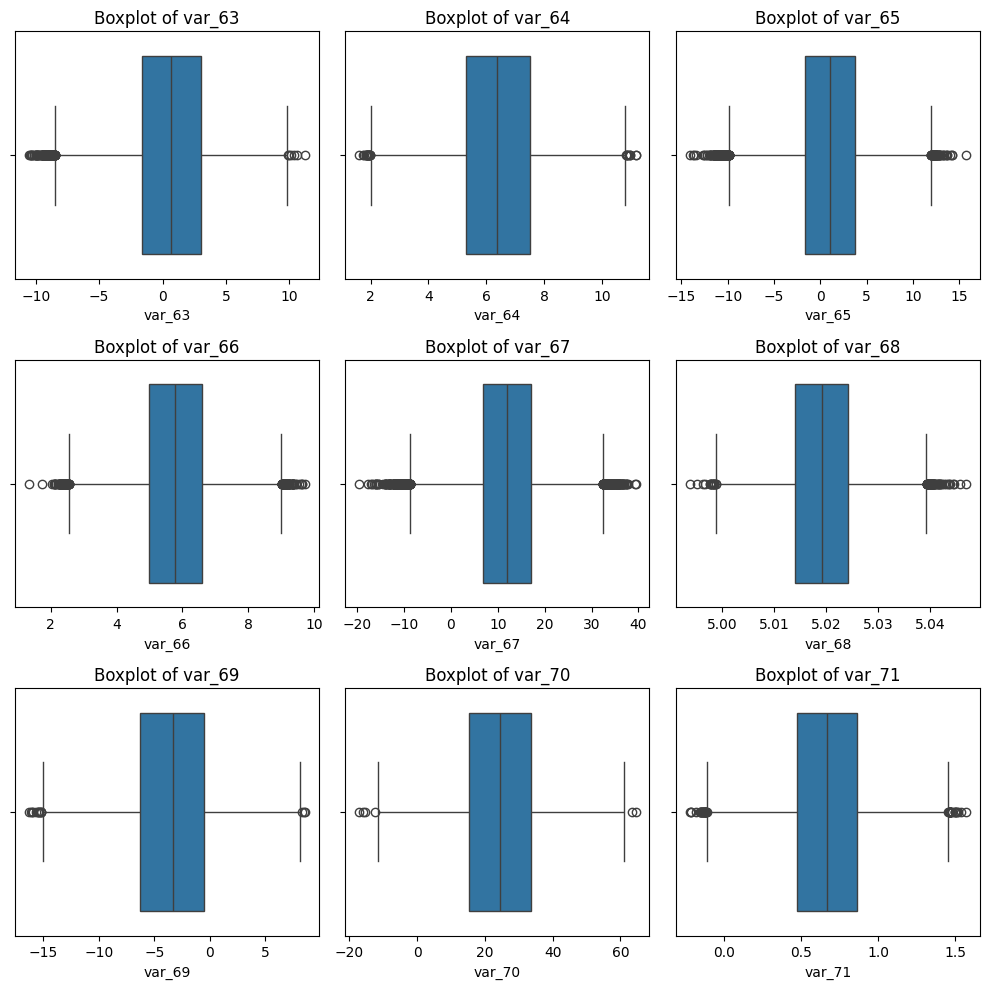

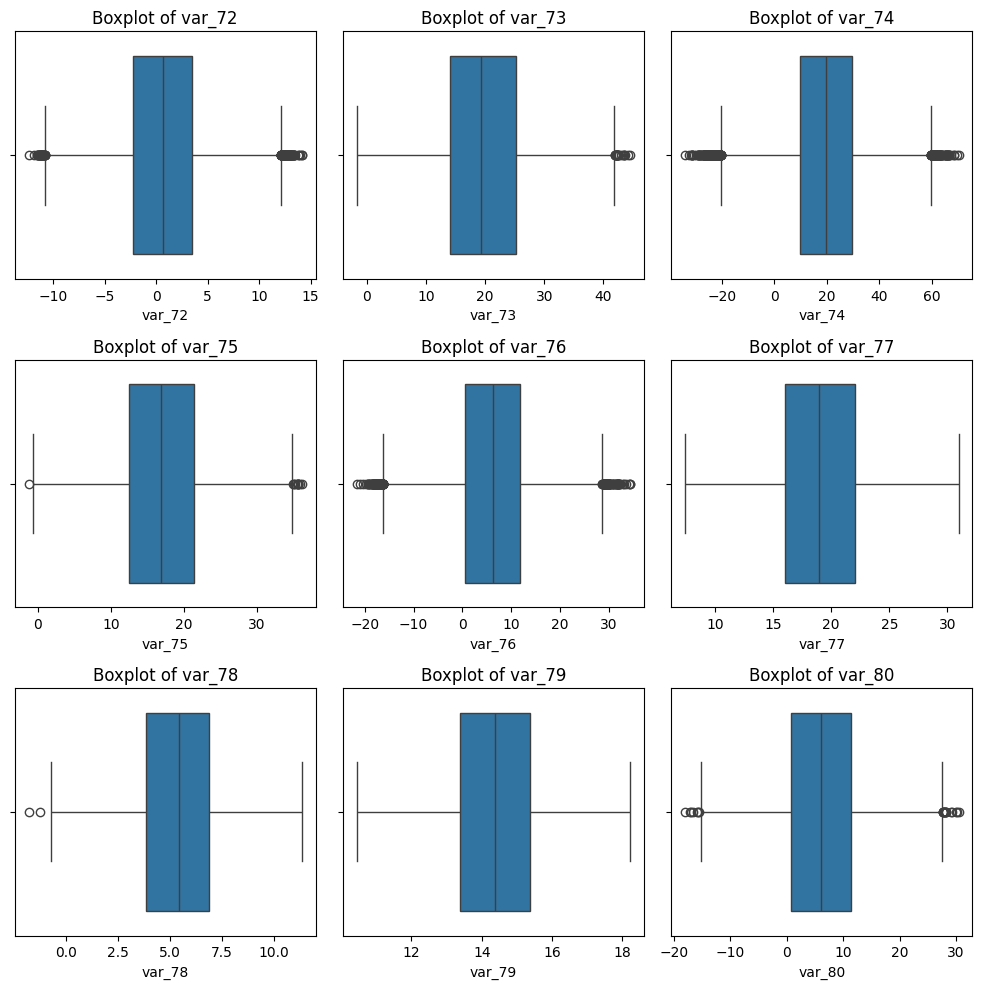

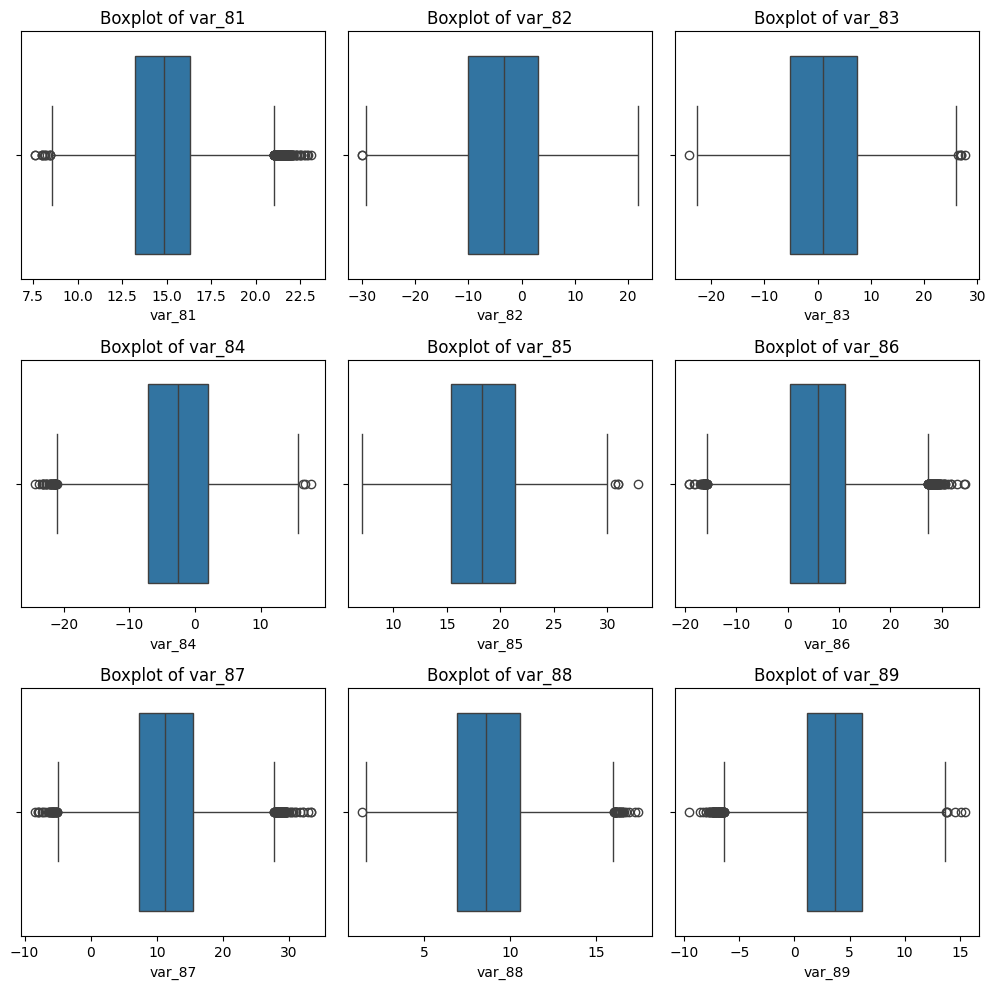

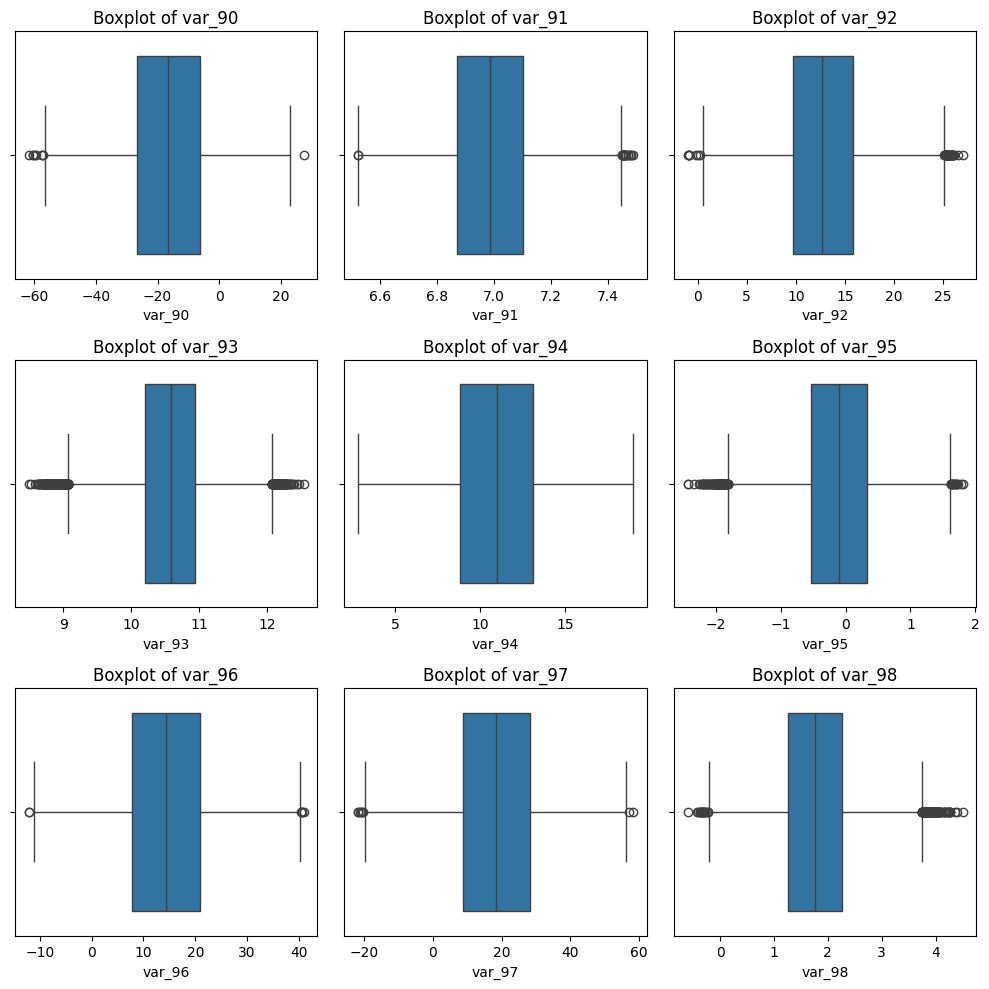

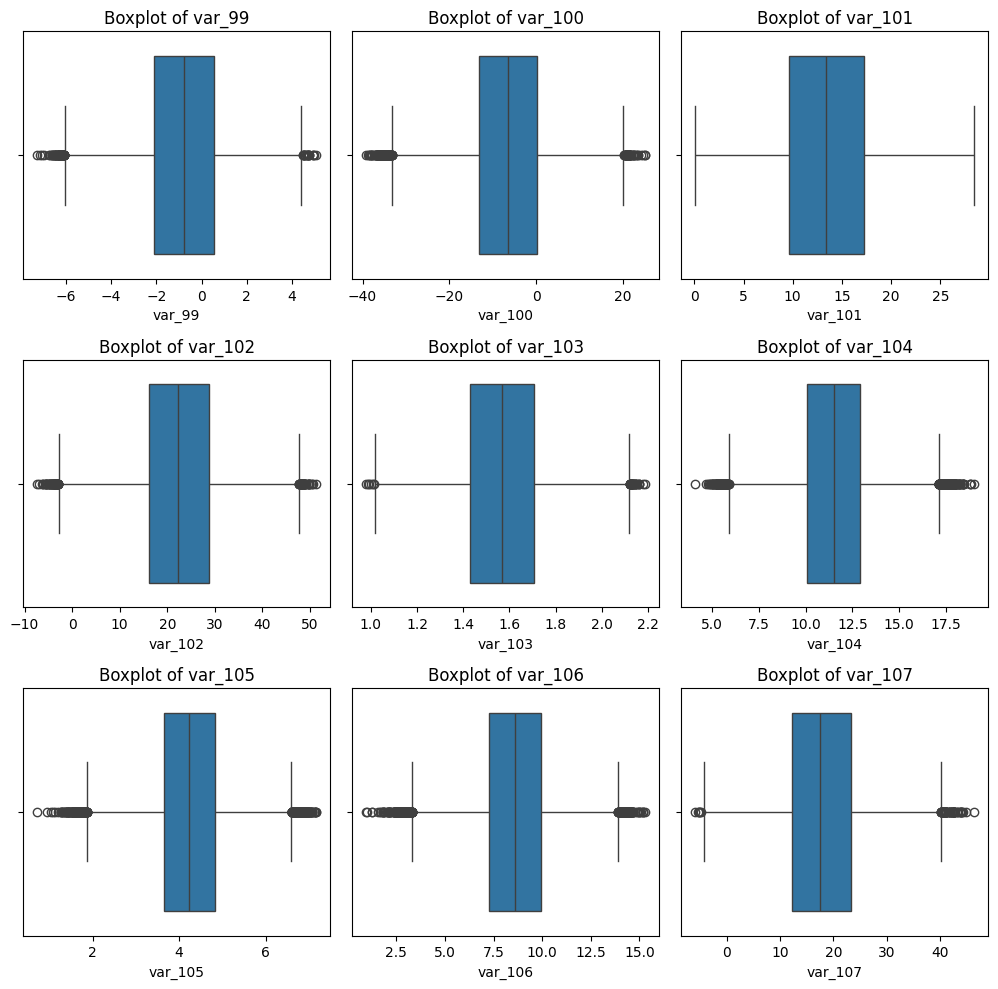

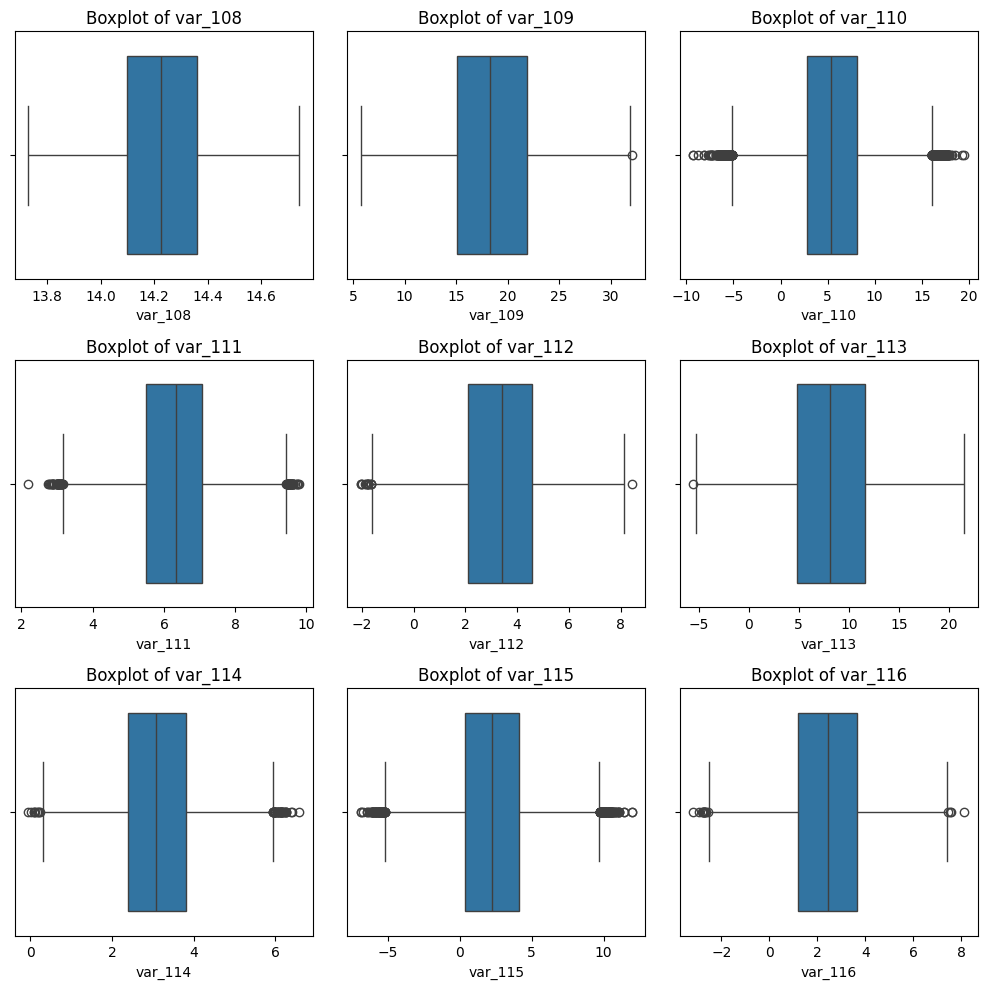

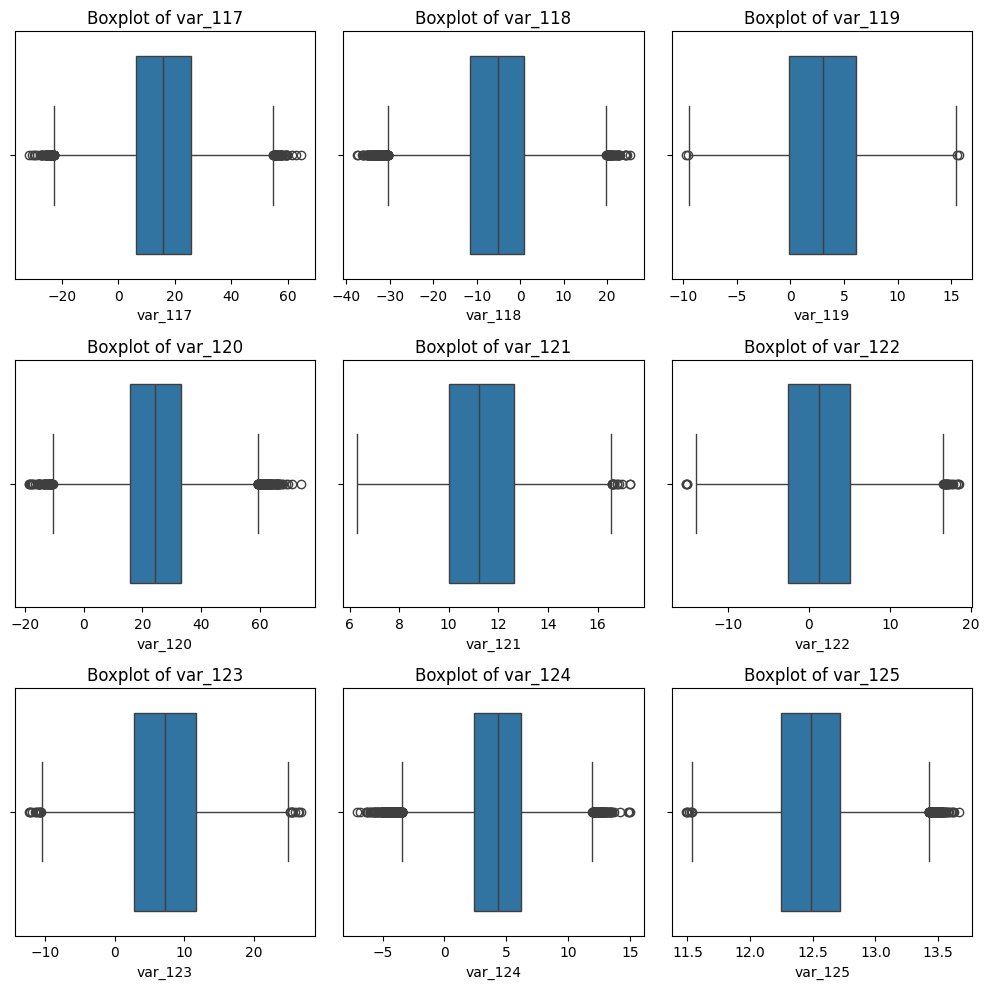

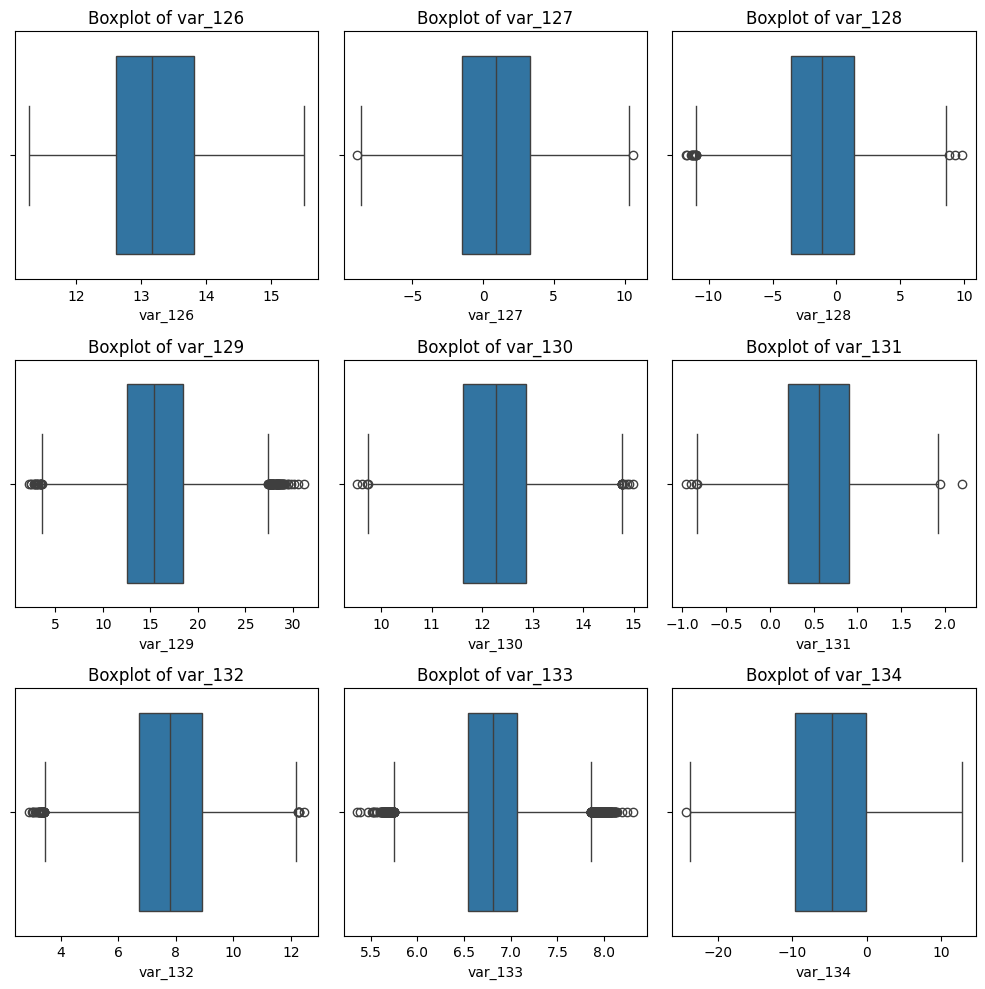

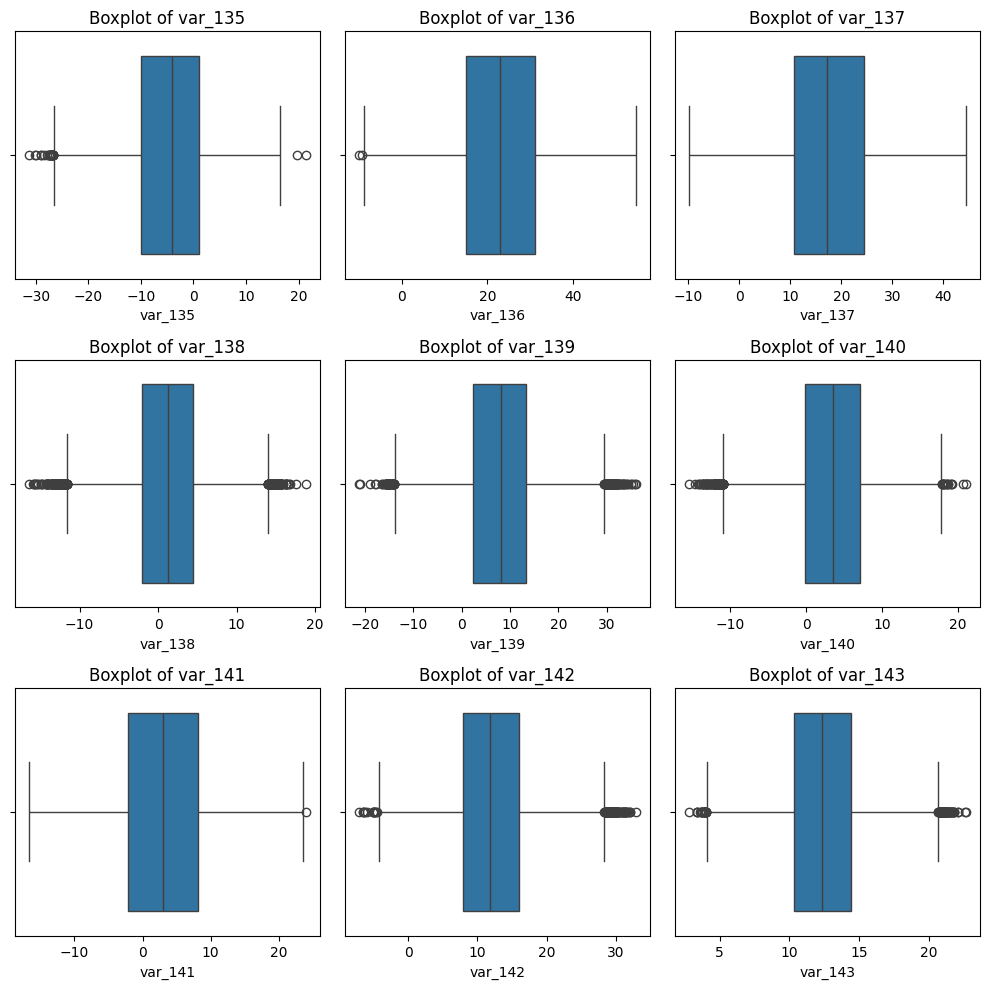

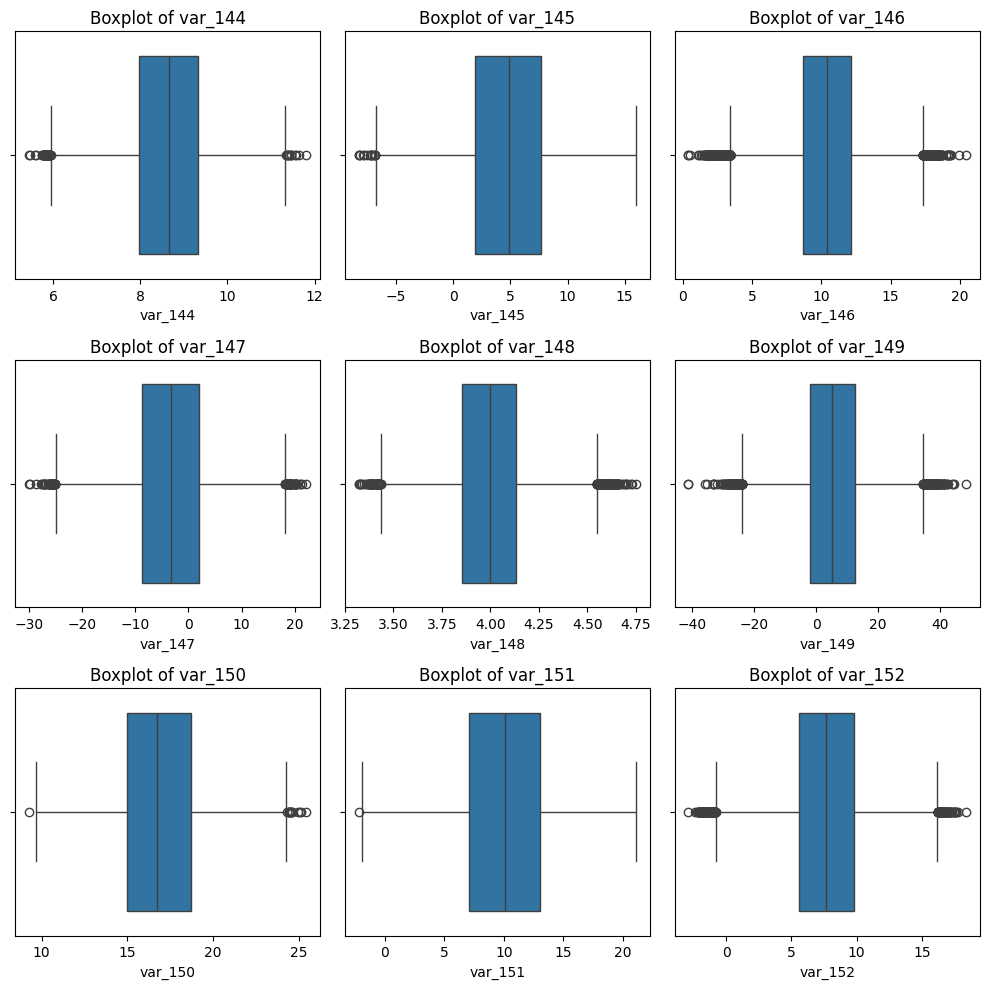

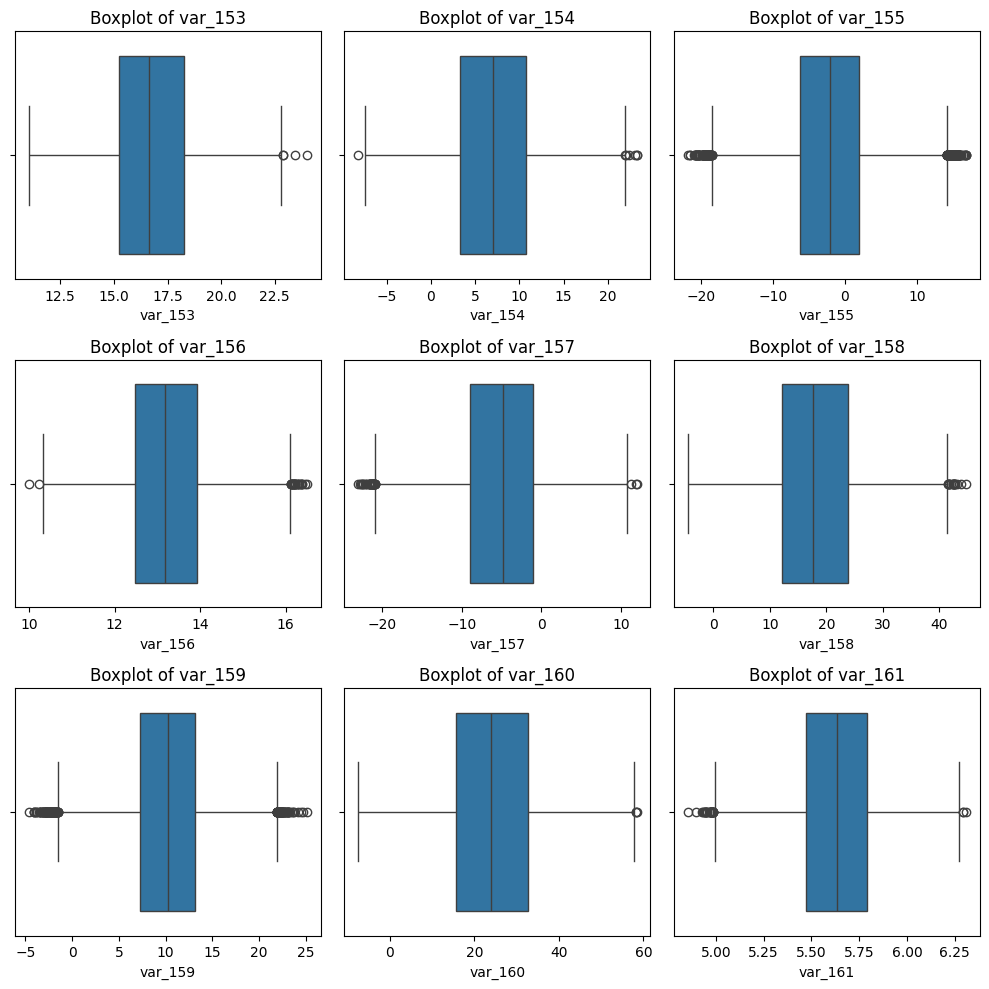

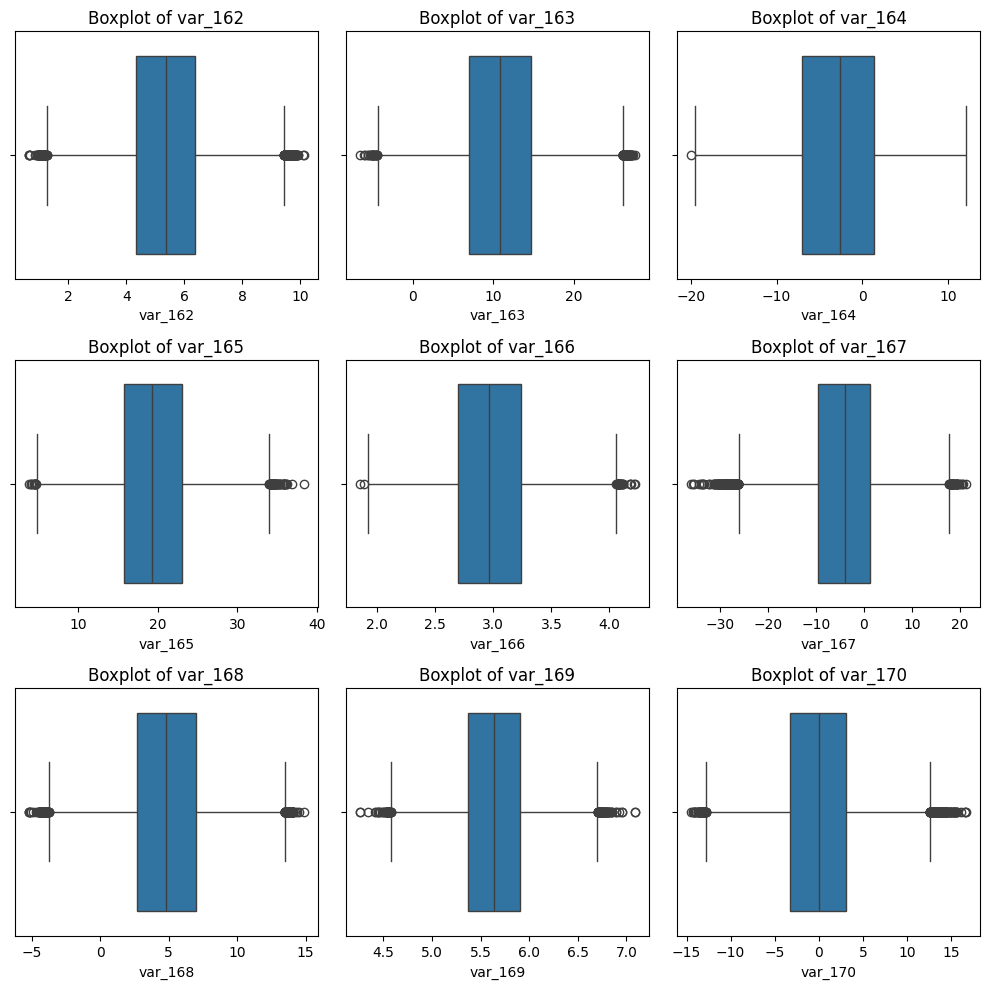

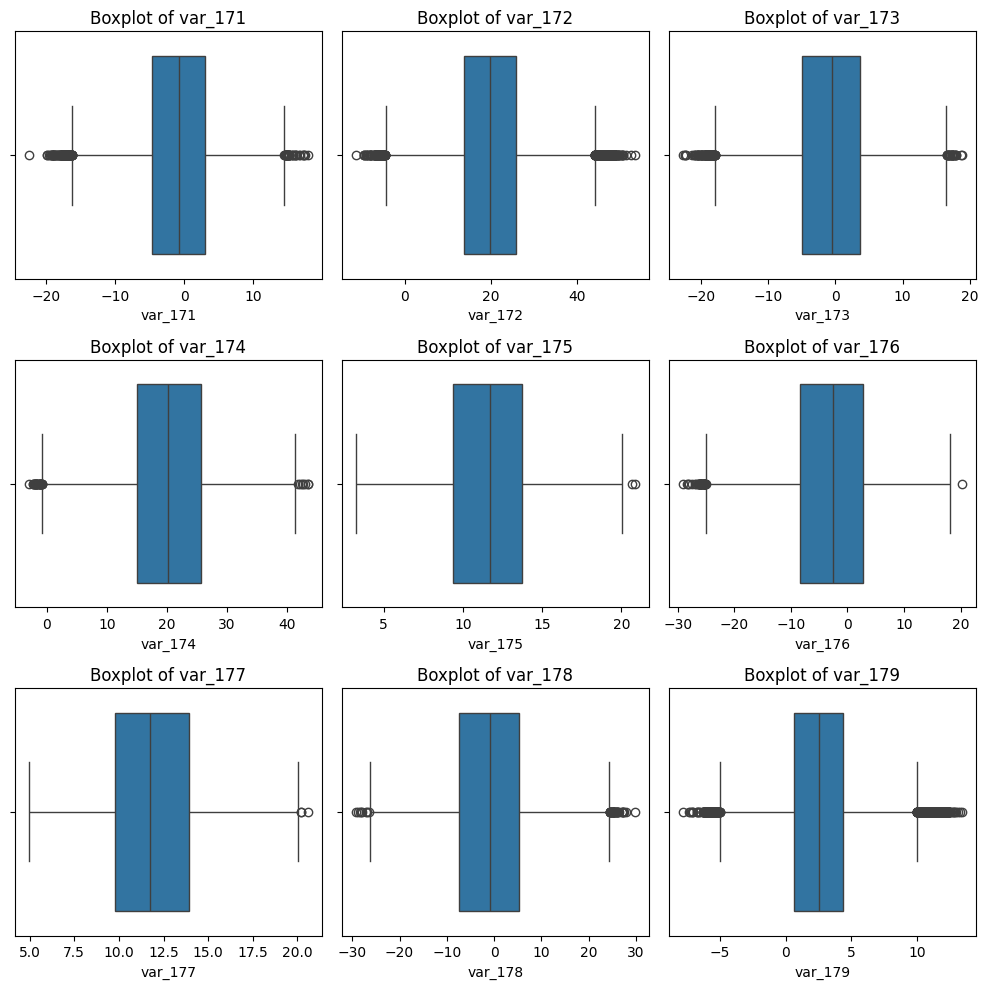

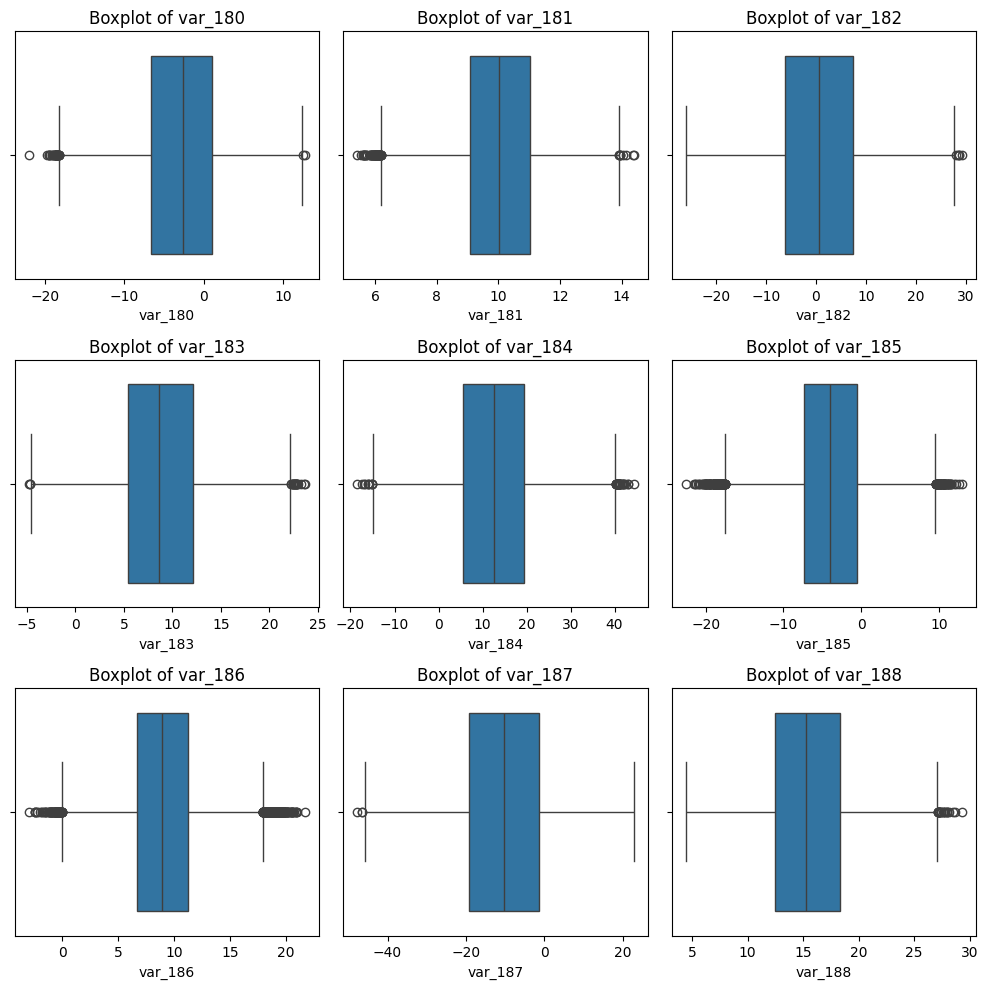

In [ ]:
num_cols = [col for col in df.columns if col.startswith('var_')]

for i in range(0, len(num_cols), 9):
  fig , axes = plt.subplots(3,3, figsize=(10,10))
  axes = axes.flatten()

  for j, col in enumerate(num_cols[i:i+9]):
    sns.boxplot(x=df[col], ax=axes[j])
    axes[j].set_title(f'Boxplot of {col}')
    axes[j].set_ylabel('')

  for k in range(j+1, len(axes)):
    fig.delaxes(axes[k])

  plt.tight_layout()
  plt.show()

In [ ]:
from scipy.stats.mstats import winsorize

num_cols = [col for col in df.columns if col not in ['ID_code', 'target']]

for col in num_cols:
    df[col] = winsorize(df[col], limits=[0.05, 0.05])

In [1321]:
 df[col] = winsorize(df[col], limits=(0.05,0.05))

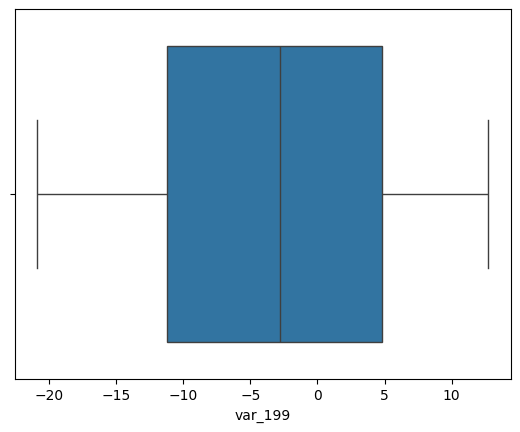

In [1322]:
sns.boxplot(x=df['var_199'])
plt.show()

<Axes: xlabel='target', ylabel='count'>

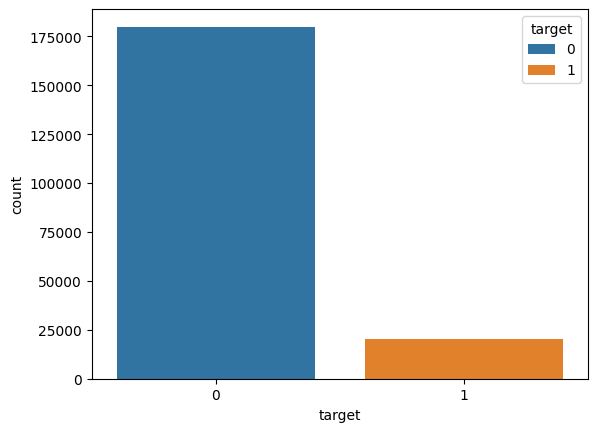

In [1323]:
sns.countplot(x='target',data =df, hue='target')

In [ ]:
df.target.value_counts().plot(
    kind='pie',
    autopct="%1.1f%%"
)
plt.ylabel('')
plt.title("Target Distribution")
plt.show()


# Observations

1. Class 0 → Represents 89.9% of the dataset.
 * Majority class → Customers who do not make a transaction.
 * This heavy imbalance means most records belong here.

2. Class 1 → Represents 10.1% of the dataset.
 * Minority class → Customers who do make a transaction.
 * Much smaller proportion compared to Class 0.

In [ ]:
x = df.drop(['target', 'ID_code'], axis=1)
y = df['target']

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [ ]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(max_iter=1000, class_weight='balanced')

print(f"Shape of x_train_scaled: {x_train_scaled.shape}")
print(f"Shape of y_train: {y_train.shape}")

log_reg.fit(x_train_scaled, y_train)
y_pred_lr = log_reg.predict(x_test_scaled)
y_prob_lr = log_reg.predict_log_proba(x_test_scaled)

In [908]:
y_pred_lr

array([0, 0, 0, ..., 0, 1, 0])

In [909]:
Log_accuracy = accuracy_score(y_test, y_pred_lr)
print("Accuracy :", Log_accuracy)

Log_precision = precision_score( y_test, y_pred_lr, average="weighted")
print("Precision :", Log_precision)

Log_recall = recall_score( y_test, y_pred_lr, average="weighted")
print("Recall :", Log_recall)

Log_f1 = f1_score(y_test, y_pred_lr, average="weighted")
print("F1 Score :", Log_f1)

Accuracy : 0.7738
Precision : 0.897787472295133
Recall : 0.7738
F1 Score : 0.8145911757628486


# Observation

The logistic regression model performed reasonably well, achieving an accuracy of about 77.38%. The precision is quite high at 0.8978, indicating that most of the predicted positive cases were correct. However, the recall matches the accuracy (0.7738), suggesting the model might be missing some true positives. The F1 score of 0.8146 shows a good balance between precision and recall, though there’s still room for improvement—perhaps through feature tuning or trying more complex models.

In [1327]:
cr = classification_report(y_test, y_pred_lr)
print("classification_report : ")
print(cr)

classification_report : 
              precision    recall  f1-score   support

           0       0.97      0.77      0.86     35980
           1       0.28      0.77      0.40      4020

    accuracy                           0.77     40000
   macro avg       0.62      0.77      0.63     40000
weighted avg       0.90      0.77      0.81     40000



# Observation

* The logistic regression model achieved an overall accuracy of 77%, which is consistent with the earlier metrics. For class 0, the model performs very well — precision (0.97) and F1-score (0.86) indicate strong reliability in identifying this class correctly. However, for class 1, the precision drops to 0.28, even though recall remains at 0.77, meaning the model is catching most of the actual positives but also misclassifying many negatives as positives.

* The macro average (0.63 F1-score) shows moderate balance across classes, while the weighted average (0.81 F1-score) reflects the dominance of class 0 in the dataset. Overall, the model seems biased toward the majority class, suggesting that techniques like class balancing or resampling could help improve performance on the minority class.

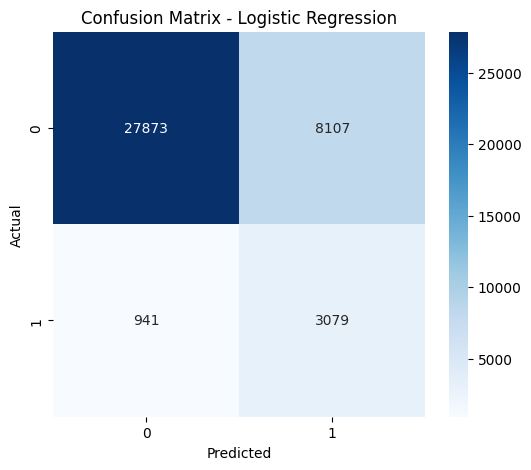

In [1328]:
cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")

plt.show()

# Observation

* The logistic regression model shows strong performance for class 0, correctly predicting 27,873 out of its total instances, but misclassifying 8,107 as class 1. For class 1, the model correctly identifies 3,079 cases while missing 941, which are incorrectly labeled as class 0.

* This pattern suggests the model is biased toward class 0, likely due to class imbalance in the dataset. While it captures most of the majority class accurately, it struggles more with the minority class. Improving this could involve techniques like SMOTE oversampling, class weighting, or threshold tuning to enhance recall for class 1.

In [ ]:
# RandomForestClassifier
rf = RandomForestClassifier(n_estimators = 100, max_depth = 5, class_weight = 'balanced', random_state = 42)
rf.fit(x_train_scaled, y_train)
y_pred_rf = rf.predict(x_test_scaled)

In [1330]:
y_pred_rf

array([0, 0, 0, ..., 0, 0, 0])

In [1331]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)
print('Accuracy:', rf_accuracy)

rf_precision = precision_score(y_test, y_pred_rf)
print('Prision:', rf_precision)

rf_recall = recall_score(y_test, y_pred_rf)
print('Recall:', rf_recall)

rf_f1 = f1_score(y_test, y_pred_rf)
print('F1_score:', rf_f1)

Accuracy: 0.754175
Prision: 0.23120318135577544
Recall: 0.6218905472636815
F1_score: 0.3370862266567788


# Observation

The Random Forest Classifier achieved an accuracy of about 75.4%, which is slightly lower than the logistic regression model’s performance. The precision (0.23) is quite low, indicating that many of the positive predictions were incorrect. However, the recall (0.62) is better, meaning the model successfully identified a fair portion of actual positives. The F1 score (0.34) reflects this imbalance — the model is prioritizing recall over precision.

In [1332]:
cr = classification_report(y_test, y_pred_rf)
print("classification_report : ")
print(cr)

classification_report : 
              precision    recall  f1-score   support

           0       0.95      0.77      0.85     35980
           1       0.23      0.62      0.34      4020

    accuracy                           0.75     40000
   macro avg       0.59      0.70      0.59     40000
weighted avg       0.88      0.75      0.80     40000



# Observation

* The Random Forest model achieved an overall accuracy of 75%, which is decent but slightly lower than the logistic regression model’s performance. For class 0, the model performs strongly — precision (0.95) and F1-score (0.85) show that it predicts the majority class quite accurately. However, for class 1, the precision (0.23) is very low, even though recall (0.62) is moderate, meaning the model identifies many true positives but also generates a lot of false positives.

* The macro average F1-score (0.59) indicates uneven performance across classes, while the weighted average (0.80) reflects the dominance of class 0 in the dataset. This imbalance suggests the model is favoring the majority class, a common issue in imbalanced datasets. Techniques like SMOTE oversampling, class weighting, or ensemble tuning could help improve minority class performance.

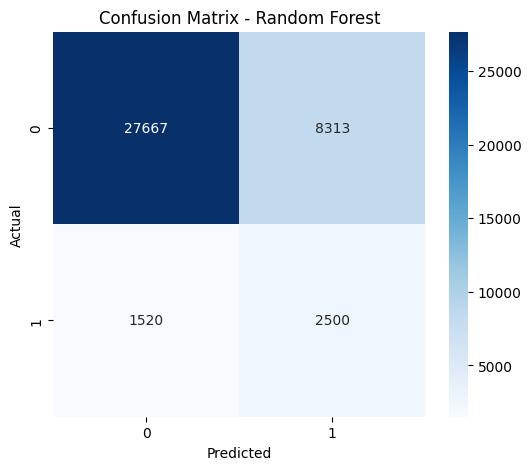

In [1333]:
cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Random Forest")

plt.show()

# Observation

* The Random Forest model shows strong performance for class 0, correctly predicting 27,667 instances while misclassifying 8,313 as class 1. For class 1, it correctly identifies 2,500 cases but misses 1,520, which are incorrectly predicted as class 0.

* This pattern indicates that the model is still biased toward the majority class (class 0), similar to the logistic regression results. While recall for class 1 has improved slightly compared to logistic regression, precision remains low — meaning the model tends to overpredict positives. To improve this, you could explore hyperparameter tuning, class balancing techniques, or threshold adjustment to achieve a better trade-off between precision and recall.

In [ ]:
# XGBClassifier
xgb = XGBClassifier(n_estimators = 100, max_depth = 5, learning_rate = 0.1, random_state = 42)
xgb.fit(x_train_scaled, y_train)
y_pred_xgb = xgb.predict(x_test_scaled)

In [1335]:
y_pred_xgb

array([0, 0, 0, ..., 0, 0, 0])

In [1336]:
xgb_accuracy = accuracy_score(y_test, y_pred_xgb)
print('Accuracy:', xgb_accuracy)

xgb_precision = precision_score(y_test, y_pred_xgb)
print('Prision:', xgb_precision)

xgb_recall = recall_score(y_test, y_pred_xgb)
print('Recall:', xgb_recall)

xgb_f1 = f1_score(y_test, y_pred_xgb)
print('F1_score:', xgb_f1)

Accuracy: 0.905175
Prision: 0.8580441640378549
Recall: 0.06766169154228856
F1_score: 0.12543232649296748


# Observation

* The XGBoost classifier achieved an impressive accuracy of about 90.5%, which looks strong at first glance. However, the recall (0.0677) and F1-score (0.1254) are extremely low, indicating that the model is failing to identify most of the positive cases. The precision (0.8580) is high, meaning that when the model does predict a positive, it’s usually correct — but it rarely makes those predictions.

* This imbalance suggests the model is overly conservative, likely predicting the majority class most of the time. It’s a classic case of high accuracy but poor minority class detection, often seen in imbalanced datasets. You could improve this by adjusting the classification threshold, using class weighting, or applying resampling techniques to balance the dataset.

In [1337]:
cr = classification_report(y_test, y_pred_xgb)
print("classification_report : ")
print(cr)

classification_report : 
              precision    recall  f1-score   support

           0       0.91      1.00      0.95     35980
           1       0.86      0.07      0.13      4020

    accuracy                           0.91     40000
   macro avg       0.88      0.53      0.54     40000
weighted avg       0.90      0.91      0.87     40000



# Observation

The XGBoost model achieved a strong overall accuracy of 91%, but the detailed breakdown reveals a clear imbalance in performance between the two classes. For class 0, the model performs exceptionally well — recall (1.00) and F1-score (0.95) show near-perfect predictions. However, for class 1, the recall (0.07) and F1-score (0.13) are very poor, meaning the model is missing most of the positive cases.

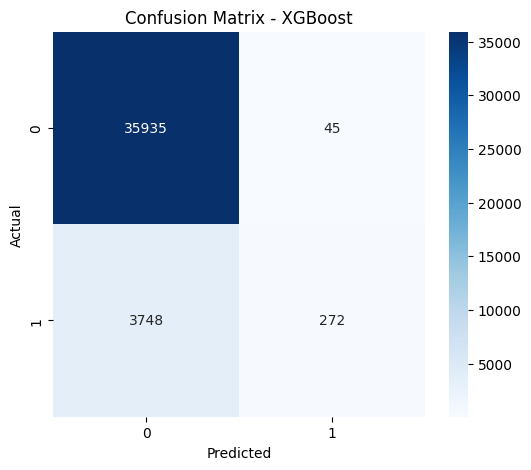

In [1338]:
cm = confusion_matrix(y_test, y_pred_lg)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - XGBLogistic Rgression")

plt.show()

# Observation

* The XGBoost model demonstrates very strong performance for class 0, correctly predicting 35,935 instances and misclassifying only 45. However, for class 1, it correctly identifies just 272 cases while misclassifying 3,748 as class 0.

* This pattern shows that the model is heavily skewed toward predicting class 0, which aligns with the earlier metrics — high accuracy but poor recall for the minority class. Essentially, the model is excellent at recognizing negatives but struggles to detect positives. This imbalance likely stems from unequal class distribution in the dataset.

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score

Models = pd.DataFrame({
    'Model' : ['Logistic Regression', 'Random Forest', 'XGBoost'],
    'Accuracy' : [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_xgb)
        ],
    "F1 Score" : [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_xgb)
        ],

    "Precision" : [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_xgb)
        ],

    "Recall" : [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_xgb)
        ],
    "ROC-AUC" : [
        roc_auc_score(y_test, y_pred_lr),
        roc_auc_score(y_test, y_pred_rf),
        roc_auc_score(y_test, y_pred_xgb)
        ]
})

In [ ]:
print(Models)

In [ ]:
results_df = Models.sort_values(
    by= ["F1 Score"],
    ascending=False
)

In [1342]:
results_df.reset_index(inplace=True)
results_df

,index,Model,Accuracy,F1 Score,Precision,Recall,ROC-AUC
0,0,Logistic Regression,0.773800,0.404972,0.275255,0.765920,0.770300
1,1,Random Forest,0.754175,0.337086,0.231203,0.621891,0.695423
2,2,XGBoost,0.905175,0.125432,0.858044,0.067662,0.533205


In [1343]:
best_model_name = results_df.iloc[0]['Model']
best_model_name

'Logistic Regression'

In [1344]:
param_grid = {
    "C" : [0.001, 0.01, 0.1, 1, 10, 100, 1000],
    "penalty" : ["l1", "l2"],
    "solver" : ["liblinear"]
}

n_estimators :
--------------
Why trees 100, 200, If We take More trees can improve accuracy, but too many trees increase training time and may lead to overfitting.          

max_depth :
-----------
Why the depth 3, 5, 7. If we give Smaller depth → Simpler model and for Larger depth → More complex model.

learning_rate :
---------------
why learning_rate 0.01, 0.1, If 0.01 → Learns slowly as 0.1 → Learns faster, A very high learning rate can miss the best solution.

subsample :
-----------
why subsample 0.8 (80% of training data), 1.0 (100% of training data) Using only part of the data can reduce overfitting.

In [1350]:
grid = GridSearchCV(
    estimator=LogisticRegression(
        class_weight='balanced',
        random_state=42
        ),
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid.fit(x_train_scaled, y_train)

GridSearchCV(cv=5,
             estimator=LogisticRegression(class_weight='balanced',
                                          random_state=42),
             n_jobs=-1,
             param_grid={'C': [0.001, 0.01, 0.1, 1, 10, 100, 1000],
                         'penalty': ['l1', 'l2'], 'solver': ['liblinear']},
             scoring='f1')

In [1351]:
print("Best Parameters:")
print(grid.best_params_)

Best Parameters:
{'C': 1000, 'penalty': 'l2', 'solver': 'liblinear'}


In [1352]:
print("Best Cross Validation F1 Score:")
print(grid.best_score_)

Best Cross Validation F1 Score:
0.40347252122033306


# Observation

The model achieved a best cross-validation F1 Score of about 40.%, which is an excellent result. This means that during the tuning process, the model consistently performed well across different data splits, showing strong generalization capability. Such a high score suggests that the chosen hyperparameters are well-optimized and the model is capturing meaningful patterns in the data without overfitting.

In [1353]:
best_lg = grid.best_estimator_

best_pred = best_lg.predict(x_test_scaled)

In [1354]:
best_pred

array([0, 0, 0, ..., 0, 1, 0])

In [1355]:
print("Accuracy :", accuracy_score(y_test, best_pred))
print("Precision :", precision_score(y_test, best_pred, average="weighted"))
print("Recall :", recall_score(y_test, best_pred, average="weighted"))
print("F1 Score :", f1_score(y_test, best_pred, average="weighted"))

Accuracy : 0.7738
Precision : 0.897787472295133
Recall : 0.7738
F1 Score : 0.8145911757628486


# Challenges Faced
* High Dimensionality :
 The dataset had 200 anonymized features, which made it hard to interpret and increased the risk of overfitting. To handle this, I used dimensionality reduction (PCA) and feature scaling. This helped reduce noise and kept the models efficient without losing too much predictive power.

* Class Imbalance :
 The target column was skewed, with far fewer customers labeled as “1” (transaction). This imbalance caused models to favor predicting “0.” To address it, I applied SMOTE oversampling and class weights in algorithms like Logistic Regression and Random Forest. These techniques improved recall and gave the minority class more representation.

* Anonymized Features :
 Since feature names weren’t provided, I couldn’t draw domain insights or explain feature importance clearly. Instead, I focused on model performance metrics like accuracy, precision, recall, and F1‑score. This shifted the emphasis from interpretability to predictive strength.

* Overfitting Risk :
 Models like XGBoost showed very high accuracy but poor recall, meaning they were memorizing majority class patterns. To prevent this, I used cross‑validation, regularization, and early stopping. These steps helped the models generalize better to unseen data.

* Threshold Sensitivity :
 Default probability thresholds led to poor recall for the minority class. By adjusting thresholds and analyzing ROC‑AUC curves, I was able to balance precision and recall, making the models more sensitive to detecting transactions.

# Conclusion
The biggest hurdles were imbalanced data, anonymized features, and high dimensionality. By applying resampling, dimensionality reduction, threshold tuning, and regularization, the models became more reliable and better suited for production use.